In [2]:

# ============================================================
# NOTEBOOK 06: PORTFOLIO ANALYSIS & EXPLORATORY DATA ANALYSIS
# Project: Freddie Mac Credit Portfolio Risk Modeling
# ============================================================

# 1. Import libraries
import sys
import gc
import time
import warnings

from pathlib import Path

import duckdb
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# 2. Project configuration
PROJECT_ROOT = Path(
    r"D:\DS Project\credit-portfolio-risk-modeling"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# 3. Import project paths
from config.paths import DUCKDB_TEMP_DIR

# 4. Analytical data directories
EDA_DIR = Path(
    r"E:\DS_project_backup\credit-risk-portfolio\processed\eda"
)

EDA_DATA_DIR = EDA_DIR / "loan_level"

EDA_TABLE_DIR = EDA_DIR / "tables"

EDA_CHART_DIR = EDA_DIR / "charts"

# 5. Notebook 06 output directories
NOTEBOOK_06_DIR = EDA_DIR / "notebook_06"

TABLE_DIR = NOTEBOOK_06_DIR / "tables"

CHART_DIR = NOTEBOOK_06_DIR / "charts"

for folder in [
    NOTEBOOK_06_DIR,
    TABLE_DIR,
    CHART_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# 6. Vintage configuration
VINTAGES = [
    f"{year}Q{quarter}"
    for year in range(2006, 2013)
    for quarter in range(1, 5)
]

EXPECTED_VINTAGES = 28

EXPECTED_LOANS = 11_128_442

# 7. Cleaned analytical files
CLEAN_FILES = sorted(
    EDA_DATA_DIR.glob("loan_level_clean_v2_*.parquet")
)

CLEAN_FILES = [
    f for f in CLEAN_FILES
    if "_test_" not in f.stem
]

CLEAN_FILE_PATHS = [
    str(f) for f in CLEAN_FILES
]

# 8. Validate input files
assert len(CLEAN_FILES) == EXPECTED_VINTAGES, (
    f"Expected {EXPECTED_VINTAGES} cleaned files, "
    f"found {len(CLEAN_FILES)}"
)

missing_vintages = [
    vintage
    for vintage in VINTAGES
    if not (
        EDA_DATA_DIR
        / f"loan_level_clean_v2_{vintage}.parquet"
    ).exists()
]

assert len(missing_vintages) == 0, (
    f"Missing vintages: {missing_vintages}"
)

# 9. Initialize DuckDB
con = duckdb.connect()

con.execute("SET memory_limit='3GB'")
con.execute("SET threads=2")
con.execute("SET preserve_insertion_order=false")

temp_path = (
    DUCKDB_TEMP_DIR
    .as_posix()
    .replace("'", "''")
)

con.execute(
    f"SET temp_directory='{temp_path}'"
)

# 10. Dataset metadata
total_file_size_gb = sum(
    f.stat().st_size for f in CLEAN_FILES
) / 1024**3

print("=" * 65)
print("NOTEBOOK 06 — PORTFOLIO ANALYSIS & EDA")
print("=" * 65)

print(f"Project root: {PROJECT_ROOT}")
print(f"Input directory: {EDA_DATA_DIR}")
print(f"Output directory: {NOTEBOOK_06_DIR}")

print("-" * 65)

print(f"Number of vintages: {len(CLEAN_FILES)}")
print(f"Expected loans: {EXPECTED_LOANS:,}")
print(f"Total input size: {total_file_size_gb:.2f} GB")

print("-" * 65)

print("DuckDB version:", duckdb.__version__)
print("DuckDB memory limit: 3 GB")
print("DuckDB threads: 2")

print("-" * 65)

print("All 28 cleaned vintage files found.")
print("Environment setup completed successfully.")


NOTEBOOK 06 — PORTFOLIO ANALYSIS & EDA
Project root: D:\DS Project\credit-portfolio-risk-modeling
Input directory: E:\DS_project_backup\credit-risk-portfolio\processed\eda\loan_level
Output directory: E:\DS_project_backup\credit-risk-portfolio\processed\eda\notebook_06
-----------------------------------------------------------------
Number of vintages: 28
Expected loans: 11,128,442
Total input size: 0.25 GB
-----------------------------------------------------------------
DuckDB version: 2.0.0
DuckDB memory limit: 3 GB
DuckDB threads: 2
-----------------------------------------------------------------
All 28 cleaned vintage files found.
Environment setup completed successfully.


In [3]:

# ============================================================
# CELL 2 — DATASET SCHEMA & PORTFOLIO INTEGRITY VALIDATION
# ============================================================

# 1. Inspect schema of one cleaned file
sample_file = CLEAN_FILES[-1]

schema_df = con.execute("""
    DESCRIBE
    SELECT *
    FROM read_parquet(?)
""", [str(sample_file)]).df()

print("=" * 65)
print("DATASET SCHEMA")
print("=" * 65)

print(schema_df.to_string(index=False))

# 2. Define required analytical variables
required_columns = [
    "loan_identifier",
    "vintage",
    "original_upb_num",
    "classic_fico_num",
    "original_dti_num",
    "original_ltv_num",
    "original_cltv_num",
    "original_interest_rate_num",
    "original_loan_term_num",
    "harp_indicator",
    "ever_30dpd",
    "ever_60dpd",
    "ever_90dpd",
    "ever_reo",
    "credit_related_termination",
    "actual_loss",
    "ltv_outside_guide_range",
    "cltv_outside_guide_range",
    "harp_oltv_inconsistency",
    "harp_ltv_extreme",
    "harp_cltv_extreme"
]

available_columns = schema_df["column_name"].tolist()

missing_columns = [
    col for col in required_columns
    if col not in available_columns
]

print("\n" + "=" * 65)
print("REQUIRED COLUMN VALIDATION")
print("=" * 65)

print("Required columns:", len(required_columns))
print("Missing columns:", missing_columns)

assert len(missing_columns) == 0, (
    f"Missing required columns: {missing_columns}"
)

# 3. Validate portfolio-level counts
portfolio_integrity = con.execute("""
    SELECT
        COUNT(*) AS total_loans,
        COUNT(DISTINCT loan_identifier) AS unique_loan_ids,
        COUNT(DISTINCT vintage) AS number_of_vintages,

        COUNT(*) FILTER (
            WHERE loan_identifier IS NULL
        ) AS missing_loan_ids,

        COUNT(*) FILTER (
            WHERE vintage IS NULL
        ) AS missing_vintage

    FROM read_parquet(?)
""", [CLEAN_FILE_PATHS]).df()

print("\n" + "=" * 65)
print("PORTFOLIO INTEGRITY")
print("=" * 65)

print(portfolio_integrity.to_string(index=False))

# 4. Validate loan counts by vintage
vintage_integrity = con.execute("""
    SELECT
        vintage,
        COUNT(*) AS total_loans,
        COUNT(DISTINCT loan_identifier) AS unique_loans
    FROM read_parquet(?)
    GROUP BY vintage
    ORDER BY vintage
""", [CLEAN_FILE_PATHS]).df()

print("\n" + "=" * 65)
print("LOAN COUNTS BY VINTAGE")
print("=" * 65)

print(vintage_integrity.to_string(index=False))

# 5. Validate numeric and flag columns
numeric_flag_validation = con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE original_upb_num IS NOT NULL
        ) AS valid_upb,

        COUNT(*) FILTER (
            WHERE classic_fico_num IS NOT NULL
        ) AS valid_fico,

        COUNT(*) FILTER (
            WHERE original_dti_num IS NOT NULL
        ) AS valid_dti,

        COUNT(*) FILTER (
            WHERE original_ltv_num IS NOT NULL
        ) AS valid_ltv,

        COUNT(*) FILTER (
            WHERE original_cltv_num IS NOT NULL
        ) AS valid_cltv,

        COUNT(*) FILTER (
            WHERE actual_loss IS NOT NULL
        ) AS loans_with_actual_loss,

        SUM(credit_related_termination)
            AS credit_related_terminations,

        SUM(ever_90dpd)
            AS loans_ever_90dpd

    FROM read_parquet(?)
""", [CLEAN_FILE_PATHS]).df()

print("\n" + "=" * 65)
print("NUMERIC VARIABLES & OUTCOME VALIDATION")
print("=" * 65)

print(numeric_flag_validation.to_string(index=False))

# 6. Save validation outputs
vintage_integrity.to_csv(
    TABLE_DIR / "vintage_integrity.csv",
    index=False
)

numeric_flag_validation.to_csv(
    TABLE_DIR / "numeric_flag_validation.csv",
    index=False
)

# 7. Final assertions
assert portfolio_integrity.iloc[0]["total_loans"] == EXPECTED_LOANS
assert portfolio_integrity.iloc[0]["unique_loan_ids"] == EXPECTED_LOANS
assert portfolio_integrity.iloc[0]["number_of_vintages"] == 28
assert portfolio_integrity.iloc[0]["missing_loan_ids"] == 0
assert portfolio_integrity.iloc[0]["missing_vintage"] == 0

assert (vintage_integrity["total_loans"] == vintage_integrity["unique_loans"]).all()

print("\nALL DATASET INTEGRITY CHECKS PASSED.")


DATASET SCHEMA
                                               column_name column_type null  key default extra
                                              classic_fico     VARCHAR  YES None    None  None
                                        first_payment_date     VARCHAR  YES None    None  None
                            first_time_homebuyer_indicator     VARCHAR  YES None    None  None
                                             maturity_date     VARCHAR  YES None    None  None
metropolitan_statistical_area_msa_or_metropolitan_division     VARCHAR  YES None    None  None
                          mortgage_insurance_percentage_mi     VARCHAR  YES None    None  None
                                           number_of_units     VARCHAR  YES None    None  None
                                          occupancy_status     VARCHAR  YES None    None  None
                      original_combined_loan_to_value_cltv     VARCHAR  YES None    None  None
                         original_d

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


PORTFOLIO INTEGRITY
 total_loans  unique_loan_ids  number_of_vintages  missing_loan_ids  missing_vintage
    11128442         11128442                  28                 0                0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


LOAN COUNTS BY VINTAGE
vintage  total_loans  unique_loans
 2006Q1       298574        298574
 2006Q2       308208        308208
 2006Q3       283975        283975
 2006Q4       302787        302787
 2007Q1       302331        302331
 2007Q2       354055        354055
 2007Q3       284980        284980
 2007Q4       296826        296826
 2008Q1       421635        421635
 2008Q2       370982        370982
 2008Q3       221752        221752
 2008Q4       218777        218777
 2009Q1       621542        621542
 2009Q2       716665        716665
 2009Q3       443064        443064
 2009Q4       445753        445753
 2010Q1       360856        360856
 2010Q2       363854        363854
 2010Q3       503408        503408
 2010Q4       592072        592072
 2011Q1       332606        332606
 2011Q2       266598        266598
 2011Q3       356393        356393
 2011Q4       427411        427411
 2012Q1       414792        414792
 2012Q2       462380        462380
 2012Q3       563453        563

In [4]:

# ============================================================
# CELL 3A — PORTFOLIO OVERVIEW BY VINTAGE
# ============================================================

portfolio_by_vintage = con.execute("""
SELECT
    vintage,

    -- Portfolio size
    COUNT(*) AS total_loans,

    -- Original loan exposure
    SUM(original_upb_num) AS total_original_upb,
    AVG(original_upb_num) AS avg_original_upb,
    MEDIAN(original_upb_num) AS median_original_upb,

    -- Borrower credit quality
    AVG(classic_fico_num) AS avg_fico,
    MEDIAN(classic_fico_num) AS median_fico,

    -- Borrower leverage
    AVG(original_dti_num) AS avg_dti,
    MEDIAN(original_dti_num) AS median_dti,

    AVG(original_ltv_num) AS avg_ltv,
    MEDIAN(original_ltv_num) AS median_ltv,

    AVG(original_cltv_num) AS avg_cltv,
    MEDIAN(original_cltv_num) AS median_cltv,

    -- Mortgage characteristics
    AVG(original_interest_rate_num) AS avg_interest_rate,
    AVG(original_loan_term_num) AS avg_loan_term,

    -- HARP composition
    COUNT(*) FILTER (
        WHERE TRIM(harp_indicator) = 'Y'
    ) AS harp_loans

FROM read_parquet(?)
GROUP BY vintage
ORDER BY vintage
""", [CLEAN_FILE_PATHS]).df()

# Calculate portfolio shares
total_loans = portfolio_by_vintage["total_loans"].sum()

total_upb = portfolio_by_vintage["total_original_upb"].sum()

portfolio_by_vintage["loan_share_pct"] = (
    portfolio_by_vintage["total_loans"]
    / total_loans * 100
)

portfolio_by_vintage["original_upb_share_pct"] = (
    portfolio_by_vintage["total_original_upb"]
    / total_upb * 100
)

portfolio_by_vintage["harp_share_pct"] = (
    portfolio_by_vintage["harp_loans"]
    / portfolio_by_vintage["total_loans"] * 100
)

# Save results
portfolio_by_vintage.to_csv(
    TABLE_DIR / "portfolio_overview_by_vintage.csv",
    index=False
)

# Display
display_columns = [
    "vintage",
    "total_loans",
    "loan_share_pct",
    "total_original_upb",
    "original_upb_share_pct",
    "avg_original_upb",
    "avg_fico",
    "avg_dti",
    "avg_ltv",
    "avg_cltv",
    "avg_interest_rate",
    "harp_share_pct"
]

print("PORTFOLIO OVERVIEW BY VINTAGE")

print(
    portfolio_by_vintage[display_columns]
    .round(2)
    .to_string(index=False)
)

print("\nPORTFOLIO TOTALS")
print("Total loans:", f"{total_loans:,}")
print("Total original UPB: $", f"{total_upb:,.2f}")
print("Average original UPB: $",
      f"{portfolio_by_vintage['total_original_upb'].sum() / total_loans:,.2f}")

print("\nSaved:",
      TABLE_DIR / "portfolio_overview_by_vintage.csv")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

PORTFOLIO OVERVIEW BY VINTAGE
vintage  total_loans  loan_share_pct  total_original_upb  original_upb_share_pct  avg_original_upb  avg_fico  avg_dti  avg_ltv  avg_cltv  avg_interest_rate  harp_share_pct
 2006Q1       298574            2.68        5.272702e+10                    2.35         176596.16    721.98    36.29    69.32     71.34               6.22            0.00
 2006Q2       308208            2.77        5.463489e+10                    2.43         177266.29    724.19    36.46    70.28     72.86               6.51            0.00
 2006Q3       283975            2.55        5.009462e+10                    2.23         176405.04    723.76    36.68    70.48     73.31               6.61            0.00
 2006Q4       302787            2.72        5.612336e+10                    2.50         185355.90    724.09    36.50    69.90     72.76               6.28            0.00
 2007Q1       302331            2.72        5.522650e+10                    2.46         182669.01    724.99  

In [5]:

# ============================================================
# CELL 3B — OVERALL PORTFOLIO STATISTICS
# ============================================================

overall_portfolio = con.execute("""
SELECT

    COUNT(*) AS total_loans,

    SUM(original_upb_num) AS total_original_upb,

    AVG(original_upb_num) AS avg_original_upb,
    MEDIAN(original_upb_num) AS median_original_upb,

    AVG(classic_fico_num) AS avg_fico,
    MEDIAN(classic_fico_num) AS median_fico,

    AVG(original_dti_num) AS avg_dti,
    MEDIAN(original_dti_num) AS median_dti,

    AVG(original_ltv_num) AS avg_ltv,
    MEDIAN(original_ltv_num) AS median_ltv,

    AVG(original_cltv_num) AS avg_cltv,
    MEDIAN(original_cltv_num) AS median_cltv,

    AVG(original_interest_rate_num) AS avg_interest_rate,

    AVG(original_loan_term_num) AS avg_loan_term,

    AVG(number_of_borrowers_num) AS avg_borrowers,

    AVG(original_upb_num) FILTER (
        WHERE TRIM(harp_indicator) = 'Y'
    ) AS avg_harp_upb,

    COUNT(*) FILTER (
        WHERE TRIM(harp_indicator) = 'Y'
    ) AS harp_loans,

    COUNT(*) FILTER (
        WHERE TRIM(harp_indicator) = 'N'
    ) AS non_harp_loans

FROM read_parquet(?)
""", [CLEAN_FILE_PATHS]).df()

overall_portfolio.to_csv(
    TABLE_DIR / "overall_portfolio_statistics.csv",
    index=False
)

print("OVERALL PORTFOLIO STATISTICS")

print(
    overall_portfolio.T.to_string(
        header=False,
        float_format=lambda x: f"{x:,.2f}"
    )
)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

OVERALL PORTFOLIO STATISTICS
total_loans                11,128,442.00
total_original_upb  2,246,985,770,000.00
avg_original_upb              201,913.78
median_original_upb           177,000.00
avg_fico                          750.46
median_fico                       764.00
avg_dti                            33.38
median_dti                         33.00
avg_ltv                            70.15
median_ltv                         74.00
avg_cltv                           72.38
median_cltv                        75.00
avg_interest_rate                   5.04
avg_loan_term                     313.01
avg_borrowers                       1.60
avg_harp_upb                  186,870.14
harp_loans                  1,887,432.00
non_harp_loans              9,241,010.00


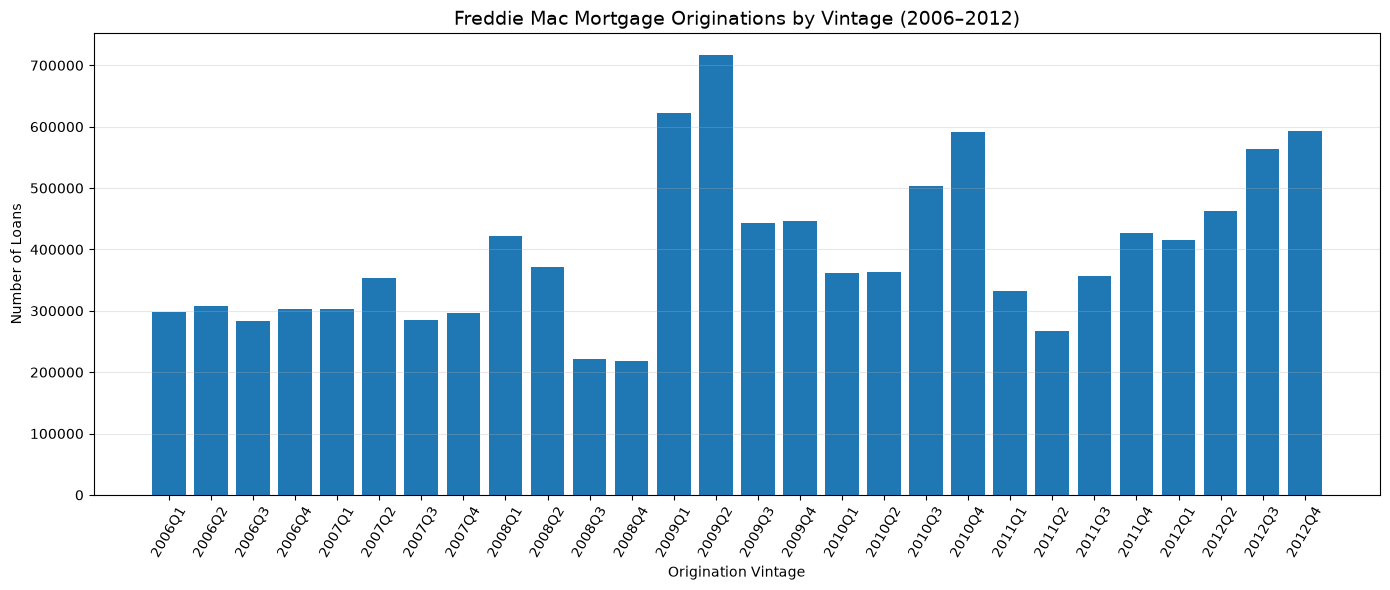

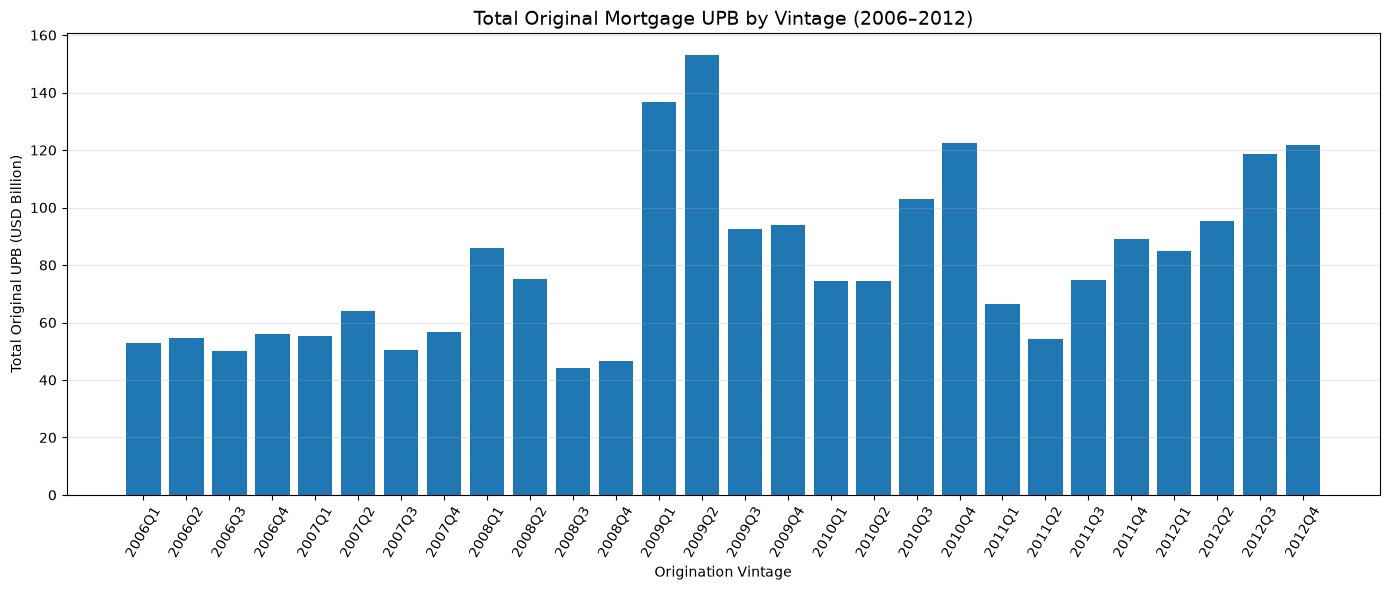

In [6]:

# ============================================================
# CELL 3C — PORTFOLIO SIZE AND EXPOSURE VISUALIZATION
# ============================================================

# Chart 1: Loan counts
fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    portfolio_by_vintage["vintage"],
    portfolio_by_vintage["total_loans"]
)

ax.set_title(
    "Freddie Mac Mortgage Originations by Vintage (2006–2012)",
    fontsize=14
)

ax.set_xlabel("Origination Vintage")
ax.set_ylabel("Number of Loans")

ax.tick_params(axis="x", rotation=60)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "loan_originations_by_vintage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Chart 2: Original UPB
fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    portfolio_by_vintage["vintage"],
    portfolio_by_vintage["total_original_upb"] / 1e9
)

ax.set_title(
    "Total Original Mortgage UPB by Vintage (2006–2012)",
    fontsize=14
)

ax.set_xlabel("Origination Vintage")
ax.set_ylabel("Total Original UPB (USD Billion)")

ax.tick_params(axis="x", rotation=60)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "original_upb_by_vintage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [7]:

# ============================================================
# CELL 3D — LTV / CLTV SENSITIVITY ANALYSIS
# ============================================================

ltv_sensitivity = con.execute("""
SELECT
    vintage,
    CASE
        WHEN TRIM(harp_indicator) = 'Y' THEN 'HARP'
        ELSE 'Non-HARP'
    END AS loan_group,

    COUNT(*) AS total_loans,

    -- Original LTV: all available observations
    AVG(original_ltv_num) AS avg_ltv_all,
    MEDIAN(original_ltv_num) AS median_ltv_all,

    -- Original LTV: within guide range
    AVG(original_ltv_num) FILTER (
        WHERE original_ltv_num BETWEEN 6 AND 105
    ) AS avg_ltv_in_range,

    COUNT(*) FILTER (
        WHERE original_ltv_num < 6
           OR original_ltv_num > 105
    ) AS ltv_outside_range,

    -- Original CLTV: all available observations
    AVG(original_cltv_num) AS avg_cltv_all,
    MEDIAN(original_cltv_num) AS median_cltv_all,

    -- Original CLTV: within guide range
    AVG(original_cltv_num) FILTER (
        WHERE original_cltv_num BETWEEN 6 AND 200
    ) AS avg_cltv_in_range,

    COUNT(*) FILTER (
        WHERE original_cltv_num < 6
           OR original_cltv_num > 200
    ) AS cltv_outside_range

FROM read_parquet(?)

GROUP BY
    vintage,
    CASE
        WHEN TRIM(harp_indicator) = 'Y' THEN 'HARP'
        ELSE 'Non-HARP'
    END

ORDER BY vintage, loan_group
""", [CLEAN_FILE_PATHS]).df()

# Calculate out-of-range percentages
ltv_sensitivity["ltv_outside_pct"] = (
    ltv_sensitivity["ltv_outside_range"]
    / ltv_sensitivity["total_loans"] * 100
)

ltv_sensitivity["cltv_outside_pct"] = (
    ltv_sensitivity["cltv_outside_range"]
    / ltv_sensitivity["total_loans"] * 100
)

# Save results
ltv_sensitivity.to_csv(
    TABLE_DIR / "ltv_cltv_sensitivity_by_vintage.csv",
    index=False
)

print("LTV / CLTV SENSITIVITY BY VINTAGE AND HARP STATUS")

print(
    ltv_sensitivity.round(2).to_string(index=False)
)

# Focus on 2012 vintages
print("\nFOCUS: 2012 VINTAGES")

print(
    ltv_sensitivity[
        ltv_sensitivity["vintage"].str.startswith("2012")
    ].round(2).to_string(index=False)
)

print("\nSaved:",
      TABLE_DIR / "ltv_cltv_sensitivity_by_vintage.csv")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

LTV / CLTV SENSITIVITY BY VINTAGE AND HARP STATUS
vintage loan_group  total_loans  avg_ltv_all  median_ltv_all  avg_ltv_in_range  ltv_outside_range  avg_cltv_all  median_cltv_all  avg_cltv_in_range  cltv_outside_range  ltv_outside_pct  cltv_outside_pct
 2006Q1   Non-HARP       298574        69.32            76.0             69.32                  0         71.34             77.0              71.34                   0             0.00              0.00
 2006Q2   Non-HARP       308208        70.28            78.0             70.28                  0         72.86             79.0              72.86                   0             0.00              0.00
 2006Q3   Non-HARP       283975        70.48            78.0             70.48                  0         73.31             80.0              73.31                   0             0.00              0.00
 2006Q4   Non-HARP       302787        69.90            75.0             69.90                  0         72.76             78.0          

In [8]:

# ============================================================
# CELL 4A — FICO SCORE SEGMENTATION
# ============================================================

fico_segmentation = con.execute("""
WITH classified AS (
    SELECT
        loan_identifier,
        original_upb_num,
        classic_fico_num,
        original_dti_num,
        original_ltv_num,
        harp_indicator,
        ever_90dpd,
        credit_related_termination,

        CASE
            WHEN classic_fico_num < 620
                THEN '01. Below 620'

            WHEN classic_fico_num < 680
                THEN '02. 620-679'

            WHEN classic_fico_num < 720
                THEN '03. 680-719'

            WHEN classic_fico_num < 760
                THEN '04. 720-759'

            WHEN classic_fico_num < 800
                THEN '05. 760-799'

            WHEN classic_fico_num >= 800
                THEN '06. 800+'

            ELSE 'Missing'
        END AS fico_segment

    FROM read_parquet(?)
)

SELECT
    fico_segment,

    COUNT(*) AS total_loans,

    100.0 * COUNT(*) /
        SUM(COUNT(*)) OVER () AS portfolio_share_pct,

    SUM(original_upb_num) AS total_original_upb,

    AVG(original_upb_num) AS avg_original_upb,

    AVG(classic_fico_num) AS avg_fico,

    AVG(original_dti_num) AS avg_dti,

    AVG(original_ltv_num) AS avg_ltv,

    COUNT(*) FILTER (
        WHERE TRIM(harp_indicator) = 'Y'
    ) AS harp_loans,

    100.0 * COUNT(*) FILTER (
        WHERE TRIM(harp_indicator) = 'Y'
    ) / COUNT(*) AS harp_share_pct,

    SUM(ever_90dpd) AS loans_ever_90dpd,

    100.0 * SUM(ever_90dpd) /
        COUNT(*) AS ever_90dpd_rate_pct,

    SUM(credit_related_termination)
        AS credit_related_terminations,

    100.0 * SUM(credit_related_termination) /
        COUNT(*) AS credit_termination_rate_pct

FROM classified

GROUP BY fico_segment

ORDER BY fico_segment
""", [CLEAN_FILE_PATHS]).df()

# Save results
fico_segmentation.to_csv(
    TABLE_DIR / "fico_segmentation.csv",
    index=False
)

print("=" * 75)
print("FICO SCORE SEGMENTATION")
print("=" * 75)

print(
    fico_segmentation.round(2).to_string(index=False)
)

print("\nSaved:",
      TABLE_DIR / "fico_segmentation.csv")


FICO SCORE SEGMENTATION
 fico_segment  total_loans  portfolio_share_pct  total_original_upb  avg_original_upb  avg_fico  avg_dti  avg_ltv  harp_loans  harp_share_pct  loans_ever_90dpd  ever_90dpd_rate_pct  credit_related_terminations  credit_termination_rate_pct
01. Below 620       181920                 1.63        3.001077e+10         164966.88    590.02    37.49    75.33       52491           28.85           59534.0                32.73                      21422.0                        11.78
  02. 620-679       978743                 8.79        1.742167e+11         178000.43    655.86    38.04    74.66      159311           16.28          215515.0                22.02                      89400.0                         9.13
  03. 680-719      1624560                14.60        3.189045e+11         196302.05    700.99    36.52    73.64      275995           16.99          183798.0                11.31                      80017.0                         4.93
  04. 720-759      2

In [9]:

# ============================================================
# CELL 4A.1 — MISSING FICO AUDIT
# ============================================================

fico_missing = con.execute("""
SELECT
    COUNT(*) AS total_loans,

    COUNT(*) FILTER (
        WHERE classic_fico_num IS NULL
    ) AS missing_fico,

    100.0 * COUNT(*) FILTER (
        WHERE classic_fico_num IS NULL
    ) / COUNT(*) AS missing_fico_pct,

    COUNT(*) FILTER (
        WHERE classic_fico_num IS NOT NULL
    ) AS valid_fico

FROM read_parquet(?)
""", [CLEAN_FILE_PATHS]).df()

print("FICO DATA AVAILABILITY")
print(fico_missing.round(4).to_string(index=False))


FICO DATA AVAILABILITY
 total_loans  missing_fico  missing_fico_pct  valid_fico
    11128442          3067            0.0276    11125375


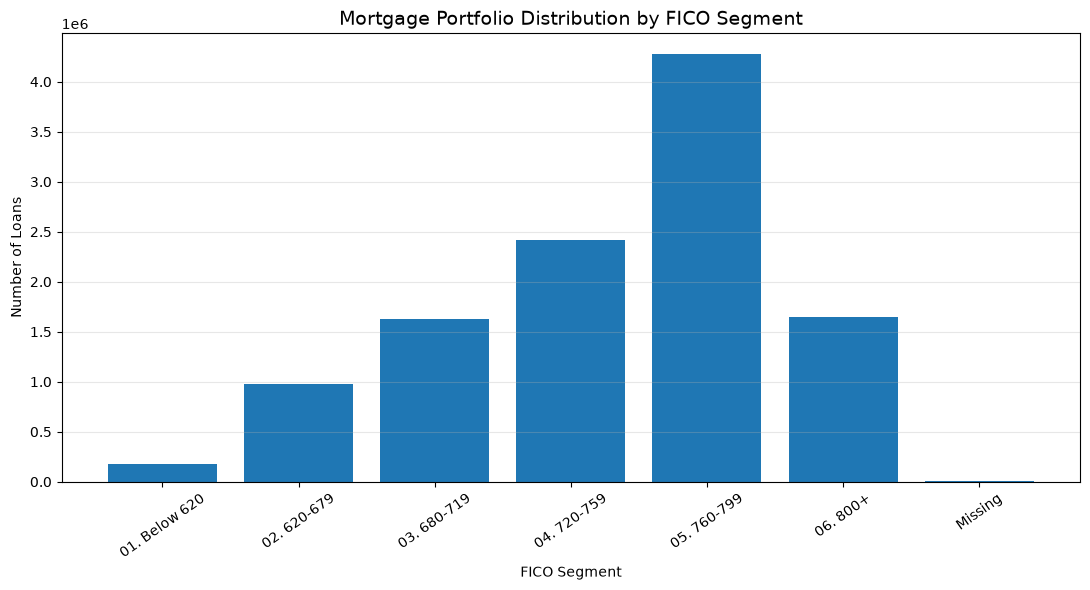

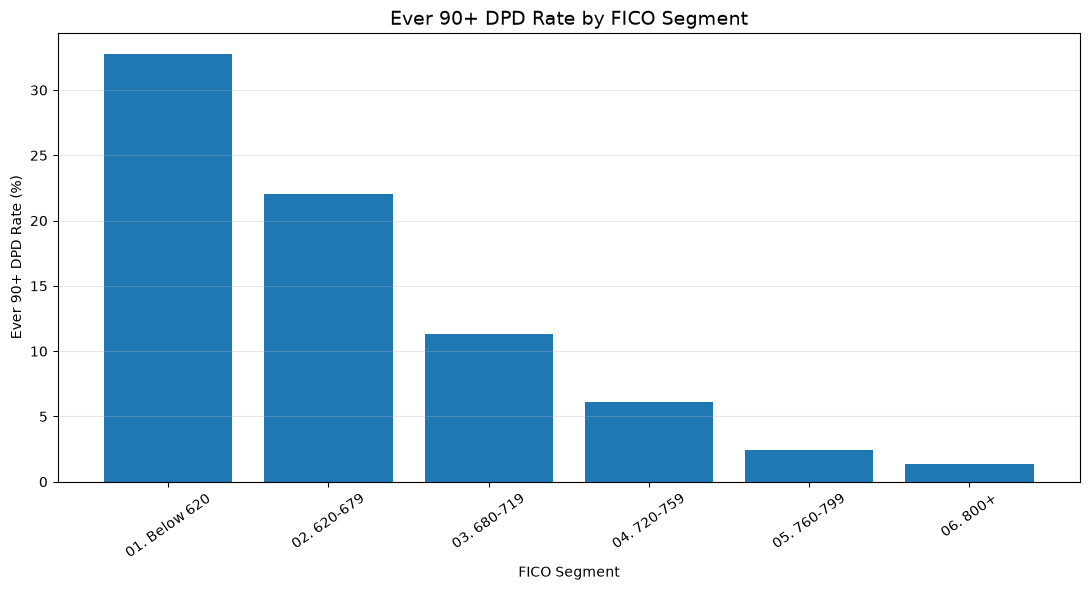

In [10]:

# ============================================================
# CELL 4A.2 — FICO SEGMENTATION VISUALIZATION
# ============================================================

# Chart 1: Loan distribution by FICO
fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    fico_segmentation["fico_segment"],
    fico_segmentation["total_loans"]
)

ax.set_title(
    "Mortgage Portfolio Distribution by FICO Segment",
    fontsize=14
)

ax.set_xlabel("FICO Segment")
ax.set_ylabel("Number of Loans")

ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "fico_portfolio_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Chart 2: Ever 90+ DPD rate by FICO
valid_fico_results = fico_segmentation[
    fico_segmentation["fico_segment"] != "Missing"
]

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    valid_fico_results["fico_segment"],
    valid_fico_results["ever_90dpd_rate_pct"]
)

ax.set_title(
    "Ever 90+ DPD Rate by FICO Segment",
    fontsize=14
)

ax.set_xlabel("FICO Segment")
ax.set_ylabel("Ever 90+ DPD Rate (%)")

ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "fico_90dpd_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [11]:

# ============================================================
# CELL 4B — DTI SEGMENTATION
# ============================================================

dti_segmentation = con.execute("""
WITH classified AS (
    SELECT
        loan_identifier,
        original_upb_num,
        original_dti_num,
        classic_fico_num,
        original_ltv_num,
        harp_indicator,
        ever_90dpd,
        credit_related_termination,

        CASE
            WHEN original_dti_num IS NULL
                THEN '07. Missing'

            WHEN original_dti_num < 0
                OR original_dti_num > 65
                THEN '06. Outside guide range'

            WHEN original_dti_num <= 20
                THEN '01. 0-20'

            WHEN original_dti_num <= 30
                THEN '02. 20-30'

            WHEN original_dti_num <= 40
                THEN '03. 30-40'

            WHEN original_dti_num <= 50
                THEN '04. 40-50'

            ELSE '05. 50-65'
        END AS dti_segment

    FROM read_parquet(?)
)

SELECT
    dti_segment,

    COUNT(*) AS total_loans,

    100.0 * COUNT(*) /
        SUM(COUNT(*)) OVER () AS portfolio_share_pct,

    SUM(original_upb_num) AS total_original_upb,

    AVG(original_upb_num) AS avg_original_upb,

    AVG(original_dti_num) AS avg_dti,

    AVG(classic_fico_num) AS avg_fico,

    AVG(original_ltv_num) AS avg_ltv,

    COUNT(*) FILTER (
        WHERE TRIM(harp_indicator) = 'Y'
    ) AS harp_loans,

    100.0 * COUNT(*) FILTER (
        WHERE TRIM(harp_indicator) = 'Y'
    ) / COUNT(*) AS harp_share_pct,

    SUM(ever_90dpd) AS loans_ever_90dpd,

    100.0 * SUM(ever_90dpd) /
        COUNT(*) AS ever_90dpd_rate_pct,

    SUM(credit_related_termination)
        AS credit_related_terminations,

    100.0 * SUM(credit_related_termination) /
        COUNT(*) AS credit_termination_rate_pct

FROM classified

GROUP BY dti_segment

ORDER BY dti_segment
""", [CLEAN_FILE_PATHS]).df()

# Save results
dti_segmentation.to_csv(
    TABLE_DIR / "dti_segmentation.csv",
    index=False
)

print("=" * 75)
print("DTI SEGMENTATION")
print("=" * 75)

print(
    dti_segmentation.round(2).to_string(index=False)
)

print("\nSaved:",
      TABLE_DIR / "dti_segmentation.csv")


DTI SEGMENTATION
dti_segment  total_loans  portfolio_share_pct  total_original_upb  avg_original_upb  avg_dti  avg_fico  avg_ltv  harp_loans  harp_share_pct  loans_ever_90dpd  ever_90dpd_rate_pct  credit_related_terminations  credit_termination_rate_pct
   01. 0-20      1358915                12.21        2.474303e+11         182079.34    15.69    768.61    61.40           0            0.00           31849.0                 2.34                      13570.0                         1.00
  02. 20-30      2473400                22.23        4.963388e+11         200670.67    25.72    758.71    67.38           0            0.00           93220.0                 3.77                      40067.0                         1.62
  03. 30-40      2683603                24.11        5.654191e+11         210694.02    35.46    747.54    70.11           0            0.00          179492.0                 6.69                      79517.0                         2.96
  04. 40-50      2008797           

In [12]:

# ============================================================
# CELL 4B.1 — DTI AVAILABILITY BY HARP STATUS
# ============================================================

dti_availability = con.execute("""
SELECT
    CASE
        WHEN TRIM(harp_indicator) = 'Y'
            THEN 'HARP'
        ELSE 'Non-HARP'
    END AS loan_group,

    COUNT(*) AS total_loans,

    COUNT(*) FILTER (
        WHERE original_dti_num IS NOT NULL
    ) AS valid_dti,

    COUNT(*) FILTER (
        WHERE original_dti_num IS NULL
    ) AS missing_dti,

    100.0 * COUNT(*) FILTER (
        WHERE original_dti_num IS NULL
    ) / COUNT(*) AS missing_dti_pct,

    COUNT(*) FILTER (
        WHERE original_dti_num < 0
           OR original_dti_num > 65
    ) AS outside_guide_range

FROM read_parquet(?)

GROUP BY 1
ORDER BY 1
""", [CLEAN_FILE_PATHS]).df()

print("DTI DATA AVAILABILITY BY HARP STATUS")

print(
    dti_availability.round(4).to_string(index=False)
)

dti_availability.to_csv(
    TABLE_DIR / "dti_availability_by_harp.csv",
    index=False
)


DTI DATA AVAILABILITY BY HARP STATUS
loan_group  total_loans  valid_dti  missing_dti  missing_dti_pct  outside_guide_range
      HARP      1887432          0      1887432          100.000                    0
  Non-HARP      9241010    9153685        87325            0.945                    0


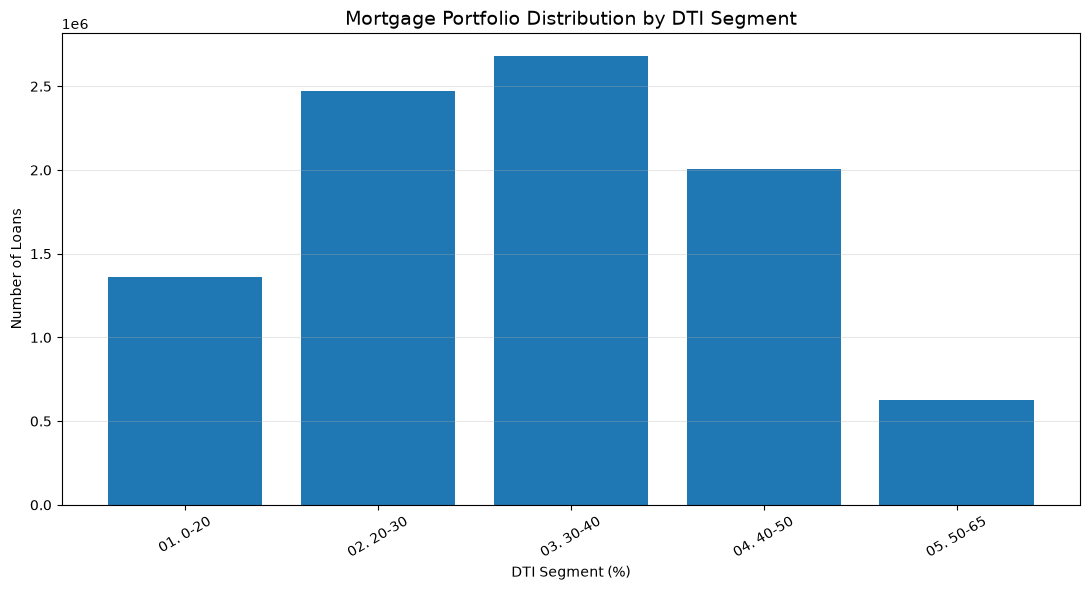

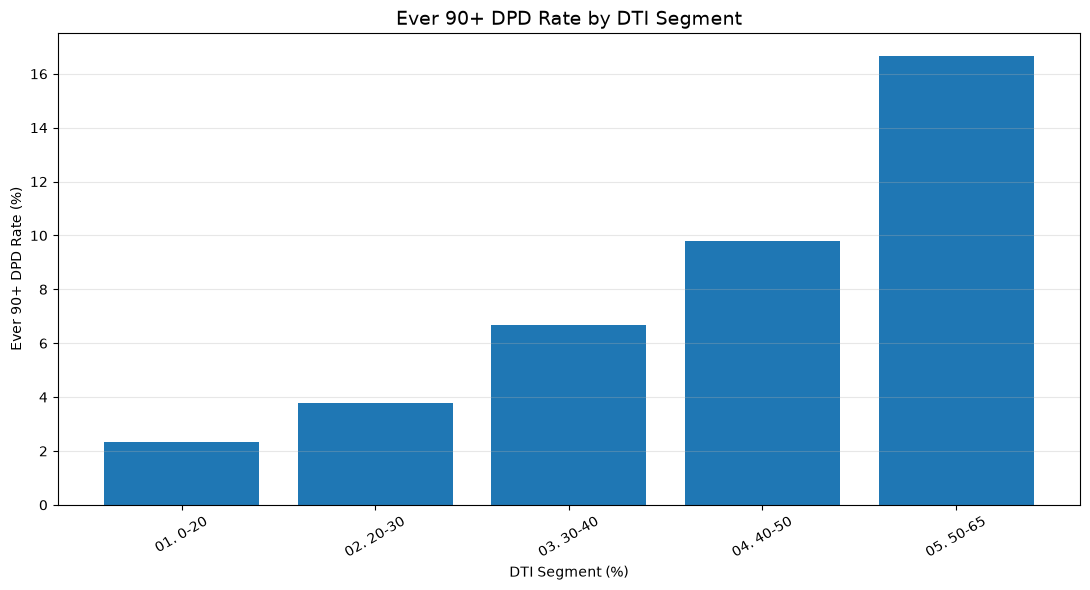

In [13]:

# ============================================================
# CELL 4B.2 — DTI SEGMENTATION VISUALIZATION
# ============================================================

# Exclude missing and outside-range groups from ordered DTI chart
valid_dti_results = dti_segmentation[
    dti_segmentation["dti_segment"].isin([
        "01. 0-20",
        "02. 20-30",
        "03. 30-40",
        "04. 40-50",
        "05. 50-65"
    ])
].copy()

# Chart 1: Portfolio distribution
fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    valid_dti_results["dti_segment"],
    valid_dti_results["total_loans"]
)

ax.set_title(
    "Mortgage Portfolio Distribution by DTI Segment",
    fontsize=14
)

ax.set_xlabel("DTI Segment (%)")
ax.set_ylabel("Number of Loans")

ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "dti_portfolio_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Chart 2: Ever 90+ DPD rate
fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    valid_dti_results["dti_segment"],
    valid_dti_results["ever_90dpd_rate_pct"]
)

ax.set_title(
    "Ever 90+ DPD Rate by DTI Segment",
    fontsize=14
)

ax.set_xlabel("DTI Segment (%)")
ax.set_ylabel("Ever 90+ DPD Rate (%)")

ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "dti_90dpd_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [14]:

# ============================================================
# CELL 4C.1 — ORIGINAL LTV SEGMENTATION
# ============================================================

ltv_segmentation = con.execute("""
WITH classified AS (
    SELECT
        loan_identifier,
        original_upb_num,
        original_ltv_num,
        original_cltv_num,
        classic_fico_num,
        original_dti_num,
        harp_indicator,
        ever_90dpd,
        credit_related_termination,

        CASE
            WHEN original_ltv_num IS NULL
                THEN '09. Missing'
            WHEN original_ltv_num < 6
                THEN '01. Below 6'
            WHEN original_ltv_num <= 60
                THEN '02. 6-60'
            WHEN original_ltv_num <= 80
                THEN '03. 60-80'
            WHEN original_ltv_num <= 90
                THEN '04. 80-90'
            WHEN original_ltv_num <= 100
                THEN '05. 90-100'
            WHEN original_ltv_num <= 105
                THEN '06. 100-105'
            ELSE '07. Above 105'
        END AS ltv_segment

    FROM read_parquet(?)
)

SELECT
    ltv_segment,
    COUNT(*) AS total_loans,

    100.0 * COUNT(*) /
        SUM(COUNT(*)) OVER () AS portfolio_share_pct,

    SUM(original_upb_num) AS total_original_upb,
    AVG(original_upb_num) AS avg_original_upb,
    AVG(original_ltv_num) AS avg_ltv,

    AVG(classic_fico_num) AS avg_fico,
    AVG(original_dti_num) AS avg_dti,

    COUNT(*) FILTER (
        WHERE TRIM(harp_indicator) = 'Y'
    ) AS harp_loans,

    100.0 * COUNT(*) FILTER (
        WHERE TRIM(harp_indicator) = 'Y'
    ) / COUNT(*) AS harp_share_pct,

    SUM(ever_90dpd) AS loans_ever_90dpd,

    100.0 * SUM(ever_90dpd) /
        COUNT(*) AS ever_90dpd_rate_pct,

    SUM(credit_related_termination)
        AS credit_related_terminations,

    100.0 * SUM(credit_related_termination) /
        COUNT(*) AS credit_termination_rate_pct

FROM classified
GROUP BY ltv_segment
ORDER BY ltv_segment
""", [CLEAN_FILE_PATHS]).df()

ltv_segmentation.to_csv(
    TABLE_DIR / "ltv_segmentation.csv",
    index=False
)

print("=" * 75)
print("ORIGINAL LTV SEGMENTATION")
print("=" * 75)

print(ltv_segmentation.round(2).to_string(index=False))

print("\nSaved:", TABLE_DIR / "ltv_segmentation.csv")


ORIGINAL LTV SEGMENTATION
  ltv_segment  total_loans  portfolio_share_pct  total_original_upb  avg_original_upb  avg_ltv  avg_fico  avg_dti  harp_loans  harp_share_pct  loans_ever_90dpd  ever_90dpd_rate_pct  credit_related_terminations  credit_termination_rate_pct
  01. Below 6          141                 0.00        6.279000e+06          44531.91     4.40    776.68      NaN         141          100.00               1.0                 0.71                          0.0                         0.00
     02. 6-60      3197187                28.73        5.959895e+11         186410.57    45.07    761.23    31.18      465793           14.57           91732.0                 2.87                      18816.0                         0.59
    03. 60-80      5854436                52.61        1.232814e+12         210577.71    74.39    749.37    33.93      474799            8.11          398611.0                 6.81                     172113.0                         2.94
    04. 80-90     

In [15]:

# ============================================================
# CELL 4C.2 — ORIGINAL CLTV SEGMENTATION
# ============================================================

cltv_segmentation = con.execute("""
WITH classified AS (
    SELECT
        loan_identifier,
        original_upb_num,
        original_cltv_num,
        original_ltv_num,
        classic_fico_num,
        original_dti_num,
        harp_indicator,
        ever_90dpd,
        credit_related_termination,

        CASE
            WHEN original_cltv_num IS NULL
                THEN '09. Missing'
            WHEN original_cltv_num < 6
                THEN '01. Below 6'
            WHEN original_cltv_num <= 60
                THEN '02. 6-60'
            WHEN original_cltv_num <= 80
                THEN '03. 60-80'
            WHEN original_cltv_num <= 90
                THEN '04. 80-90'
            WHEN original_cltv_num <= 100
                THEN '05. 90-100'
            WHEN original_cltv_num <= 125
                THEN '06. 100-125'
            WHEN original_cltv_num <= 150
                THEN '07. 125-150'
            WHEN original_cltv_num <= 200
                THEN '08. 150-200'
            ELSE '10. Above 200'
        END AS cltv_segment

    FROM read_parquet(?)
)

SELECT
    cltv_segment,
    COUNT(*) AS total_loans,

    100.0 * COUNT(*) /
        SUM(COUNT(*)) OVER () AS portfolio_share_pct,

    SUM(original_upb_num) AS total_original_upb,
    AVG(original_upb_num) AS avg_original_upb,
    AVG(original_cltv_num) AS avg_cltv,

    AVG(classic_fico_num) AS avg_fico,
    AVG(original_dti_num) AS avg_dti,

    COUNT(*) FILTER (
        WHERE TRIM(harp_indicator) = 'Y'
    ) AS harp_loans,

    100.0 * COUNT(*) FILTER (
        WHERE TRIM(harp_indicator) = 'Y'
    ) / COUNT(*) AS harp_share_pct,

    SUM(ever_90dpd) AS loans_ever_90dpd,

    100.0 * SUM(ever_90dpd) /
        COUNT(*) AS ever_90dpd_rate_pct,

    SUM(credit_related_termination)
        AS credit_related_terminations,

    100.0 * SUM(credit_related_termination) /
        COUNT(*) AS credit_termination_rate_pct

FROM classified
GROUP BY cltv_segment
ORDER BY cltv_segment
""", [CLEAN_FILE_PATHS]).df()

cltv_segmentation.to_csv(
    TABLE_DIR / "cltv_segmentation.csv",
    index=False
)

print("=" * 75)
print("ORIGINAL CLTV SEGMENTATION")
print("=" * 75)

print(cltv_segmentation.round(2).to_string(index=False))

print("\nSaved:", TABLE_DIR / "cltv_segmentation.csv")


ORIGINAL CLTV SEGMENTATION
 cltv_segment  total_loans  portfolio_share_pct  total_original_upb  avg_original_upb  avg_cltv  avg_fico  avg_dti  harp_loans  harp_share_pct  loans_ever_90dpd  ever_90dpd_rate_pct  credit_related_terminations  credit_termination_rate_pct
  01. Below 6           99                 0.00        4.952000e+06          50020.20      4.33    777.17      NaN          99          100.00               1.0                 1.01                          0.0                         0.00
     02. 6-60      2937478                26.40        5.311168e+11         180807.06     45.27    761.86    31.05      394705           13.44           82966.0                 2.82                      17071.0                         0.58
    03. 60-80      5381803                48.36        1.135612e+12         211009.57     74.17    750.98    33.64      411273            7.64          334805.0                 6.22                     134409.0                         2.50
    04. 80-90

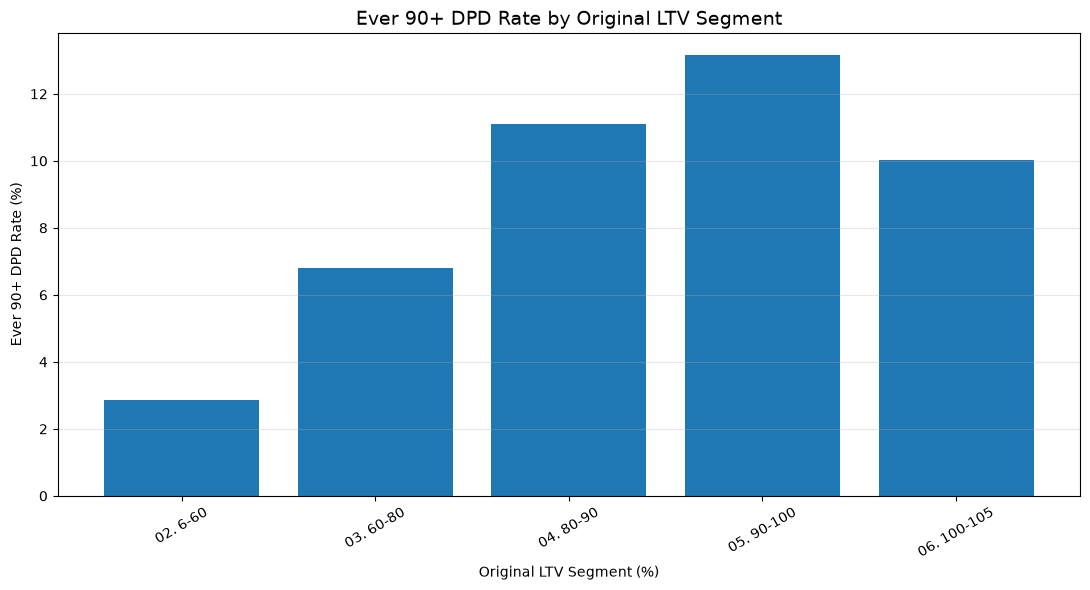

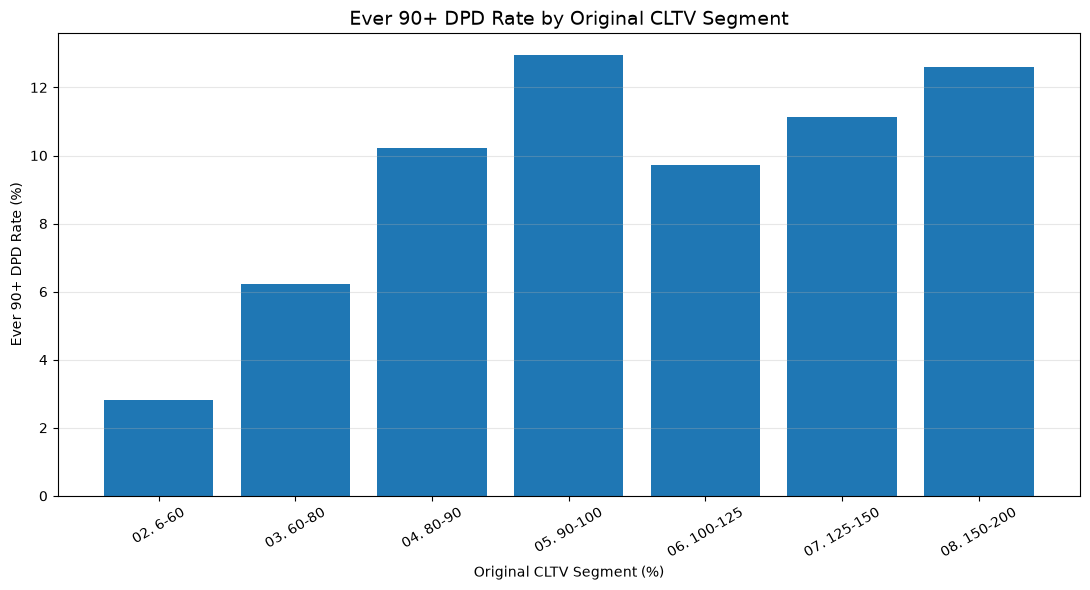

In [16]:

# ============================================================
# CELL 4C.3 — LTV / CLTV RISK VISUALIZATION
# ============================================================

ltv_valid = ltv_segmentation[
    ltv_segmentation["ltv_segment"].isin([
        "02. 6-60",
        "03. 60-80",
        "04. 80-90",
        "05. 90-100",
        "06. 100-105"
    ])
].copy()

cltv_valid = cltv_segmentation[
    cltv_segmentation["cltv_segment"].isin([
        "02. 6-60",
        "03. 60-80",
        "04. 80-90",
        "05. 90-100",
        "06. 100-125",
        "07. 125-150",
        "08. 150-200"
    ])
].copy()

# Chart 1: Ever 90+ DPD by OLTV
fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    ltv_valid["ltv_segment"],
    ltv_valid["ever_90dpd_rate_pct"]
)

ax.set_title(
    "Ever 90+ DPD Rate by Original LTV Segment",
    fontsize=14
)

ax.set_xlabel("Original LTV Segment (%)")
ax.set_ylabel("Ever 90+ DPD Rate (%)")

ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "ltv_90dpd_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Chart 2: Ever 90+ DPD by CLTV
fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    cltv_valid["cltv_segment"],
    cltv_valid["ever_90dpd_rate_pct"]
)

ax.set_title(
    "Ever 90+ DPD Rate by Original CLTV Segment",
    fontsize=14
)

ax.set_xlabel("Original CLTV Segment (%)")
ax.set_ylabel("Ever 90+ DPD Rate (%)")

ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "cltv_90dpd_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [17]:

# ============================================================
# CELL 4C.4 — LTV / CLTV RISK BY HARP STATUS
# ============================================================

# ------------------------------------------------------------
# A. LTV segmentation by HARP status
# ------------------------------------------------------------

ltv_by_harp = con.execute("""
WITH classified AS (
    SELECT
        CASE
            WHEN TRIM(harp_indicator) = 'Y' THEN 'HARP'
            ELSE 'Non-HARP'
        END AS loan_group,

        CASE
            WHEN original_ltv_num IS NULL
                THEN '09. Missing'
            WHEN original_ltv_num < 6
                THEN '01. Below 6'
            WHEN original_ltv_num <= 60
                THEN '02. 6-60'
            WHEN original_ltv_num <= 80
                THEN '03. 60-80'
            WHEN original_ltv_num <= 90
                THEN '04. 80-90'
            WHEN original_ltv_num <= 100
                THEN '05. 90-100'
            WHEN original_ltv_num <= 105
                THEN '06. 100-105'
            ELSE '07. Above 105'
        END AS ltv_segment,

        ever_90dpd,
        credit_related_termination

    FROM read_parquet(?)
)

SELECT
    loan_group,
    ltv_segment,
    COUNT(*) AS total_loans,

    SUM(ever_90dpd) AS loans_ever_90dpd,

    100.0 * SUM(ever_90dpd) /
        COUNT(*) AS ever_90dpd_rate_pct,

    SUM(credit_related_termination)
        AS credit_related_terminations,

    100.0 * SUM(credit_related_termination) /
        COUNT(*) AS credit_termination_rate_pct

FROM classified
GROUP BY loan_group, ltv_segment
ORDER BY loan_group, ltv_segment
""", [CLEAN_FILE_PATHS]).df()


# ------------------------------------------------------------
# B. CLTV segmentation by HARP status
# ------------------------------------------------------------

cltv_by_harp = con.execute("""
WITH classified AS (
    SELECT
        CASE
            WHEN TRIM(harp_indicator) = 'Y' THEN 'HARP'
            ELSE 'Non-HARP'
        END AS loan_group,

        CASE
            WHEN original_cltv_num IS NULL
                THEN '09. Missing'
            WHEN original_cltv_num < 6
                THEN '01. Below 6'
            WHEN original_cltv_num <= 60
                THEN '02. 6-60'
            WHEN original_cltv_num <= 80
                THEN '03. 60-80'
            WHEN original_cltv_num <= 90
                THEN '04. 80-90'
            WHEN original_cltv_num <= 100
                THEN '05. 90-100'
            WHEN original_cltv_num <= 125
                THEN '06. 100-125'
            WHEN original_cltv_num <= 150
                THEN '07. 125-150'
            WHEN original_cltv_num <= 200
                THEN '08. 150-200'
            ELSE '10. Above 200'
        END AS cltv_segment,

        ever_90dpd,
        credit_related_termination

    FROM read_parquet(?)
)

SELECT
    loan_group,
    cltv_segment,
    COUNT(*) AS total_loans,

    SUM(ever_90dpd) AS loans_ever_90dpd,

    100.0 * SUM(ever_90dpd) /
        COUNT(*) AS ever_90dpd_rate_pct,

    SUM(credit_related_termination)
        AS credit_related_terminations,

    100.0 * SUM(credit_related_termination) /
        COUNT(*) AS credit_termination_rate_pct

FROM classified
GROUP BY loan_group, cltv_segment
ORDER BY loan_group, cltv_segment
""", [CLEAN_FILE_PATHS]).df()


# ------------------------------------------------------------
# C. Save results
# ------------------------------------------------------------

ltv_by_harp.to_csv(
    TABLE_DIR / "ltv_risk_by_harp.csv",
    index=False
)

cltv_by_harp.to_csv(
    TABLE_DIR / "cltv_risk_by_harp.csv",
    index=False
)


# ------------------------------------------------------------
# D. Display results
# ------------------------------------------------------------

print("=" * 85)
print("LTV RISK BY HARP STATUS")
print("=" * 85)

print(ltv_by_harp.round(2).to_string(index=False))

print("\n" + "=" * 85)
print("CLTV RISK BY HARP STATUS")
print("=" * 85)

print(cltv_by_harp.round(2).to_string(index=False))

print("\nSaved:")
print(TABLE_DIR / "ltv_risk_by_harp.csv")
print(TABLE_DIR / "cltv_risk_by_harp.csv")


LTV RISK BY HARP STATUS
loan_group   ltv_segment  total_loans  loans_ever_90dpd  ever_90dpd_rate_pct  credit_related_terminations  credit_termination_rate_pct
      HARP   01. Below 6          141               1.0                 0.71                          0.0                         0.00
      HARP      02. 6-60       465793           11260.0                 2.42                        962.0                         0.21
      HARP     03. 60-80       474799           21717.0                 4.57                       4420.0                         0.93
      HARP     04. 80-90       309847           20396.0                 6.58                       6045.0                         1.95
      HARP    05. 90-100       257004           21650.0                 8.42                       7774.0                         3.02
      HARP   06. 100-105       105922           10613.0                10.02                       4356.0                         4.11
      HARP 07. Above 105       

In [18]:

# ============================================================
# CELL 4D.1 — CATEGORICAL DATA AUDIT
# ============================================================

categorical_variables = [
    "occupancy_status",
    "loan_purpose",
    "channel",
    "property_type",
    "first_time_homebuyer_indicator",
    "number_of_borrowers_num",
    "interest_only_i_o_indicator",
    "special_eligibility_program",
    "property_valuation_method"
]

categorical_audit = []

for variable in categorical_variables:

    query = f"""
        SELECT
            '{variable}' AS variable_name,

            COALESCE(
                NULLIF(TRIM(CAST({variable} AS VARCHAR)), ''),
                'MISSING'
            ) AS category,

            COUNT(*) AS loan_count,

            100.0 * COUNT(*) /
                SUM(COUNT(*)) OVER () AS share_pct

        FROM read_parquet(?)

        GROUP BY 1, 2
        ORDER BY loan_count DESC
    """

    result = con.execute(
        query,
        [CLEAN_FILE_PATHS]
    ).df()

    categorical_audit.append(result)

categorical_audit_df = pd.concat(
    categorical_audit,
    ignore_index=True
)

categorical_audit_df.to_csv(
    TABLE_DIR / "categorical_data_audit.csv",
    index=False
)

print("=" * 85)
print("CATEGORICAL DATA AUDIT")
print("=" * 85)

for variable in categorical_variables:

    print("\n" + "-" * 85)
    print(f"VARIABLE: {variable}")
    print("-" * 85)

    display(
        categorical_audit_df[
            categorical_audit_df["variable_name"] == variable
        ].to_string(index=False)
    )

print("\nSaved:",
      TABLE_DIR / "categorical_data_audit.csv")


CATEGORICAL DATA AUDIT

-------------------------------------------------------------------------------------
VARIABLE: occupancy_status
-------------------------------------------------------------------------------------


'   variable_name category  loan_count  share_pct\noccupancy_status        P    10035668  90.180350\noccupancy_status        I      596834   5.363141\noccupancy_status        S      495939   4.456500\noccupancy_status        9           1   0.000009'


-------------------------------------------------------------------------------------
VARIABLE: loan_purpose
-------------------------------------------------------------------------------------


'variable_name category  loan_count  share_pct\n loan_purpose        N     5203142  46.755350\n loan_purpose        P     3031624  27.242124\n loan_purpose        C     2893676  26.002526'


-------------------------------------------------------------------------------------
VARIABLE: channel
-------------------------------------------------------------------------------------


'variable_name category  loan_count  share_pct\n      channel        R     6387723  57.399976\n      channel        C     2165003  19.454682\n      channel        T     1668726  14.995145\n      channel        B      906969   8.150009\n      channel        9          21   0.000189'

... (9 outputs left out)

'              variable_name category  loan_count  share_pct\nspecial_eligibility_program  MISSING    11128442      100.0'


-------------------------------------------------------------------------------------
VARIABLE: property_valuation_method
-------------------------------------------------------------------------------------


'            variable_name category  loan_count  share_pct\nproperty_valuation_method        7    11128442      100.0'


Saved: E:\DS_project_backup\credit-risk-portfolio\processed\eda\notebook_06\tables\categorical_data_audit.csv


In [19]:

# ============================================================
# CELL 4D.2 — CATEGORICAL DISTRIBUTION BY HARP STATUS
# ============================================================

categorical_variables_by_harp = [
    "occupancy_status",
    "loan_purpose",
    "channel",
    "property_type",
    "first_time_homebuyer_indicator",
    "interest_only_i_o_indicator"
]

harp_categorical_results = []

for variable in categorical_variables_by_harp:

    query = f"""
        SELECT
            CASE
                WHEN TRIM(harp_indicator) = 'Y'
                    THEN 'HARP'
                ELSE 'Non-HARP'
            END AS loan_group,

            COALESCE(
                NULLIF(TRIM(CAST({variable} AS VARCHAR)), ''),
                'MISSING'
            ) AS category,

            COUNT(*) AS loan_count,

            100.0 * COUNT(*) /
                SUM(COUNT(*)) OVER (
                    PARTITION BY
                        CASE
                            WHEN TRIM(harp_indicator) = 'Y'
                                THEN 'HARP'
                            ELSE 'Non-HARP'
                        END
                ) AS share_within_group_pct

        FROM read_parquet(?)

        GROUP BY 1, 2
        ORDER BY 1, loan_count DESC
    """

    result = con.execute(
        query,
        [CLEAN_FILE_PATHS]
    ).df()

    result.insert(1, "variable_name", variable)

    harp_categorical_results.append(result)

harp_categorical_df = pd.concat(
    harp_categorical_results,
    ignore_index=True
)

harp_categorical_df.to_csv(
    TABLE_DIR / "categorical_distribution_by_harp.csv",
    index=False
)

print("=" * 85)
print("CATEGORICAL DISTRIBUTION BY HARP STATUS")
print("=" * 85)

for variable in categorical_variables_by_harp:

    print("\n" + "-" * 85)
    print(f"VARIABLE: {variable}")
    print("-" * 85)

    display(
        harp_categorical_df[
            harp_categorical_df["variable_name"] == variable
        ].to_string(index=False)
    )

print("\nSaved:",
      TABLE_DIR / "categorical_distribution_by_harp.csv")


CATEGORICAL DISTRIBUTION BY HARP STATUS

-------------------------------------------------------------------------------------
VARIABLE: occupancy_status
-------------------------------------------------------------------------------------


'loan_group    variable_name category  loan_count  share_within_group_pct\n      HARP occupancy_status        P     1722112               91.241009\n      HARP occupancy_status        I      107293                5.684602\n      HARP occupancy_status        S       58027                3.074389\n  Non-HARP occupancy_status        P     8313556               89.963716\n  Non-HARP occupancy_status        I      489541                5.297484\n  Non-HARP occupancy_status        S      437912                4.738789\n  Non-HARP occupancy_status        9           1                0.000011'


-------------------------------------------------------------------------------------
VARIABLE: loan_purpose
-------------------------------------------------------------------------------------


'loan_group variable_name category  loan_count  share_within_group_pct\n      HARP  loan_purpose        N     1887169               99.986066\n      HARP  loan_purpose        C         261                0.013828\n      HARP  loan_purpose        P           2                0.000106\n  Non-HARP  loan_purpose        N     3315973               35.883231\n  Non-HARP  loan_purpose        P     3031622               32.806176\n  Non-HARP  loan_purpose        C     2893415               31.310593'


-------------------------------------------------------------------------------------
VARIABLE: channel
-------------------------------------------------------------------------------------


'loan_group variable_name category  loan_count  share_within_group_pct\n      HARP       channel        R     1799696               95.351568\n      HARP       channel        B       50319                2.666003\n      HARP       channel        C       37416                1.982376\n      HARP       channel        9           1                0.000053\n  Non-HARP       channel        R     4588027               49.648545\n  Non-HARP       channel        C     2127587               23.023317\n  Non-HARP       channel        T     1668726               18.057831\n  Non-HARP       channel        B      856650                9.270091\n  Non-HARP       channel        9          20                0.000216'

... (3 outputs left out)

'loan_group                  variable_name category  loan_count  share_within_group_pct\n      HARP first_time_homebuyer_indicator        N     1887432              100.000000\n  Non-HARP first_time_homebuyer_indicator        N     8390305               90.794242\n  Non-HARP first_time_homebuyer_indicator        Y      847127                9.167039\n  Non-HARP first_time_homebuyer_indicator        9        3578                0.038719'


-------------------------------------------------------------------------------------
VARIABLE: interest_only_i_o_indicator
-------------------------------------------------------------------------------------


'loan_group               variable_name category  loan_count  share_within_group_pct\n      HARP interest_only_i_o_indicator        N     1887432                   100.0\n  Non-HARP interest_only_i_o_indicator        N     9241010                   100.0'


Saved: E:\DS_project_backup\credit-risk-portfolio\processed\eda\notebook_06\tables\categorical_distribution_by_harp.csv


In [20]:

# ============================================================
# CELL 4D.3 — CATEGORICAL RISK SEGMENTATION
# ============================================================

categorical_risk_variables = {
    "occupancy_status": """
        CASE
            WHEN TRIM(occupancy_status) IN ('P', 'I', 'S')
                THEN TRIM(occupancy_status)
            ELSE 'MISSING/UNKNOWN'
        END
    """,

    "loan_purpose": """
        CASE
            WHEN TRIM(loan_purpose) IN ('N', 'P', 'C')
                THEN TRIM(loan_purpose)
            ELSE 'MISSING/UNKNOWN'
        END
    """,

    "channel": """
        CASE
            WHEN TRIM(channel) IN ('R', 'C', 'T', 'B')
                THEN TRIM(channel)
            ELSE 'MISSING/UNKNOWN'
        END
    """,

    "property_type": """
        CASE
            WHEN TRIM(property_type) IN ('SF', 'PU', 'CO', 'MH', 'CP')
                THEN TRIM(property_type)
            ELSE 'MISSING/UNKNOWN'
        END
    """,

    "first_time_homebuyer_indicator": """
        CASE
            WHEN TRIM(first_time_homebuyer_indicator) IN ('Y', 'N')
                THEN TRIM(first_time_homebuyer_indicator)
            ELSE 'MISSING/UNKNOWN'
        END
    """,

    "number_of_borrowers": """
        CASE
            WHEN number_of_borrowers_num IN (1, 2)
                THEN CAST(number_of_borrowers_num AS VARCHAR)
            ELSE 'MISSING/UNKNOWN'
        END
    """
}

categorical_risk_results = []

for variable, category_expression in categorical_risk_variables.items():

    query = f"""
        WITH classified AS (
            SELECT
                CASE
                    WHEN TRIM(harp_indicator) = 'Y'
                        THEN 'HARP'
                    ELSE 'Non-HARP'
                END AS loan_group,

                {category_expression} AS category,

                original_upb_num,
                ever_90dpd,
                credit_related_termination

            FROM read_parquet(?)
        )

        SELECT
            '{variable}' AS variable_name,
            loan_group,
            category,

            COUNT(*) AS total_loans,

            100.0 * COUNT(*) /
                SUM(COUNT(*)) OVER (
                    PARTITION BY variable_name, loan_group
                ) AS share_within_group_pct,

            SUM(original_upb_num) AS total_original_upb,

            AVG(original_upb_num) AS avg_original_upb,

            SUM(ever_90dpd) AS loans_ever_90dpd,

            100.0 * SUM(ever_90dpd) /
                COUNT(*) AS ever_90dpd_rate_pct,

            SUM(credit_related_termination)
                AS credit_related_terminations,

            100.0 * SUM(credit_related_termination) /
                COUNT(*) AS credit_termination_rate_pct

        FROM classified

        GROUP BY loan_group, category
        ORDER BY loan_group, category
    """

    result = con.execute(
        query,
        [CLEAN_FILE_PATHS]
    ).df()

    categorical_risk_results.append(result)

categorical_risk_df = pd.concat(
    categorical_risk_results,
    ignore_index=True
)

categorical_risk_df.to_csv(
    TABLE_DIR / "categorical_risk_segmentation.csv",
    index=False
)

print("=" * 90)
print("CATEGORICAL RISK SEGMENTATION BY HARP STATUS")
print("=" * 90)

for variable in categorical_risk_variables:

    print("\n" + "-" * 90)
    print(f"VARIABLE: {variable}")
    print("-" * 90)

    print(
        categorical_risk_df[
            categorical_risk_df["variable_name"] == variable
        ].round(2).to_string(index=False)
    )

print("\nSaved:",
      TABLE_DIR / "categorical_risk_segmentation.csv")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CATEGORICAL RISK SEGMENTATION BY HARP STATUS

------------------------------------------------------------------------------------------
VARIABLE: occupancy_status
------------------------------------------------------------------------------------------
   variable_name loan_group        category  total_loans  share_within_group_pct  total_original_upb  avg_original_upb  loans_ever_90dpd  ever_90dpd_rate_pct  credit_related_terminations  credit_termination_rate_pct
occupancy_status       HARP               I       107293                    5.68        1.854032e+10         172800.79            7247.0                 6.75                       2625.0                         2.45
occupancy_status       HARP               P      1722112                   91.24        3.226816e+11         187375.47          105061.0                 6.10                      32374.0                         1.88
occupancy_status       HARP               S        58027                    3.07        1.148281e

In [21]:

# ============================================================
# CELL 4D.4 — OVERALL CATEGORICAL RISK SEGMENTATION
# ============================================================

overall_categorical_results = []

for variable, category_expression in categorical_risk_variables.items():

    query = f"""
        WITH classified AS (
            SELECT
                {category_expression} AS category,
                original_upb_num,
                ever_90dpd,
                credit_related_termination

            FROM read_parquet(?)
        )

        SELECT
            '{variable}' AS variable_name,
            category,

            COUNT(*) AS total_loans,

            100.0 * COUNT(*) /
                SUM(COUNT(*)) OVER () AS portfolio_share_pct,

            SUM(original_upb_num) AS total_original_upb,

            SUM(ever_90dpd) AS loans_ever_90dpd,

            100.0 * SUM(ever_90dpd) /
                COUNT(*) AS ever_90dpd_rate_pct,

            SUM(credit_related_termination)
                AS credit_related_terminations,

            100.0 * SUM(credit_related_termination) /
                COUNT(*) AS credit_termination_rate_pct

        FROM classified
        GROUP BY category
        ORDER BY category
    """

    result = con.execute(
        query,
        [CLEAN_FILE_PATHS]
    ).df()

    overall_categorical_results.append(result)

overall_categorical_df = pd.concat(
    overall_categorical_results,
    ignore_index=True
)

overall_categorical_df.to_csv(
    TABLE_DIR / "overall_categorical_risk.csv",
    index=False
)

print("=" * 90)
print("OVERALL CATEGORICAL RISK SEGMENTATION")
print("=" * 90)

for variable in categorical_risk_variables:

    print("\n" + "-" * 90)
    print(f"VARIABLE: {variable}")
    print("-" * 90)

    print(
        overall_categorical_df[
            overall_categorical_df["variable_name"] == variable
        ].round(2).to_string(index=False)
    )

print("\nSaved:",
      TABLE_DIR / "overall_categorical_risk.csv")


OVERALL CATEGORICAL RISK SEGMENTATION

------------------------------------------------------------------------------------------
VARIABLE: occupancy_status
------------------------------------------------------------------------------------------
   variable_name        category  total_loans  portfolio_share_pct  total_original_upb  loans_ever_90dpd  ever_90dpd_rate_pct  credit_related_terminations  credit_termination_rate_pct
occupancy_status               I       596834                 5.36        9.264336e+10           51829.0                 8.68                      28716.0                         4.81
occupancy_status MISSING/UNKNOWN            1                 0.00        4.200000e+04               0.0                 0.00                          0.0                         0.00
occupancy_status               P     10035668                90.18        2.053440e+12          655164.0                 6.53                     267614.0                         2.67
occupancy_status

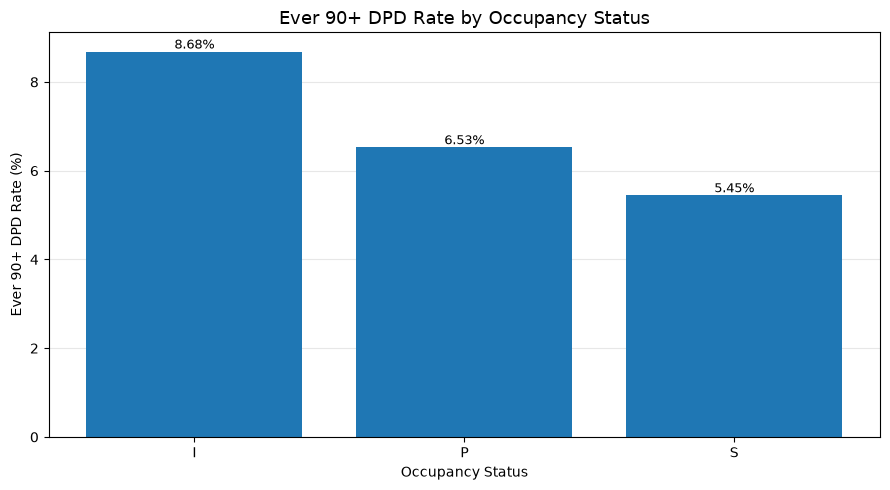

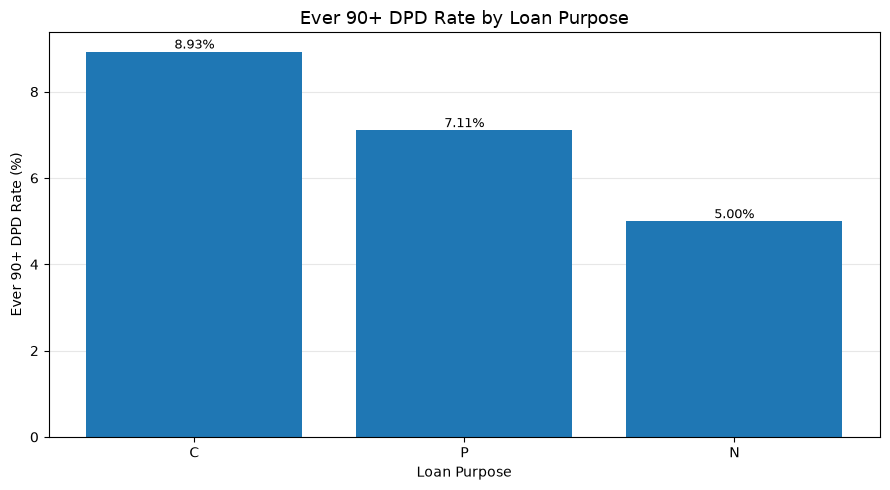

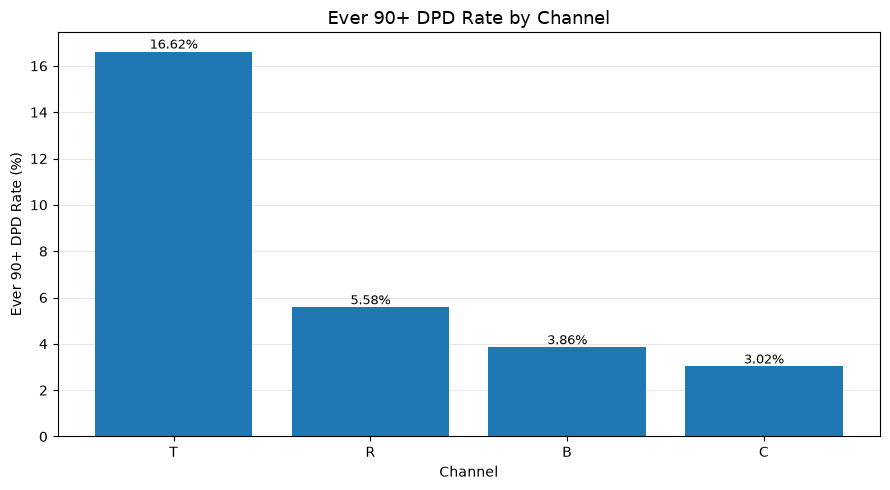

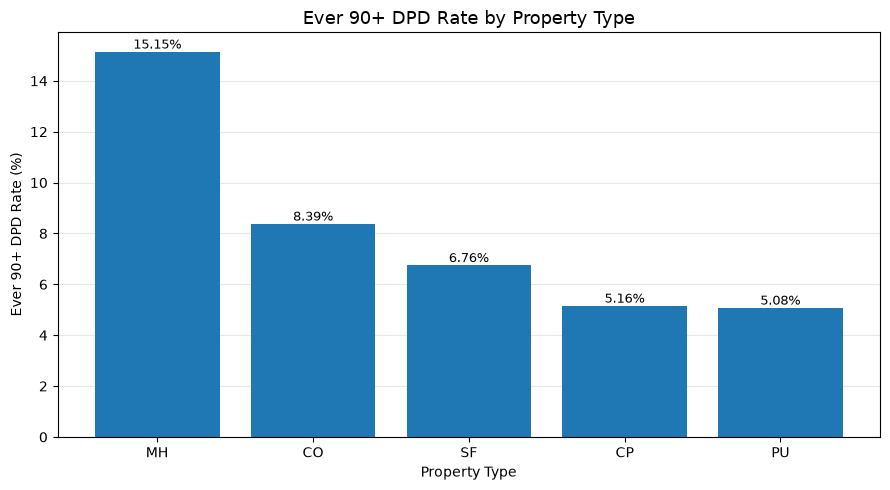

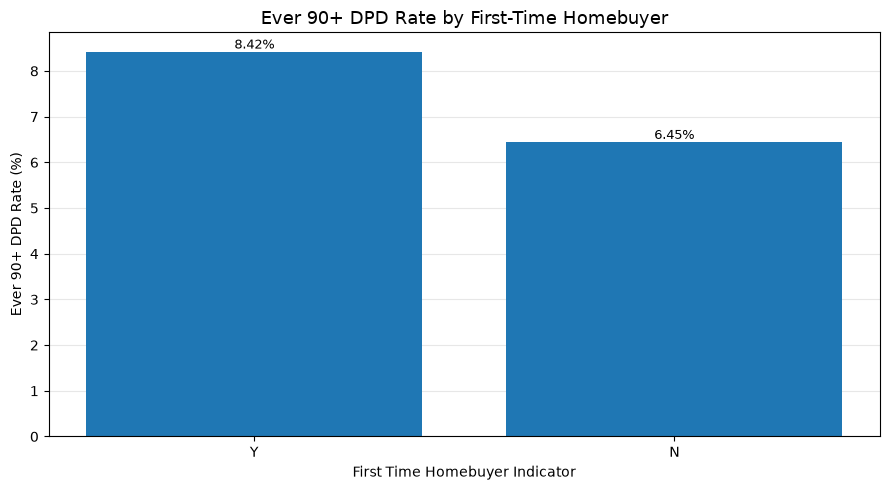

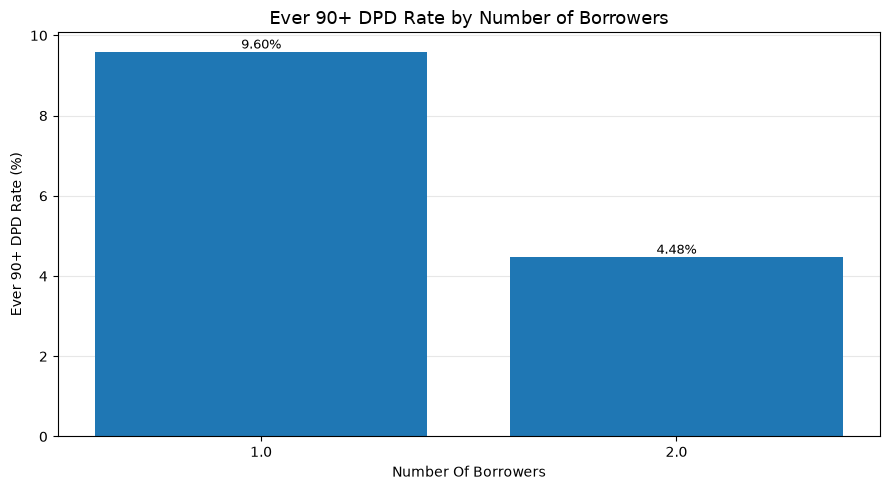

All categorical risk charts saved successfully.


In [22]:

# ============================================================
# CELL 4D.5 — CATEGORICAL RISK VISUALIZATION
# ============================================================

plot_variables = [
    "occupancy_status",
    "loan_purpose",
    "channel",
    "property_type",
    "first_time_homebuyer_indicator",
    "number_of_borrowers"
]

plot_titles = {
    "occupancy_status": "Ever 90+ DPD Rate by Occupancy Status",
    "loan_purpose": "Ever 90+ DPD Rate by Loan Purpose",
    "channel": "Ever 90+ DPD Rate by Channel",
    "property_type": "Ever 90+ DPD Rate by Property Type",
    "first_time_homebuyer_indicator":
        "Ever 90+ DPD Rate by First-Time Homebuyer",
    "number_of_borrowers":
        "Ever 90+ DPD Rate by Number of Borrowers"
}

for variable in plot_variables:

    plot_data = overall_categorical_df[
        overall_categorical_df["variable_name"] == variable
    ].copy()

    # Exclude categories with unknown or missing values
    plot_data = plot_data[
        plot_data["category"] != "MISSING/UNKNOWN"
    ]

    plot_data = plot_data.sort_values(
        "ever_90dpd_rate_pct",
        ascending=False
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(
        plot_data["category"],
        plot_data["ever_90dpd_rate_pct"]
    )

    ax.set_title(plot_titles[variable], fontsize=13)
    ax.set_xlabel(variable.replace("_", " ").title())
    ax.set_ylabel("Ever 90+ DPD Rate (%)")

    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    for bar, value in zip(
        bars,
        plot_data["ever_90dpd_rate_pct"]
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

    plt.tight_layout()

    output_file = (
        CHART_DIR /
        f"categorical_risk_{variable}.png"
    )

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("All categorical risk charts saved successfully.")


In [24]:

from pathlib import Path

all_cleaned_files = sorted(
    EDA_DATA_DIR.glob("loan_level_clean_*.parquet")
)

print(f"Total files found: {len(all_cleaned_files)}")

for f in all_cleaned_files:
    print(f.name)


Total files found: 30
loan_level_clean_2012Q4.parquet
loan_level_clean_2012Q4_test_v2.parquet
loan_level_clean_v2_2006Q1.parquet
loan_level_clean_v2_2006Q2.parquet
loan_level_clean_v2_2006Q3.parquet
loan_level_clean_v2_2006Q4.parquet
loan_level_clean_v2_2007Q1.parquet
loan_level_clean_v2_2007Q2.parquet
loan_level_clean_v2_2007Q3.parquet
loan_level_clean_v2_2007Q4.parquet
loan_level_clean_v2_2008Q1.parquet
loan_level_clean_v2_2008Q2.parquet
loan_level_clean_v2_2008Q3.parquet
loan_level_clean_v2_2008Q4.parquet
loan_level_clean_v2_2009Q1.parquet
loan_level_clean_v2_2009Q2.parquet
loan_level_clean_v2_2009Q3.parquet
loan_level_clean_v2_2009Q4.parquet
loan_level_clean_v2_2010Q1.parquet
loan_level_clean_v2_2010Q2.parquet
loan_level_clean_v2_2010Q3.parquet
loan_level_clean_v2_2010Q4.parquet
loan_level_clean_v2_2011Q1.parquet
loan_level_clean_v2_2011Q2.parquet
loan_level_clean_v2_2011Q3.parquet
loan_level_clean_v2_2011Q4.parquet
loan_level_clean_v2_2012Q1.parquet
loan_level_clean_v2_2012Q2.parq

CELL 4E — VINTAGE AND TEMPORAL RISK ANALYSIS
Official cleaned files: 28
Expected loans: 11,128,442
Input directory: E:\DS_project_backup\credit-risk-portfolio\processed\eda\loan_level


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


OVERALL VINTAGE-LEVEL PORTFOLIO AND RISK
vintage  total_loans  unique_loans  total_original_upb  avg_original_upb  avg_fico  avg_dti  avg_ltv  avg_cltv  avg_interest_rate  loans_ever_30dpd  loans_ever_60dpd  loans_ever_90dpd  credit_related_terminations  loans_with_actual_loss  harp_loans  non_harp_loans  loan_share_pct  ever_30dpd_rate_pct  ever_60dpd_rate_pct  ever_90dpd_rate_pct  credit_termination_rate_pct  harp_share_pct  actual_loss_availability_pct
 2006Q1       298574        298574        5.272702e+10         176596.16    721.98    36.29    69.32     71.34               6.22           76819.0           50451.0           42609.0                      22727.0                 22792.0         0.0        298574.0            2.68                25.73                16.90                14.27                         7.61            0.00                          7.63
 2006Q2       308208        308208        5.463489e+10         177266.29    724.19    36.46    70.28     72.86          

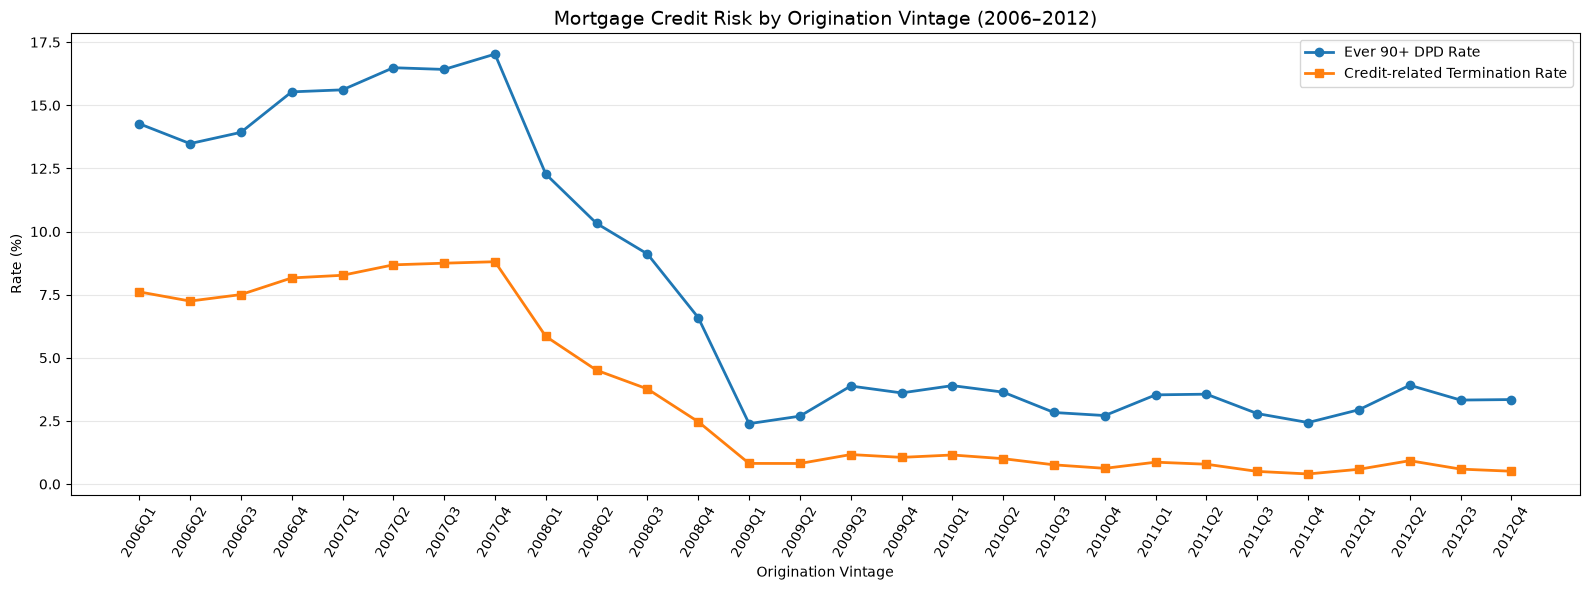

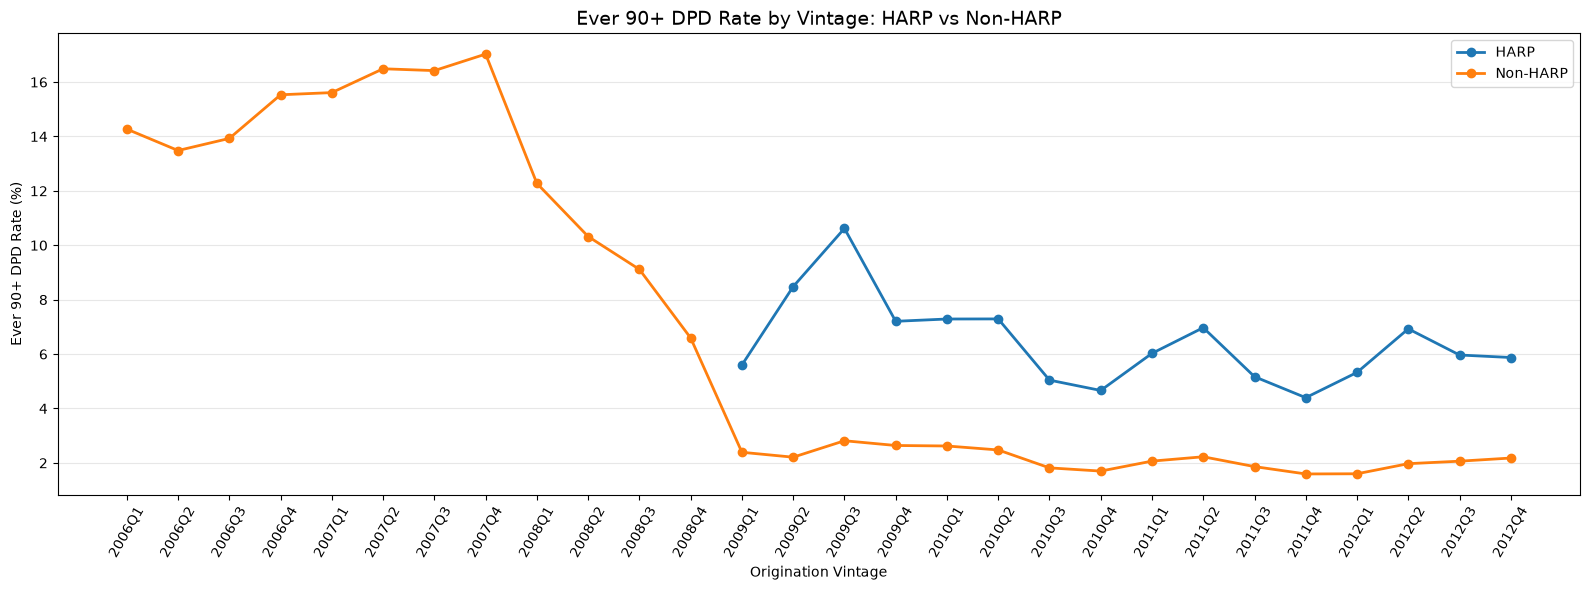

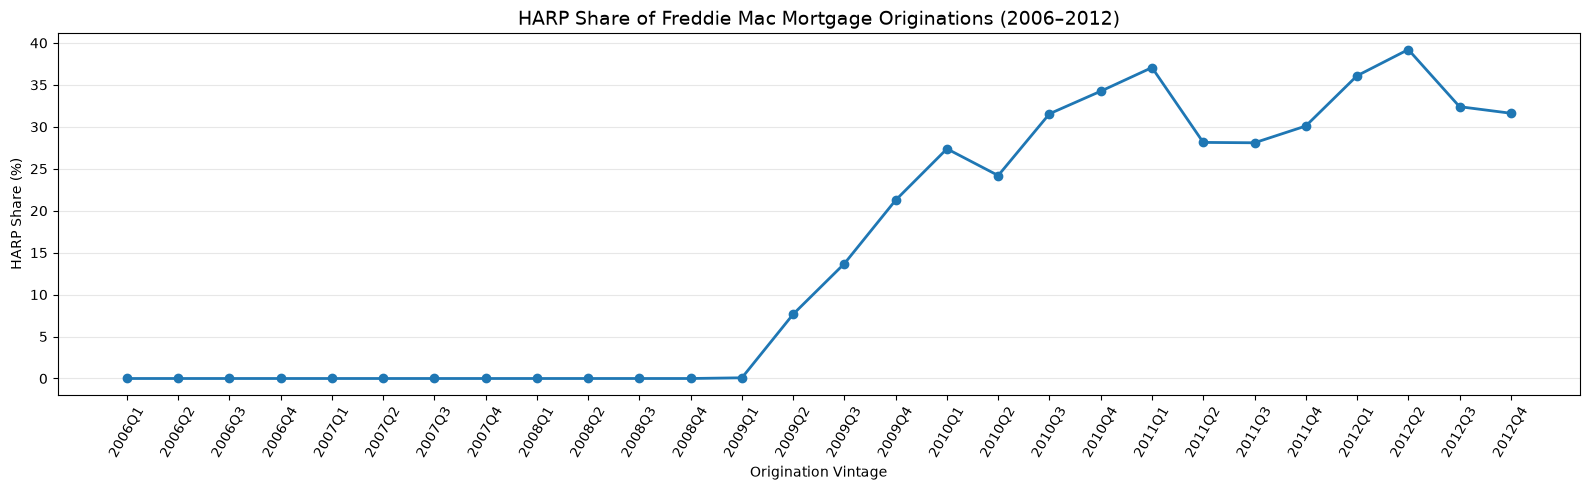


CELL 4E COMPLETED SUCCESSFULLY
Total loans: 11,128,442
Unique loans: 11,128,442
Number of vintages: 28
Execution time: 10.32 seconds

Saved tables:
1. vintage_overview_and_risk.csv
2. vintage_risk_by_harp.csv
3. vintage_portfolio_composition.csv

Saved charts:
1. vintage_credit_risk_trends.png
2. vintage_90dpd_harp_comparison.png
3. vintage_harp_share.png

Output directory: E:\DS_project_backup\credit-risk-portfolio\processed\eda\notebook_06


9441

In [27]:

# ============================================================
# CELL 4E — VINTAGE AND TEMPORAL RISK ANALYSIS
# Freddie Mac Single-Family Mortgage Data (2006–2012)
# ============================================================

import re
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 90)
print("CELL 4E — VINTAGE AND TEMPORAL RISK ANALYSIS")
print("=" * 90)


# ============================================================
# 1. CONFIGURATION AND INPUT FILE VALIDATION
# ============================================================

# Official cleaned files only:
# loan_level_clean_v2_YYYYQn.parquet

cleaned_files = sorted([
    f for f in EDA_DATA_DIR.glob("loan_level_clean_v2_*.parquet")
    if re.fullmatch(
        r"loan_level_clean_v2_\d{4}Q[1-4]",
        f.stem
    )
])

file_paths = [str(f) for f in cleaned_files]

expected_vintages = set(VINTAGES)

found_vintages = {
    f.stem.replace("loan_level_clean_v2_", "")
    for f in cleaned_files
}

assert len(cleaned_files) == 28, (
    f"Expected 28 official cleaned files, found {len(cleaned_files)}"
)

assert found_vintages == expected_vintages, (
    f"Missing vintages: "
    f"{sorted(expected_vintages - found_vintages)}"
)

print(f"Official cleaned files: {len(cleaned_files)}")
print(f"Expected loans: {EXPECTED_LOANS:,}")
print(f"Input directory: {EDA_DATA_DIR}")


# ============================================================
# 2. OVERALL VINTAGE-LEVEL PORTFOLIO AND RISK ANALYSIS
# ============================================================

start_time = time.time()

vintage_overview = con.execute("""
    SELECT
        vintage,

        COUNT(*) AS total_loans,

        COUNT(DISTINCT loan_identifier) AS unique_loans,

        SUM(original_upb_num) AS total_original_upb,

        AVG(original_upb_num) AS avg_original_upb,

        AVG(classic_fico_num) AS avg_fico,

        AVG(original_dti_num) AS avg_dti,

        AVG(original_ltv_num) AS avg_ltv,

        AVG(original_cltv_num) AS avg_cltv,

        AVG(original_interest_rate_num) AS avg_interest_rate,

        SUM(ever_30dpd) AS loans_ever_30dpd,

        SUM(ever_60dpd) AS loans_ever_60dpd,

        SUM(ever_90dpd) AS loans_ever_90dpd,

        SUM(credit_related_termination)
            AS credit_related_terminations,

        SUM(actual_loss_available)
            AS loans_with_actual_loss,

        SUM(
            CASE WHEN harp_indicator = 'Y'
            THEN 1 ELSE 0 END
        ) AS harp_loans,

        SUM(
            CASE WHEN harp_indicator = 'N'
            THEN 1 ELSE 0 END
        ) AS non_harp_loans

    FROM read_parquet(?)

    GROUP BY vintage

    ORDER BY vintage

""", [file_paths]).df()


# ------------------------------------------------------------
# Calculate portfolio and risk rates
# ------------------------------------------------------------

vintage_overview["loan_share_pct"] = (
    vintage_overview["total_loans"]
    / vintage_overview["total_loans"].sum() * 100
)

vintage_overview["ever_30dpd_rate_pct"] = (
    vintage_overview["loans_ever_30dpd"]
    / vintage_overview["total_loans"] * 100
)

vintage_overview["ever_60dpd_rate_pct"] = (
    vintage_overview["loans_ever_60dpd"]
    / vintage_overview["total_loans"] * 100
)

vintage_overview["ever_90dpd_rate_pct"] = (
    vintage_overview["loans_ever_90dpd"]
    / vintage_overview["total_loans"] * 100
)

vintage_overview["credit_termination_rate_pct"] = (
    vintage_overview["credit_related_terminations"]
    / vintage_overview["total_loans"] * 100
)

vintage_overview["harp_share_pct"] = (
    vintage_overview["harp_loans"]
    / vintage_overview["total_loans"] * 100
)

vintage_overview["actual_loss_availability_pct"] = (
    vintage_overview["loans_with_actual_loss"]
    / vintage_overview["total_loans"] * 100
)


print("\n" + "=" * 90)
print("OVERALL VINTAGE-LEVEL PORTFOLIO AND RISK")
print("=" * 90)

print(
    vintage_overview.round(2).to_string(index=False)
)


# ============================================================
# 3. VINTAGE RISK COMPARISON BY HARP STATUS
# ============================================================

harp_vintage_risk = con.execute("""
    SELECT

        vintage,

        CASE
            WHEN TRIM(harp_indicator) = 'Y'
                THEN 'HARP'

            WHEN TRIM(harp_indicator) = 'N'
                THEN 'Non-HARP'

            ELSE 'Unknown'
        END AS loan_group,

        COUNT(*) AS total_loans,

        AVG(original_upb_num) AS avg_original_upb,

        AVG(classic_fico_num) AS avg_fico,

        AVG(original_dti_num) AS avg_dti,

        AVG(original_ltv_num) AS avg_ltv,

        AVG(original_cltv_num) AS avg_cltv,

        SUM(ever_30dpd) AS loans_ever_30dpd,

        SUM(ever_60dpd) AS loans_ever_60dpd,

        SUM(ever_90dpd) AS loans_ever_90dpd,

        SUM(credit_related_termination)
            AS credit_related_terminations

    FROM read_parquet(?)

    GROUP BY vintage, loan_group

    ORDER BY vintage, loan_group

""", [file_paths]).df()


harp_vintage_risk["ever_30dpd_rate_pct"] = (
    harp_vintage_risk["loans_ever_30dpd"]
    / harp_vintage_risk["total_loans"] * 100
)

harp_vintage_risk["ever_60dpd_rate_pct"] = (
    harp_vintage_risk["loans_ever_60dpd"]
    / harp_vintage_risk["total_loans"] * 100
)

harp_vintage_risk["ever_90dpd_rate_pct"] = (
    harp_vintage_risk["loans_ever_90dpd"]
    / harp_vintage_risk["total_loans"] * 100
)

harp_vintage_risk["credit_termination_rate_pct"] = (
    harp_vintage_risk["credit_related_terminations"]
    / harp_vintage_risk["total_loans"] * 100
)


print("\n" + "=" * 90)
print("VINTAGE RISK BY HARP STATUS")
print("=" * 90)

print(
    harp_vintage_risk.round(2).to_string(index=False)
)


# ============================================================
# 4. VINTAGE PORTFOLIO COMPOSITION
# ============================================================

vintage_composition = con.execute("""
    SELECT

        vintage,

        COUNT(*) AS total_loans,

        SUM(original_upb_num) AS total_original_upb,

        AVG(original_upb_num) AS avg_original_upb,

        AVG(classic_fico_num) AS avg_fico,

        AVG(original_dti_num) AS avg_dti,

        AVG(original_ltv_num) AS avg_ltv,

        AVG(original_cltv_num) AS avg_cltv,

        AVG(original_interest_rate_num) AS avg_interest_rate,

        SUM(
            CASE WHEN harp_indicator = 'Y'
            THEN 1 ELSE 0 END
        ) AS harp_loans

    FROM read_parquet(?)

    GROUP BY vintage

    ORDER BY vintage

""", [file_paths]).df()


vintage_composition["harp_share_pct"] = (
    vintage_composition["harp_loans"]
    / vintage_composition["total_loans"] * 100
)

vintage_composition["loan_share_pct"] = (
    vintage_composition["total_loans"]
    / vintage_composition["total_loans"].sum() * 100
)


print("\n" + "=" * 90)
print("VINTAGE PORTFOLIO COMPOSITION")
print("=" * 90)

print(
    vintage_composition.round(2).to_string(index=False)
)


# ============================================================
# 5. SAVE ANALYTICAL TABLES
# ============================================================

OUTPUT_TABLE_DIR = NOTEBOOK_06_DIR / "tables"
OUTPUT_CHART_DIR = NOTEBOOK_06_DIR / "charts"

OUTPUT_TABLE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_CHART_DIR.mkdir(parents=True, exist_ok=True)


vintage_overview.to_csv(
    OUTPUT_TABLE_DIR / "vintage_overview_and_risk.csv",
    index=False
)

harp_vintage_risk.to_csv(
    OUTPUT_TABLE_DIR / "vintage_risk_by_harp.csv",
    index=False
)

vintage_composition.to_csv(
    OUTPUT_TABLE_DIR / "vintage_portfolio_composition.csv",
    index=False
)

print("\nAll analytical tables saved.")


# ============================================================
# 6. CHART 1 — VINTAGE CREDIT RISK TRENDS
# ============================================================

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    vintage_overview["vintage"],
    vintage_overview["ever_90dpd_rate_pct"],
    marker="o",
    linewidth=2,
    label="Ever 90+ DPD Rate"
)

ax.plot(
    vintage_overview["vintage"],
    vintage_overview["credit_termination_rate_pct"],
    marker="s",
    linewidth=2,
    label="Credit-related Termination Rate"
)

ax.set_title(
    "Mortgage Credit Risk by Origination Vintage (2006–2012)",
    fontsize=14
)

ax.set_xlabel("Origination Vintage")
ax.set_ylabel("Rate (%)")

ax.tick_params(axis="x", rotation=60)

ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_CHART_DIR / "vintage_credit_risk_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 7. CHART 2 — EVER 90+ DPD BY HARP STATUS
# ============================================================


fig, ax = plt.subplots(figsize=(16, 6))

# 1. Define chronological vintage order
vintage_order = sorted(
    harp_vintage_risk["vintage"].astype(str).unique()
)

# Map each vintage to a fixed numeric position
vintage_positions = {
    vintage: i
    for i, vintage in enumerate(vintage_order)
}

# 2. Use a clean copy of the original table
plot_data = harp_vintage_risk.copy()

plot_data["vintage"] = plot_data["vintage"].astype(str)

# Minimum sample size
MIN_GROUP_SIZE = 100

# 3. Plot each group using the SAME numeric x-axis
for group in ["HARP", "Non-HARP"]:

    subset = plot_data[
        (plot_data["loan_group"] == group) &
        (plot_data["total_loans"] >= MIN_GROUP_SIZE)
    ].copy()

    subset["x_position"] = (
        subset["vintage"].map(vintage_positions)
    )

    subset = subset.sort_values("x_position")

    ax.plot(
        subset["x_position"],
        subset["ever_90dpd_rate_pct"],
        marker="o",
        linewidth=2,
        label=group
    )

# 4. Set chronological tick labels explicitly
ax.set_xticks(range(len(vintage_order)))

ax.set_xticklabels(
    vintage_order,
    rotation=60
)

# 5. Chart formatting
ax.set_title(
    "Ever 90+ DPD Rate by Vintage: HARP vs Non-HARP",
    fontsize=14
)

ax.set_xlabel("Origination Vintage")
ax.set_ylabel("Ever 90+ DPD Rate (%)")

ax.grid(axis="y", alpha=0.3)

ax.legend()

plt.tight_layout()

# 6. Save chart
plt.savefig(
    OUTPUT_CHART_DIR / "vintage_90dpd_harp_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 8. CHART 3 — HARP PORTFOLIO SHARE OVER TIME
# ============================================================

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    vintage_composition["vintage"],
    vintage_composition["harp_share_pct"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "HARP Share of Freddie Mac Mortgage Originations (2006–2012)",
    fontsize=14
)

ax.set_xlabel("Origination Vintage")
ax.set_ylabel("HARP Share (%)")

ax.tick_params(axis="x", rotation=60)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_CHART_DIR / "vintage_harp_share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 9. FINAL DATA INTEGRITY VALIDATION
# ============================================================

total_vintage_loans = int(
    vintage_overview["total_loans"].sum()
)

total_unique_loans = int(
    vintage_overview["unique_loans"].sum()
)

assert total_vintage_loans == EXPECTED_LOANS, (
    f"Loan count mismatch: {total_vintage_loans:,}"
)

assert total_unique_loans == EXPECTED_LOANS, (
    f"Unique loan count mismatch: {total_unique_loans:,}"
)

assert vintage_overview["vintage"].nunique() == 28

assert vintage_overview["total_loans"].notna().all()

assert (
    vintage_overview["loans_ever_90dpd"]
    <= vintage_overview["total_loans"]
).all()

assert (
    vintage_overview["credit_related_terminations"]
    <= vintage_overview["total_loans"]
).all()


# ============================================================
# 10. COMPLETION SUMMARY
# ============================================================

elapsed_time = time.time() - start_time

print("\n" + "=" * 90)
print("CELL 4E COMPLETED SUCCESSFULLY")
print("=" * 90)

print(f"Total loans: {total_vintage_loans:,}")
print(f"Unique loans: {total_unique_loans:,}")
print(f"Number of vintages: {vintage_overview['vintage'].nunique()}")
print(f"Execution time: {elapsed_time:.2f} seconds")

print("\nSaved tables:")
print("1. vintage_overview_and_risk.csv")
print("2. vintage_risk_by_harp.csv")
print("3. vintage_portfolio_composition.csv")

print("\nSaved charts:")
print("1. vintage_credit_risk_trends.png")
print("2. vintage_90dpd_harp_comparison.png")
print("3. vintage_harp_share.png")

print(f"\nOutput directory: {NOTEBOOK_06_DIR}")

gc.collect()


In [28]:

# Inspect the loan-level dataset schema

sample_file = (
    EDA_DATA_DIR / "loan_level_clean_v2_2012Q4.parquet"
)

schema_check = con.execute("""
    DESCRIBE
    SELECT *
    FROM read_parquet(?)
""", [str(sample_file)]).df()

display(schema_check)


,column_name,column_type,null,key,default,extra
0,classic_fico,VARCHAR,YES,None,None,None
1,first_payment_date,VARCHAR,YES,None,None,None
2,first_time_homebuyer_indicator,VARCHAR,YES,None,None,None
3,maturity_date,VARCHAR,YES,None,None,None
4,metropolitan_statistical_area_msa_or_metropoli...,VARCHAR,YES,None,None,None
...,...,...,...,...,...,...
61,ltv_outside_guide_range,INTEGER,YES,None,None,None
62,cltv_outside_guide_range,INTEGER,YES,None,None,None
63,harp_oltv_inconsistency,INTEGER,YES,None,None,None
64,harp_ltv_extreme,INTEGER,YES,None,None,None


In [29]:

# ============================================================
# CELL 4F — PREPARATION: IDENTIFY DATE AND OUTCOME VARIABLES
# ============================================================

sample_file = (
    EDA_DATA_DIR / "loan_level_clean_v2_2012Q4.parquet"
)

schema_check = con.execute("""
    DESCRIBE
    SELECT *
    FROM read_parquet(?)
""", [str(sample_file)]).df()

# Display all columns potentially relevant to seasoning analysis
keywords = [
    "date",
    "period",
    "90",
    "60",
    "30",
    "delinquency",
    "dpd",
    "event",
    "termination",
    "zero_balance"
]

relevant_columns = schema_check[
    schema_check["column_name"].str.lower().apply(
        lambda col: any(keyword in col for keyword in keywords)
    )
]

print("=" * 80)
print("RELEVANT DATE AND OUTCOME COLUMNS")
print("=" * 80)

print(
    relevant_columns[
        ["column_name", "column_type"]
    ].to_string(index=False)
)

print("\nAll date-related columns:")
print(
    schema_check[
        schema_check["column_name"].str.lower().str.contains(
            "date|period", regex=True
        )
    ][["column_name", "column_type"]].to_string(index=False)
)


RELEVANT DATE AND OUTCOME COLUMNS
                   column_name column_type
            first_payment_date     VARCHAR
                 maturity_date     VARCHAR
         first_observed_period     VARCHAR
          last_observed_period     VARCHAR
                    ever_30dpd     INTEGER
                    ever_60dpd     INTEGER
                    ever_90dpd     INTEGER
            first_90dpd_period     VARCHAR
max_numeric_delinquency_status     INTEGER
    terminal_zero_balance_code     VARCHAR
     terminal_reporting_period     VARCHAR
   zero_balance_effective_date     VARCHAR
    credit_related_termination     INTEGER
         voluntary_termination     INTEGER
            defect_termination     INTEGER

All date-related columns:
                column_name column_type
         first_payment_date     VARCHAR
              maturity_date     VARCHAR
      first_observed_period     VARCHAR
       last_observed_period     VARCHAR
         first_90dpd_period     VARCHAR
  terminal_

In [30]:

# ============================================================
# CELL 4F — DATE STRUCTURE AND OBSERVATION WINDOW AUDIT
# ============================================================

sample_vintages = [
    "2006Q1",
    "2009Q1",
    "2012Q4"
]

for vintage in sample_vintages:

    sample_file = (
        EDA_DATA_DIR /
        f"loan_level_clean_v2_{vintage}.parquet"
    )

    print("\n" + "=" * 100)
    print(f"DATE STRUCTURE AUDIT — {vintage}")
    print("=" * 100)

    date_sample = con.execute("""
        SELECT
            loan_identifier,
            first_payment_date,
            first_observed_period,
            last_observed_period,
            first_90dpd_period,
            terminal_reporting_period,
            terminal_zero_balance_code,
            ever_90dpd

        FROM read_parquet(?)

        WHERE first_payment_date IS NOT NULL

        ORDER BY loan_identifier

        LIMIT 15

    """, [str(sample_file)]).df()

    display(date_sample)


# ============================================================
# CHECK DATE VALUE FORMATS
# ============================================================

print("\n" + "=" * 100)
print("DATE FORMAT SUMMARY — 2012Q4")
print("=" * 100)

sample_file = (
    EDA_DATA_DIR /
    "loan_level_clean_v2_2012Q4.parquet"
)

date_format_summary = con.execute("""
    SELECT

        'first_payment_date' AS variable,
        first_payment_date AS date_value,
        COUNT(*) AS observations

    FROM read_parquet(?)

    GROUP BY first_payment_date

    ORDER BY observations DESC

    LIMIT 10

""", [str(sample_file)]).df()

display(date_format_summary)



DATE STRUCTURE AUDIT — 2006Q1


,loan_identifier,first_payment_date,first_observed_period,last_observed_period,first_90dpd_period,terminal_reporting_period,terminal_zero_balance_code,ever_90dpd
0,F06Q10000001,200604,200603,200905,NaN,200905,01,0
1,F06Q10000002,200604,200603,200902,NaN,200902,01,0
2,F06Q10000003,200604,200603,201205,NaN,201205,01,0
3,F06Q10000004,200602,200601,200704,NaN,200704,01,0
4,F06Q10000005,200605,200604,201007,NaN,201007,01,0
5,F06Q10000006,200603,200602,201304,NaN,201304,01,0
6,F06Q10000007,200603,200602,200908,NaN,200908,01,0
7,F06Q10000008,200605,200604,201109,200808,201109,02,1
8,F06Q10000009,200604,200603,200802,NaN,200802,01,0
9,F06Q10000010,200603,200602,200905,NaN,200905,01,0



DATE STRUCTURE AUDIT — 2009Q1


,loan_identifier,first_payment_date,first_observed_period,last_observed_period,first_90dpd_period,terminal_reporting_period,terminal_zero_balance_code,ever_90dpd
0,F09Q10000001,200904,200903,201301,None,201301,01,0
1,F09Q10000002,200903,200902,201212,None,201212,01,0
2,F09Q10000003,200905,200904,201512,None,201512,01,0
3,F09Q10000004,200905,200904,201205,None,201205,01,0
4,F09Q10000005,200903,200902,201607,None,201607,01,0
5,F09Q10000006,200903,200902,201007,None,201007,01,0
6,F09Q10000007,200904,200903,201401,None,201401,01,0
7,F09Q10000008,200903,200902,201304,None,201304,01,0
8,F09Q10000009,200903,200902,201210,None,201210,01,0
9,F09Q10000010,200904,200903,201105,None,201105,01,0



DATE STRUCTURE AUDIT — 2012Q4


,loan_identifier,first_payment_date,first_observed_period,last_observed_period,first_90dpd_period,terminal_reporting_period,terminal_zero_balance_code,ever_90dpd
0,F12Q40000001,201301,201212,202606,None,NaN,NaN,0
1,F12Q40000002,201302,201301,202007,None,202007,01,0
2,F12Q40000003,201212,201301,202104,None,202104,01,0
3,F12Q40000004,201212,201211,202606,None,NaN,NaN,0
4,F12Q40000005,201212,201211,202606,None,NaN,NaN,0
5,F12Q40000006,201212,201301,202211,None,202211,01,0
6,F12Q40000007,201302,201301,202606,None,NaN,NaN,0
7,F12Q40000008,201301,201212,202107,None,202107,01,0
8,F12Q40000009,201302,201301,201510,None,201510,01,0
9,F12Q40000010,201302,201301,202606,None,NaN,NaN,0



DATE FORMAT SUMMARY — 2012Q4


,variable,date_value,observations
0,first_payment_date,201212,202739
1,first_payment_date,201302,194607
2,first_payment_date,201301,181895
3,first_payment_date,201303,7525
4,first_payment_date,201211,5441
5,first_payment_date,201308,82
6,first_payment_date,201309,64
7,first_payment_date,201306,59
8,first_payment_date,201307,57
9,first_payment_date,201310,48


In [32]:

# ============================================================
# CELL 4F — DATE AND EVENT-TIME DATA QUALITY AUDIT
# ============================================================

print("=" * 90)
print("CELL 4F — DATE AND EVENT-TIME DATA QUALITY AUDIT")
print("=" * 90)

# YYYYMM -> integer month index
# This avoids unnecessary date parsing and supports month arithmetic.

date_audit = con.execute("""
    WITH base AS (

        SELECT
            vintage,
            loan_identifier,
            first_payment_date,
            first_observed_period,
            last_observed_period,
            first_90dpd_period,
            terminal_reporting_period,
            terminal_zero_balance_code,
            ever_90dpd,
            credit_related_termination,
            voluntary_termination

        FROM read_parquet(?)

    ),

    parsed AS (

        SELECT *,

            CASE
                WHEN regexp_full_match(
                    CAST(first_payment_date AS VARCHAR),
                    '[0-9]{6}'
                )
                AND CAST(SUBSTR(
                    CAST(first_payment_date AS VARCHAR), 5, 2
                ) AS INTEGER) BETWEEN 1 AND 12

                THEN
                    CAST(SUBSTR(
                        CAST(first_payment_date AS VARCHAR), 1, 4
                    ) AS INTEGER) * 12
                    +
                    CAST(SUBSTR(
                        CAST(first_payment_date AS VARCHAR), 5, 2
                    ) AS INTEGER)

                ELSE NULL
            END AS payment_month,

            CASE
                WHEN regexp_full_match(
                    CAST(first_observed_period AS VARCHAR),
                    '[0-9]{6}'
                )
                AND CAST(SUBSTR(
                    CAST(first_observed_period AS VARCHAR), 5, 2
                ) AS INTEGER) BETWEEN 1 AND 12

                THEN
                    CAST(SUBSTR(
                        CAST(first_observed_period AS VARCHAR), 1, 4
                    ) AS INTEGER) * 12
                    +
                    CAST(SUBSTR(
                        CAST(first_observed_period AS VARCHAR), 5, 2
                    ) AS INTEGER)

                ELSE NULL
            END AS first_observed_month,

            CASE
                WHEN regexp_full_match(
                    CAST(last_observed_period AS VARCHAR),
                    '[0-9]{6}'
                )
                AND CAST(SUBSTR(
                    CAST(last_observed_period AS VARCHAR), 5, 2
                ) AS INTEGER) BETWEEN 1 AND 12

                THEN
                    CAST(SUBSTR(
                        CAST(last_observed_period AS VARCHAR), 1, 4
                    ) AS INTEGER) * 12
                    +
                    CAST(SUBSTR(
                        CAST(last_observed_period AS VARCHAR), 5, 2
                    ) AS INTEGER)

                ELSE NULL
            END AS last_observed_month,

            CASE
                WHEN regexp_full_match(
                    CAST(first_90dpd_period AS VARCHAR),
                    '[0-9]{6}'
                )
                AND CAST(SUBSTR(
                    CAST(first_90dpd_period AS VARCHAR), 5, 2
                ) AS INTEGER) BETWEEN 1 AND 12

                THEN
                    CAST(SUBSTR(
                        CAST(first_90dpd_period AS VARCHAR), 1, 4
                    ) AS INTEGER) * 12
                    +
                    CAST(SUBSTR(
                        CAST(first_90dpd_period AS VARCHAR), 5, 2
                    ) AS INTEGER)

                ELSE NULL
            END AS first_90_month,

            CASE
                WHEN regexp_full_match(
                    CAST(terminal_reporting_period AS VARCHAR),
                    '[0-9]{6}'
                )
                AND CAST(SUBSTR(
                    CAST(terminal_reporting_period AS VARCHAR), 5, 2
                ) AS INTEGER) BETWEEN 1 AND 12

                THEN
                    CAST(SUBSTR(
                        CAST(terminal_reporting_period AS VARCHAR), 1, 4
                    ) AS INTEGER) * 12
                    +
                    CAST(SUBSTR(
                        CAST(terminal_reporting_period AS VARCHAR), 5, 2
                    ) AS INTEGER)

                ELSE NULL
            END AS terminal_month

        FROM base
    )

    SELECT

        vintage,

        COUNT(*) AS total_loans,

        COUNT(payment_month) AS valid_first_payment_date,

        COUNT(first_observed_month) AS valid_first_observed_period,

        COUNT(last_observed_month) AS valid_last_observed_period,

        COUNT(first_90_month) AS loans_with_first_90dpd_date,

        COUNT(terminal_month) AS loans_with_terminal_date,

        SUM(
            CASE
                WHEN payment_month IS NULL THEN 1 ELSE 0
            END
        ) AS invalid_payment_date,

        SUM(
            CASE
                WHEN first_90_month < payment_month THEN 1 ELSE 0
            END
        ) AS "90dpd_before_first_payment",

        SUM(
            CASE
                WHEN terminal_month < payment_month THEN 1 ELSE 0
            END
        ) AS termination_before_first_payment,

        SUM(
            CASE
                WHEN first_observed_month > payment_month THEN 1 ELSE 0
            END
        ) AS first_observation_after_payment,

        SUM(
            CASE
                WHEN first_observed_month < payment_month THEN 1 ELSE 0
            END
        ) AS first_observation_before_payment,

        SUM(
            CASE
                WHEN first_90_month IS NOT NULL
                 AND payment_month IS NOT NULL
                THEN first_90_month - payment_month
                ELSE NULL
            END
        ) AS sum_months_to_90dpd,

        MIN(
            CASE
                WHEN first_90_month IS NOT NULL
                 AND payment_month IS NOT NULL
                THEN first_90_month - payment_month
                ELSE NULL
            END
        ) AS min_months_to_90dpd,

        MAX(
            CASE
                WHEN first_90_month IS NOT NULL
                 AND payment_month IS NOT NULL
                THEN first_90_month - payment_month
                ELSE NULL
            END
        ) AS max_months_to_90dpd

    FROM parsed

    GROUP BY vintage

    ORDER BY vintage

""", [file_paths]).df()


# ============================================================
# DISPLAY AUDIT RESULTS
# ============================================================

print("\nDATE QUALITY BY VINTAGE")

display(date_audit)


# ============================================================
# AGGREGATE VALIDATION
# ============================================================

print("\n" + "=" * 90)
print("AGGREGATE DATE QUALITY SUMMARY")
print("=" * 90)

summary_columns = [
    "total_loans",
    "valid_first_payment_date",
    "valid_first_observed_period",
    "valid_last_observed_period",
    "loans_with_first_90dpd_date",
    "loans_with_terminal_date",
    "invalid_payment_date",
    "90dpd_before_first_payment",
    "termination_before_first_payment",
    "first_observation_after_payment",
    "first_observation_before_payment"
]

for column in summary_columns:

    print(
        f"{column:40s}: "
        f"{date_audit[column].sum():,}"
    )


# ============================================================
# SAVE AUDIT TABLE
# ============================================================

date_audit.to_csv(
    OUTPUT_TABLE_DIR / "vintage_date_event_time_audit.csv",
    index=False
)

print("\nAudit table saved:")
print(
    OUTPUT_TABLE_DIR /
    "vintage_date_event_time_audit.csv"
)

print("\nCELL 4F DATE AUDIT COMPLETED.")


CELL 4F — DATE AND EVENT-TIME DATA QUALITY AUDIT


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


DATE QUALITY BY VINTAGE


,vintage,total_loans,valid_first_payment_date,valid_first_observed_period,valid_last_observed_period,loans_with_first_90dpd_date,loans_with_terminal_date,invalid_payment_date,90dpd_before_first_payment,termination_before_first_payment,first_observation_after_payment,first_observation_before_payment,sum_months_to_90dpd,min_months_to_90dpd,max_months_to_90dpd
0,2006Q1,298574,298574,298574,298574,42609,292114,0.0,13.0,180.0,27572.0,247294.0,2356320.0,-23,243
1,2006Q2,308208,308208,308208,308208,41558,302518,0.0,9.0,190.0,30091.0,253245.0,2148167.0,-1,239
2,2006Q3,283975,283975,283975,283975,39554,278357,0.0,7.0,263.0,22311.0,238195.0,1942311.0,-18,236
3,2006Q4,302787,302787,302787,302787,47031,295642,0.0,19.0,191.0,22530.0,250397.0,2270254.0,-62,234
4,2007Q1,302331,302331,302331,302331,47202,294949,0.0,12.0,145.0,31949.0,247928.0,2195015.0,-51,230
5,2007Q2,354055,354055,354055,354055,58380,344895,0.0,7.0,196.0,34066.0,287299.0,2559643.0,-39,228
6,2007Q3,284980,284980,284980,284980,46797,278371,0.0,10.0,204.0,17737.0,245176.0,1871575.0,-77,225
7,2007Q4,296826,296826,296826,296826,50544,289429,0.0,20.0,300.0,11514.0,261596.0,1921387.0,-5,222
8,2008Q1,421635,421635,421635,421635,51757,411994,0.0,12.0,421.0,10198.0,386340.0,2032364.0,-70,218
9,2008Q2,370982,370982,370982,370982,38296,362455,0.0,18.0,307.0,14680.0,335892.0,1510058.0,-28,216



AGGREGATE DATE QUALITY SUMMARY
total_loans                             : 11,128,442
valid_first_payment_date                : 11,128,442
valid_first_observed_period             : 11,128,442
valid_last_observed_period              : 11,128,442
loans_with_first_90dpd_date             : 734,001
loans_with_terminal_date                : 10,321,281
invalid_payment_date                    : 0.0
90dpd_before_first_payment              : 156.0
termination_before_first_payment        : 5,945.0
first_observation_after_payment         : 428,929.0
first_observation_before_payment        : 9,814,812.0

Audit table saved:
E:\DS_project_backup\credit-risk-portfolio\processed\eda\notebook_06\tables\vintage_date_event_time_audit.csv

CELL 4F DATE AUDIT COMPLETED.


In [33]:

# ============================================================
# CELL 4F.2 — ANOMALOUS DATE INVESTIGATION
# ============================================================

print("=" * 90)
print("CELL 4F.2 — ANOMALOUS DATE INVESTIGATION")
print("=" * 90)


# ------------------------------------------------------------
# 1. Inspect all date anomalies
# ------------------------------------------------------------

anomaly_summary = con.execute("""
    WITH base AS (

        SELECT
            vintage,
            loan_identifier,
            harp_indicator,
            first_payment_date,
            first_observed_period,
            last_observed_period,
            first_90dpd_period,
            terminal_reporting_period,
            terminal_zero_balance_code,
            ever_90dpd,
            credit_related_termination,
            voluntary_termination

        FROM read_parquet(?)

    ),

    parsed AS (

        SELECT *,

            TRY_CAST(first_payment_date AS INTEGER) AS payment_yyyymm,

            TRY_CAST(first_observed_period AS INTEGER)
                AS observed_yyyymm,

            TRY_CAST(first_90dpd_period AS INTEGER)
                AS event_yyyymm,

            TRY_CAST(terminal_reporting_period AS INTEGER)
                AS terminal_yyyymm

        FROM base
    )

    SELECT

        '90DPD_BEFORE_PAYMENT' AS anomaly_type,

        vintage,

        harp_indicator,

        terminal_zero_balance_code,

        COUNT(*) AS loan_count

    FROM parsed

    WHERE event_yyyymm IS NOT NULL
      AND event_yyyymm < payment_yyyymm

    GROUP BY
        vintage,
        harp_indicator,
        terminal_zero_balance_code

    UNION ALL

    SELECT

        'TERMINATION_BEFORE_PAYMENT' AS anomaly_type,

        vintage,

        harp_indicator,

        terminal_zero_balance_code,

        COUNT(*) AS loan_count

    FROM parsed

    WHERE terminal_yyyymm IS NOT NULL
      AND terminal_yyyymm < payment_yyyymm

    GROUP BY
        vintage,
        harp_indicator,
        terminal_zero_balance_code

    ORDER BY anomaly_type, vintage, harp_indicator

""", [file_paths]).df()


print("\nANOMALY COUNTS BY VINTAGE AND GROUP")
display(anomaly_summary)


# ------------------------------------------------------------
# 2. Inspect first observation vs first payment difference
# ------------------------------------------------------------

observation_gap = con.execute("""
    WITH base AS (

        SELECT
            vintage,
            loan_identifier,
            first_payment_date,
            first_observed_period

        FROM read_parquet(?)

    ),

    parsed AS (

        SELECT

            vintage,

            loan_identifier,

            TRY_CAST(first_payment_date AS INTEGER)
                AS payment_date,

            TRY_CAST(first_observed_period AS INTEGER)
                AS observed_date

        FROM base

    ),

    indexed AS (

        SELECT *,

            (
                CAST(SUBSTR(CAST(observed_date AS VARCHAR), 1, 4)
                    AS INTEGER) * 12
                +
                CAST(SUBSTR(CAST(observed_date AS VARCHAR), 5, 2)
                    AS INTEGER)
            )
            -
            (
                CAST(SUBSTR(CAST(payment_date AS VARCHAR), 1, 4)
                    AS INTEGER) * 12
                +
                CAST(SUBSTR(CAST(payment_date AS VARCHAR), 5, 2)
                    AS INTEGER)
            ) AS observation_gap_months

        FROM parsed

        WHERE payment_date IS NOT NULL
          AND observed_date IS NOT NULL

    )

    SELECT

        observation_gap_months,

        COUNT(*) AS loan_count,

        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            4
        ) AS share_pct

    FROM indexed

    GROUP BY observation_gap_months

    ORDER BY observation_gap_months

""", [file_paths]).df()


print("\nFIRST OBSERVATION RELATIVE TO FIRST PAYMENT")
display(observation_gap)


# ------------------------------------------------------------
# 3. Extract detailed 90+ DPD anomalies
# ------------------------------------------------------------

anomalous_90dpd = con.execute("""
    SELECT

        vintage,
        loan_identifier,
        harp_indicator,
        first_payment_date,
        first_observed_period,
        first_90dpd_period,
        terminal_reporting_period,
        terminal_zero_balance_code,
        ever_90dpd

    FROM read_parquet(?)

    WHERE first_90dpd_period IS NOT NULL

      AND TRY_CAST(first_90dpd_period AS INTEGER)
          < TRY_CAST(first_payment_date AS INTEGER)

    ORDER BY vintage, loan_identifier

""", [file_paths]).df()


print("\n90+ DPD BEFORE FIRST PAYMENT — DETAILED RECORDS")
print(f"Number of records: {len(anomalous_90dpd):,}")

display(anomalous_90dpd.head(30))


# ------------------------------------------------------------
# 4. Extract detailed termination anomalies
# ------------------------------------------------------------

anomalous_termination = con.execute("""
    SELECT

        vintage,
        loan_identifier,
        harp_indicator,
        first_payment_date,
        first_observed_period,
        terminal_reporting_period,
        terminal_zero_balance_code,
        credit_related_termination,
        voluntary_termination

    FROM read_parquet(?)

    WHERE terminal_reporting_period IS NOT NULL

      AND TRY_CAST(terminal_reporting_period AS INTEGER)
          < TRY_CAST(first_payment_date AS INTEGER)

    ORDER BY vintage, loan_identifier

""", [file_paths]).df()


print("\nTERMINATION BEFORE FIRST PAYMENT — DETAILED RECORDS")
print(f"Number of records: {len(anomalous_termination):,}")

display(anomalous_termination.head(30))


# ------------------------------------------------------------
# 5. Save investigation results
# ------------------------------------------------------------

anomaly_summary.to_csv(
    OUTPUT_TABLE_DIR / "date_anomaly_summary.csv",
    index=False
)

observation_gap.to_csv(
    OUTPUT_TABLE_DIR / "first_observation_payment_gap.csv",
    index=False
)

anomalous_90dpd.to_csv(
    OUTPUT_TABLE_DIR / "anomalous_90dpd_records.csv",
    index=False
)

anomalous_termination.to_csv(
    OUTPUT_TABLE_DIR / "anomalous_termination_records.csv",
    index=False
)


print("\n" + "=" * 90)
print("CELL 4F.2 COMPLETED")
print("=" * 90)

print("Saved:")
print("1. date_anomaly_summary.csv")
print("2. first_observation_payment_gap.csv")
print("3. anomalous_90dpd_records.csv")
print("4. anomalous_termination_records.csv")


CELL 4F.2 — ANOMALOUS DATE INVESTIGATION

ANOMALY COUNTS BY VINTAGE AND GROUP


,anomaly_type,vintage,harp_indicator,terminal_zero_balance_code,loan_count
0,90DPD_BEFORE_PAYMENT,2006Q1,N,01,6
1,90DPD_BEFORE_PAYMENT,2006Q1,N,16,5
2,90DPD_BEFORE_PAYMENT,2006Q1,N,15,2
3,90DPD_BEFORE_PAYMENT,2006Q2,N,01,5
4,90DPD_BEFORE_PAYMENT,2006Q2,N,NaN,3
...,...,...,...,...,...
144,TERMINATION_BEFORE_PAYMENT,2012Q3,Y,01,20
145,TERMINATION_BEFORE_PAYMENT,2012Q4,N,01,97
146,TERMINATION_BEFORE_PAYMENT,2012Q4,N,96,21
147,TERMINATION_BEFORE_PAYMENT,2012Q4,Y,96,4



FIRST OBSERVATION RELATIVE TO FIRST PAYMENT


,observation_gap_months,loan_count,share_pct
0,-83,1,0.0
1,-75,1,0.0
2,-74,1,0.0
3,-72,1,0.0
4,-63,1,0.0
...,...,...,...
184,153,2,0.0
185,154,1,0.0
186,156,1,0.0
187,157,2,0.0



90+ DPD BEFORE FIRST PAYMENT — DETAILED RECORDS
Number of records: 156


,vintage,loan_identifier,harp_indicator,first_payment_date,first_observed_period,first_90dpd_period,terminal_reporting_period,terminal_zero_balance_code,ever_90dpd
0,2006Q1,F06Q10033976,N,201610,201404,201509,201905,16,1
1,2006Q1,F06Q10036914,N,200911,200910,200910,202203,01,1
2,2006Q1,F06Q10064599,N,201006,201005,201005,201712,16,1
3,2006Q1,F06Q10083495,N,201405,201404,201404,202101,01,1
4,2006Q1,F06Q10088508,N,201204,201203,201203,201505,15,1
5,2006Q1,F06Q10130066,N,201206,201205,201205,201612,15,1
6,2006Q1,F06Q10130353,N,200909,200908,200908,201612,01,1
7,2006Q1,F06Q10155634,N,201005,201004,201004,201607,01,1
8,2006Q1,F06Q10181099,N,201607,201403,201408,201911,16,1
9,2006Q1,F06Q10182289,N,201507,201506,201506,201903,16,1



TERMINATION BEFORE FIRST PAYMENT — DETAILED RECORDS
Number of records: 5,945


,vintage,loan_identifier,harp_indicator,first_payment_date,first_observed_period,terminal_reporting_period,terminal_zero_balance_code,credit_related_termination,voluntary_termination
0,2006Q1,F06Q10000153,N,200603,200602,200602,01,0,1
1,2006Q1,F06Q10000164,N,200604,200603,200603,01,0,1
2,2006Q1,F06Q10000373,N,200604,200602,200602,01,0,1
3,2006Q1,F06Q10000719,N,200603,200602,200602,01,0,1
4,2006Q1,F06Q10000831,N,200603,200602,200602,01,0,1
5,2006Q1,F06Q10001123,N,200602,200601,200601,01,0,1
6,2006Q1,F06Q10001325,N,200603,200601,200601,01,0,1
7,2006Q1,F06Q10002415,N,200603,200602,200602,01,0,1
8,2006Q1,F06Q10002886,N,200602,200601,200601,96,0,0
9,2006Q1,F06Q10003481,N,200603,200602,200602,01,0,1



CELL 4F.2 COMPLETED
Saved:
1. date_anomaly_summary.csv
2. first_observation_payment_gap.csv
3. anomalous_90dpd_records.csv
4. anomalous_termination_records.csv


In [34]:

# ============================================================
# CELL 4F.3 — FIRST PAYMENT DATE CONSISTENCY AUDIT
# ============================================================

import duckdb
import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. Build a unified query from the 28 official vintage files
# ------------------------------------------------------------

select_queries = []

for vintage in VINTAGES:
    file_path = EDA_DATA_DIR / f"loan_level_clean_v2_{vintage}.parquet"

    assert file_path.exists(), f"Missing file: {file_path}"

    select_queries.append(f"""
        SELECT
            '{vintage}' AS vintage,
            loan_identifier,
            harp_indicator,
            first_payment_date,
            first_observed_period,
            first_90dpd_period,
            terminal_reporting_period,
            terminal_zero_balance_code,
            ever_90dpd,
            credit_related_termination,
            voluntary_termination
        FROM read_parquet('{file_path.as_posix()}')
    """)

union_sql = "\nUNION ALL\n".join(select_queries)

con.execute(f"""
CREATE OR REPLACE TEMP VIEW date_audit_all AS
{union_sql}
""")

# ------------------------------------------------------------
# 2. Calculate month indices and date gaps
# ------------------------------------------------------------

con.execute("""
CREATE OR REPLACE TEMP VIEW date_audit_calculated AS
WITH parsed AS (
    SELECT
        *,
        TRY_CAST(SUBSTR(vintage, 1, 4) AS INTEGER) AS vintage_year,
        TRY_CAST(SUBSTR(vintage, 6, 1) AS INTEGER) AS vintage_quarter,

        TRY_CAST(SUBSTR(first_payment_date, 1, 4) AS INTEGER) AS payment_year,
        TRY_CAST(SUBSTR(first_payment_date, 5, 2) AS INTEGER) AS payment_month,

        TRY_CAST(SUBSTR(first_observed_period, 1, 4) AS INTEGER) AS obs_year,
        TRY_CAST(SUBSTR(first_observed_period, 5, 2) AS INTEGER) AS obs_month,

        TRY_CAST(SUBSTR(first_90dpd_period, 1, 4) AS INTEGER) AS dpd_year,
        TRY_CAST(SUBSTR(first_90dpd_period, 5, 2) AS INTEGER) AS dpd_month
    FROM date_audit_all
),
indexed AS (
    SELECT
        *,
        payment_year * 12 + payment_month AS payment_month_index,
        obs_year * 12 + obs_month AS obs_month_index,
        dpd_year * 12 + dpd_month AS dpd_month_index,

        vintage_year * 12
            + (vintage_quarter - 1) * 3 + 1 AS vintage_start_index
    FROM parsed
)
SELECT
    *,
    payment_month_index - vintage_start_index
        AS months_from_vintage_start,

    obs_month_index - payment_month_index
        AS observation_vs_payment_months,

    dpd_month_index - payment_month_index
        AS dpd_vs_payment_months

FROM indexed
""")

# ------------------------------------------------------------
# 3. First payment date relative to vintage
# ------------------------------------------------------------

payment_vintage_summary = con.execute("""
SELECT
    vintage,
    COUNT(*) AS loan_count,

    ROUND(AVG(months_from_vintage_start), 2)
        AS avg_months_from_vintage,

    MEDIAN(months_from_vintage_start)
        AS median_months_from_vintage,

    MIN(months_from_vintage_start)
        AS min_months_from_vintage,

    MAX(months_from_vintage_start)
        AS max_months_from_vintage,

    COUNT(*) FILTER (
        WHERE months_from_vintage_start < 0
    ) AS payment_before_vintage_start,

    COUNT(*) FILTER (
        WHERE months_from_vintage_start BETWEEN 0 AND 5
    ) AS payment_within_0_5_months,

    COUNT(*) FILTER (
        WHERE months_from_vintage_start > 5
    ) AS payment_after_5_months

FROM date_audit_calculated
GROUP BY vintage
ORDER BY vintage
""").df()

print("FIRST PAYMENT DATE RELATIVE TO VINTAGE")
display(payment_vintage_summary)

# ------------------------------------------------------------
# 4. Distribution of payment date gaps
# ------------------------------------------------------------

payment_gap_distribution = con.execute("""
SELECT
    months_from_vintage_start,
    COUNT(*) AS loan_count,
    ROUND(
        100.0 * COUNT(*) /
        SUM(COUNT(*)) OVER (), 4
    ) AS share_pct
FROM date_audit_calculated
GROUP BY months_from_vintage_start
ORDER BY months_from_vintage_start
""").df()

print("DISTRIBUTION OF MONTHS FROM VINTAGE START")
display(payment_gap_distribution)

# ------------------------------------------------------------
# 5. Re-examine the 156 loans with 90DPD before payment
# ------------------------------------------------------------

dpd_before_payment_audit = con.execute("""
SELECT
    vintage,
    loan_identifier,
    harp_indicator,
    first_payment_date,
    first_observed_period,
    first_90dpd_period,
    terminal_reporting_period,
    terminal_zero_balance_code,
    months_from_vintage_start,
    observation_vs_payment_months,
    dpd_vs_payment_months
FROM date_audit_calculated
WHERE ever_90dpd = 1
  AND dpd_vs_payment_months < 0
ORDER BY dpd_vs_payment_months, vintage
""").df()

print(
    "90DPD BEFORE PAYMENT — "
    f"{len(dpd_before_payment_audit):,} records"
)
display(dpd_before_payment_audit.head(50))

# ------------------------------------------------------------
# 6. Investigate loans with unusually late first payment dates
# ------------------------------------------------------------

late_payment_records = con.execute("""
SELECT
    vintage,
    loan_identifier,
    harp_indicator,
    first_payment_date,
    first_observed_period,
    first_90dpd_period,
    terminal_reporting_period,
    terminal_zero_balance_code,
    months_from_vintage_start,
    observation_vs_payment_months,
    dpd_vs_payment_months
FROM date_audit_calculated
WHERE months_from_vintage_start > 5
ORDER BY months_from_vintage_start DESC
LIMIT 100
""").df()

print("TOP 100 LOANS WITH LATE FIRST PAYMENT DATE")
display(late_payment_records)

# ------------------------------------------------------------
# 7. Save audit outputs
# ------------------------------------------------------------

payment_vintage_summary.to_csv(
    OUTPUT_TABLE_DIR / "first_payment_by_vintage.csv",
    index=False
)

payment_gap_distribution.to_csv(
    OUTPUT_TABLE_DIR / "first_payment_gap_distribution.csv",
    index=False
)

dpd_before_payment_audit.to_csv(
    OUTPUT_TABLE_DIR / "90dpd_before_payment_audit_v2.csv",
    index=False
)

late_payment_records.to_csv(
    OUTPUT_TABLE_DIR / "late_first_payment_records.csv",
    index=False
)

print("\nCELL 4F.3 COMPLETED")


FIRST PAYMENT DATE RELATIVE TO VINTAGE


,vintage,loan_count,avg_months_from_vintage,median_months_from_vintage,min_months_from_vintage,max_months_from_vintage,payment_before_vintage_start,payment_within_0_5_months,payment_after_5_months
0,2006Q1,298574,3.17,3.0,0,129,0,295908,2666
1,2006Q2,308208,3.16,3.0,0,113,0,304522,3686
2,2006Q3,283975,3.10,3.0,0,110,0,281065,2910
3,2006Q4,302787,3.08,3.0,0,104,0,300645,2142
4,2007Q1,302331,3.16,3.0,0,112,0,300430,1901
5,2007Q2,354055,3.04,3.0,0,106,0,351078,2977
6,2007Q3,284980,3.07,3.0,0,136,0,282130,2850
7,2007Q4,296826,3.10,3.0,0,100,0,294471,2355
8,2008Q1,421635,3.17,3.0,0,101,0,419856,1779
9,2008Q2,370982,2.95,3.0,0,88,0,368654,2328


DISTRIBUTION OF MONTHS FROM VINTAGE START


,months_from_vintage_start,loan_count,share_pct
0,0,247,0.0022
1,1,80752,0.7256
2,2,3536625,31.7801
3,3,3608219,32.4234
4,4,3730701,33.5240
...,...,...,...
106,116,1,0.0000
107,119,1,0.0000
108,126,1,0.0000
109,129,1,0.0000


90DPD BEFORE PAYMENT — 156 records


,vintage,loan_identifier,harp_indicator,first_payment_date,first_observed_period,first_90dpd_period,terminal_reporting_period,terminal_zero_balance_code,months_from_vintage_start,observation_vs_payment_months,dpd_vs_payment_months
0,2007Q3,F07Q30054616,N,201602,200903,200909,201706,09,103,-83,-77
1,2008Q1,F08Q10072675,N,201506,200904,200908,201609,02,89,-74,-70
2,2006Q4,F06Q40393475,N,201506,200903,201004,202007,16,104,-75,-62
3,2007Q1,F07Q10376482,N,201412,200812,201009,202512,15,95,-72,-51
4,2007Q2,F07Q20112009,N,201207,200902,200904,201604,15,63,-41,-39
5,2007Q2,F07Q20129673,N,201602,201204,201303,NaN,NaN,106,-46,-35
6,2008Q3,F08Q30003793,N,201508,201112,201209,201907,15,85,-44,-35
7,2006Q4,F06Q40099616,N,201408,201006,201201,202512,15,94,-50,-31
8,2012Q3,F12Q30215892,Y,201906,201605,201612,202311,15,83,-37,-30
9,2008Q1,F08Q10177606,N,201403,201004,201110,202206,01,74,-47,-29


TOP 100 LOANS WITH LATE FIRST PAYMENT DATE


,vintage,loan_identifier,harp_indicator,first_payment_date,first_observed_period,first_90dpd_period,terminal_reporting_period,terminal_zero_balance_code,months_from_vintage_start,observation_vs_payment_months,dpd_vs_payment_months
0,2007Q3,F07Q30446113,N,201811,201810,NaN,201902,96,136,-1,<NA>
1,2006Q1,F06Q10033976,N,201610,201404,201509,201905,16,129,-30,-13
2,2006Q1,F06Q10181099,N,201607,201403,201408,201911,16,126,-28,-23
3,2006Q1,F06Q10374577,N,201512,201910,202006,202008,96,119,46,54
4,2006Q1,F06Q10247358,N,201509,201508,201511,201705,02,116,-1,2
...,...,...,...,...,...,...,...,...,...,...,...
95,2008Q2,F08Q20424426,N,201312,201401,NaN,202108,01,68,1,<NA>
96,2006Q4,F06Q40415528,N,201206,201205,201205,202505,01,68,-1,-1
97,2007Q4,F07Q40411262,N,201306,201305,201305,201805,01,68,-1,-1
98,2006Q2,F06Q20416907,N,201112,201504,NaN,NaN,NaN,68,40,<NA>



CELL 4F.3 COMPLETED


In [36]:
from pathlib import Path

ORIG_PARQUET_DIR = Path(
    r"E:\DS_project_backup\credit-risk-portfolio\processed\origination"
)

assert ORIG_PARQUET_DIR.exists(), (
    f"Origination directory not found: {ORIG_PARQUET_DIR}"
)

print("Origination directory:", ORIG_PARQUET_DIR)
print("Directory exists:", ORIG_PARQUET_DIR.exists())

Origination directory: E:\DS_project_backup\credit-risk-portfolio\processed\origination
Directory exists: True


In [37]:

# ============================================================
# CELL 4F.4 — CROSS-CHECK FIRST PAYMENT DATE AGAINST ORIGINATION
# ============================================================

# 1. Collect loans requiring investigation
# Include all 156 loans with 90DPD before payment
# and the top 100 loans with late first payment dates.

audit_ids = pd.concat([
    dpd_before_payment_audit[["vintage", "loan_identifier"]],
    late_payment_records[["vintage", "loan_identifier"]]
]).drop_duplicates()

print(f"Unique loans selected for cross-check: {len(audit_ids):,}")

# Register the audit sample in DuckDB
con.register("audit_ids_df", audit_ids)

# 2. Read first_payment_date from original Origination Parquet files

orig_queries = []

for vintage in sorted(audit_ids["vintage"].unique()):
    orig_file = ORIG_PARQUET_DIR / f"orig_{vintage}.parquet"

    assert orig_file.exists(), f"Missing Origination file: {orig_file}"

    orig_queries.append(f"""
        SELECT
            '{vintage}' AS vintage,
            loan_identifier,
            first_payment_date AS orig_first_payment_date
        FROM read_parquet('{orig_file.as_posix()}')
    """)

orig_union_sql = "\nUNION ALL\n".join(orig_queries)

con.execute(f"""
CREATE OR REPLACE TEMP VIEW orig_payment_dates AS
{orig_union_sql}
""")

# 3. Compare original and cleaned values

crosscheck = con.execute("""
SELECT
    a.vintage,
    a.loan_identifier,

    c.first_payment_date AS clean_first_payment_date,
    o.orig_first_payment_date,

    c.first_90dpd_period,
    c.months_from_vintage_start,
    c.dpd_vs_payment_months,

    CASE
        WHEN o.loan_identifier IS NULL
            THEN 'NOT_FOUND_IN_ORIGINATION'

        WHEN CAST(c.first_payment_date AS VARCHAR)
             = CAST(o.orig_first_payment_date AS VARCHAR)
            THEN 'MATCH'

        ELSE 'MISMATCH'
    END AS comparison_status

FROM audit_ids_df a

LEFT JOIN date_audit_calculated c
    ON a.loan_identifier = c.loan_identifier
   AND a.vintage = c.vintage

LEFT JOIN orig_payment_dates o
    ON a.loan_identifier = o.loan_identifier
   AND a.vintage = o.vintage

ORDER BY
    CASE
        WHEN c.dpd_vs_payment_months < 0 THEN 0
        ELSE 1
    END,
    c.dpd_vs_payment_months
""").df()

# 4. Summary
print("\nCROSS-CHECK SUMMARY")

display(
    crosscheck["comparison_status"]
    .value_counts(dropna=False)
    .rename_axis("comparison_status")
    .reset_index(name="loan_count")
)

# 5. Detailed 90DPD anomalies
dpd_crosscheck = crosscheck[
    crosscheck["dpd_vs_payment_months"] < 0
].copy()

print("\n90DPD BEFORE PAYMENT — ORIGINATION CROSS-CHECK")
display(dpd_crosscheck)

# 6. Mismatches and missing loans
problematic_crosscheck = crosscheck[
    crosscheck["comparison_status"] != "MATCH"
].copy()

print("\nMISMATCHES / LOANS NOT FOUND")
display(problematic_crosscheck)

# 7. Save outputs
crosscheck.to_csv(
    OUTPUT_TABLE_DIR / "first_payment_origination_crosscheck.csv",
    index=False
)

dpd_crosscheck.to_csv(
    OUTPUT_TABLE_DIR / "90dpd_origination_crosscheck.csv",
    index=False
)

problematic_crosscheck.to_csv(
    OUTPUT_TABLE_DIR / "first_payment_crosscheck_exceptions.csv",
    index=False
)

print("\nCELL 4F.4 COMPLETED")


Unique loans selected for cross-check: 199


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


CROSS-CHECK SUMMARY


,comparison_status,loan_count
0,MATCH,199



90DPD BEFORE PAYMENT — ORIGINATION CROSS-CHECK


,vintage,loan_identifier,clean_first_payment_date,orig_first_payment_date,first_90dpd_period,months_from_vintage_start,dpd_vs_payment_months,comparison_status
0,2007Q3,F07Q30054616,201602,201602,200909,103,-77,MATCH
1,2008Q1,F08Q10072675,201506,201506,200908,89,-70,MATCH
2,2006Q4,F06Q40393475,201506,201506,201004,104,-62,MATCH
3,2007Q1,F07Q10376482,201412,201412,201009,95,-51,MATCH
4,2007Q2,F07Q20112009,201207,201207,200904,63,-39,MATCH
...,...,...,...,...,...,...,...,...
151,2006Q4,F06Q40074603,201210,201210,201209,72,-1,MATCH
152,2006Q4,F06Q40222658,200701,200701,200612,3,-1,MATCH
153,2006Q4,F06Q40119781,201303,201303,201302,77,-1,MATCH
154,2006Q1,F06Q10064599,201006,201006,201005,53,-1,MATCH



MISMATCHES / LOANS NOT FOUND


,vintage,loan_identifier,clean_first_payment_date,orig_first_payment_date,first_90dpd_period,months_from_vintage_start,dpd_vs_payment_months,comparison_status



CELL 4F.4 COMPLETED


In [38]:

# ============================================================
# CELL 4F.5 — LOCATE RAW ORIGINATION FILES
# ============================================================

from pathlib import Path

RAW_DIRS = [
    Path(r"D:\DS Project\credit-portfolio-risk-modeling\dataset"),
    Path(r"E:\DS_project_backup\credit-risk-portfolio\data")
]

anomaly_vintages = sorted(
    dpd_before_payment_audit["vintage"].unique()
)

print("Number of affected vintages:", len(anomaly_vintages))

for vintage in anomaly_vintages:
    print(f"\n{vintage}")

    found = False

    for raw_dir in RAW_DIRS:
        if raw_dir.exists():
            matches = list(raw_dir.glob(f"*{vintage}*"))

            for path in matches:
                print("  ", path)
                found = True

    if not found:
        print("   No matching raw file found.")


Number of affected vintages: 24

2006Q1
   D:\DS Project\credit-portfolio-risk-modeling\dataset\orig_2006Q1.txt
   D:\DS Project\credit-portfolio-risk-modeling\dataset\perf_2006Q1.txt

2006Q2
   D:\DS Project\credit-portfolio-risk-modeling\dataset\orig_2006Q2.txt
   D:\DS Project\credit-portfolio-risk-modeling\dataset\perf_2006Q2.txt

2006Q3
   D:\DS Project\credit-portfolio-risk-modeling\dataset\orig_2006Q3.txt
   D:\DS Project\credit-portfolio-risk-modeling\dataset\perf_2006Q3.txt

2006Q4
   D:\DS Project\credit-portfolio-risk-modeling\dataset\orig_2006Q4.txt
   D:\DS Project\credit-portfolio-risk-modeling\dataset\perf_2006Q4.txt

2007Q1
   D:\DS Project\credit-portfolio-risk-modeling\dataset\orig_2007Q1.txt
   D:\DS Project\credit-portfolio-risk-modeling\dataset\perf_2007Q1.txt

2007Q2
   D:\DS Project\credit-portfolio-risk-modeling\dataset\orig_2007Q2.txt
   D:\DS Project\credit-portfolio-risk-modeling\dataset\perf_2007Q2.txt

2007Q3
   D:\DS Project\credit-portfolio-risk-modeling\

In [39]:

# ============================================================
# CELL 4F.6 — RAW TXT CROSS-VALIDATION
# ============================================================

import duckdb
import pandas as pd
import numpy as np
from pathlib import Path
import gc

# ------------------------------------------------------------
# 1. Raw directories and mapping files
# ------------------------------------------------------------

RAW_DIRS = [
    Path(r"D:\DS Project\credit-portfolio-risk-modeling\dataset"),
    Path(r"E:\DS_project_backup\credit-risk-portfolio\data")
]

AUDIT_DIR = Path(
    r"E:\DS_project_backup\credit-risk-portfolio\processed\audit"
)

ORIG_MAPPING_FILE = AUDIT_DIR / "origination_mapping.csv"
PERF_MAPPING_FILE = AUDIT_DIR / "performance_mapping.csv"

assert ORIG_MAPPING_FILE.exists()
assert PERF_MAPPING_FILE.exists()

orig_mapping = pd.read_csv(ORIG_MAPPING_FILE)
perf_mapping = pd.read_csv(PERF_MAPPING_FILE)

print("Origination mapping:", orig_mapping.shape)
print("Performance mapping:", perf_mapping.shape)

# ------------------------------------------------------------
# 2. Build mapping dictionaries
# ------------------------------------------------------------

def get_column_names(mapping_df):
    """
    Inspect mapping columns and return the source-column names.
    """
    print(mapping_df.columns.tolist())
    display(mapping_df.head())
    
get_column_names(orig_mapping)
get_column_names(perf_mapping)


Origination mapping: (31, 7)
Performance mapping: (35, 7)
['dataset', 'Field Position', 'Attribute Name', 'Data Type & Format', 'Max Length', 'standard_name', 'data_category']


,dataset,Field Position,Attribute Name,Data Type & Format,Max Length,standard_name,data_category
0,origination,1,Classic FICO®,Numeric,4,classic_fico,numeric
1,origination,2,First Payment Date,Date,6,first_payment_date,date
2,origination,3,First Time Homebuyer Indicator,Alpha,1,first_time_homebuyer_indicator,alpha
3,origination,4,Maturity Date,Date,6,maturity_date,date
4,origination,5,Metropolitan Statistical Area (MSA) Or Metropo...,Numeric,5,metropolitan_statistical_area_msa_or_metropoli...,numeric


['dataset', 'Field Position', 'Attribute Name', 'Data Type & Format', 'Max Length', 'standard_name', 'data_category']


,dataset,Field Position,Attribute Name,Data Type & Format,Max Length,standard_name,data_category
0,performance,1,Loan Identifier,Alpha Numeric - PYYQnXXXXXXX,12,loan_identifier,alpha_numeric
1,performance,2,Period,Date,6,period,date
2,performance,3,Current Actual UPB,"Numeric - 12,2",12,current_actual_upb,numeric
3,performance,4,Current Loan Delinquency Status,Alpha Numeric,3,current_loan_delinquency_status,alpha_numeric
4,performance,5,Loan Age,Numeric,3,loan_age,numeric


In [41]:

# ============================================================
# CELL 4F.6 — RAW TXT CROSS-VALIDATION
# ============================================================

# 1. Create field-position dictionaries

orig_fields = (
    orig_mapping
    .sort_values("Field Position")
    ["standard_name"]
    .tolist()
)

perf_fields = (
    perf_mapping
    .sort_values("Field Position")
    ["standard_name"]
    .tolist()
)

print("Origination fields:", len(orig_fields))
print("Performance fields:", len(perf_fields))

# 2. Build the anomaly sample

anomaly_ids = (
    dpd_before_payment_audit[
        ["vintage", "loan_identifier"]
    ]
    .drop_duplicates()
    .copy()
)

print("Anomalous loans:", len(anomaly_ids))

# 3. Register identifiers for SQL filtering

con.register("anomaly_ids_df", anomaly_ids)

# 4. Locate raw file by vintage

def locate_raw_file(prefix, vintage):
    filename = f"{prefix}_{vintage}.txt"

    for directory in RAW_DIRS:
        candidate = directory / filename
        if candidate.exists():
            return candidate

    raise FileNotFoundError(filename)

# 5. Read Origination raw TXT for the 156 loans

orig_results = []

for vintage in sorted(anomaly_ids["vintage"].unique()):

    raw_file = locate_raw_file("orig", vintage)

    # Create explicit column names from mapping
    column_names = [
        f"column{i}" for i in range(len(orig_fields))
    ]

    # Position 2 = first_payment_date
    payment_col = column_names[
        orig_fields.index("first_payment_date")
    ]

    query = f"""
        SELECT
            '{vintage}' AS vintage,
            column0 AS loan_identifier,
            {payment_col} AS raw_first_payment_date
        FROM read_csv(
            '{raw_file.as_posix()}',
            delim='|',
            header=false,
            columns={{{", ".join(
                [f"'{c}':'VARCHAR'" for c in column_names]
            )}}},
            quote='"',
            strict_mode=false
        )
        WHERE column0 IN (
            SELECT loan_identifier
            FROM anomaly_ids_df
            WHERE vintage = '{vintage}'
        )
    """

    result = con.execute(query).df()
    orig_results.append(result)

    print(
        vintage,
        "matched Origination records:",
        len(result)
    )

orig_raw_check = pd.concat(
    orig_results,
    ignore_index=True
)

print("\nRAW ORIGINATION MATCHES:", len(orig_raw_check))
display(orig_raw_check.head())

# 6. Read Performance raw TXT for the same loans

perf_results = []

for vintage in sorted(anomaly_ids["vintage"].unique()):

    raw_file = locate_raw_file("perf", vintage)

    column_names = [
        f"column{i}" for i in range(len(perf_fields))
    ]

    loan_col = column_names[
        perf_fields.index("loan_identifier")
    ]

    period_col = column_names[
        perf_fields.index("period")
    ]

    status_col = column_names[
        perf_fields.index("current_loan_delinquency_status")
    ]

    age_col = column_names[
        perf_fields.index("loan_age")
    ]

    query = f"""
        SELECT
            '{vintage}' AS vintage,
            {loan_col} AS loan_identifier,
            {period_col} AS period,
            {status_col} AS delinquency_status,
            {age_col} AS loan_age
        FROM read_csv(
            '{raw_file.as_posix()}',
            delim='|',
            header=false,
            columns={{{", ".join(
                [f"'{c}':'VARCHAR'" for c in column_names]
            )}}},
            quote='"',
            strict_mode=false
        )
        WHERE {loan_col} IN (
            SELECT loan_identifier
            FROM anomaly_ids_df
            WHERE vintage = '{vintage}'
        )
    """

    result = con.execute(query).df()
    perf_results.append(result)

    print(
        vintage,
        "matched Performance records:",
        len(result)
    )

perf_raw_check = pd.concat(
    perf_results,
    ignore_index=True
)

print("\nRAW PERFORMANCE MATCHES:", len(perf_raw_check))

# 7. Find first 90+ DPD month from raw Performance

perf_raw_check["period"] = (
    perf_raw_check["period"].astype(str).str.strip()
)

perf_raw_check["delinquency_status"] = (
    perf_raw_check["delinquency_status"]
    .astype(str).str.strip()
)

# Freddie Mac status codes 03–99 are not all necessarily
# numeric, so identify numeric 90+ DPD codes explicitly.
numeric_status = pd.to_numeric(
    perf_raw_check["delinquency_status"],
    errors="coerce"
)

perf_raw_check["is_90plus"] = (
    numeric_status >= 3
)

raw_first_90 = (
    perf_raw_check[
        perf_raw_check["is_90plus"]
    ]
    .sort_values(["vintage", "loan_identifier", "period"])
    .groupby(["vintage", "loan_identifier"], as_index=False)
    .first()
    [["vintage", "loan_identifier", "period"]]
    .rename(columns={"period": "raw_first_90dpd_period"})
)


# ============================================================
# FIX — CELL 4F.6, STEP 8 ONWARD
# ============================================================

# Inspect available columns first
print("dpd_before_payment_audit columns:")
print(dpd_before_payment_audit.columns.tolist())

print("\nraw_first_90 columns:")
print(raw_first_90.columns.tolist())

print("\norig_raw_check columns:")
print(orig_raw_check.columns.tolist())

# Build a clean reference table from the existing audit data
reference_dates = dpd_before_payment_audit[
    ["vintage", "loan_identifier", "first_payment_date",
     "first_90dpd_period"]
].copy()

reference_dates = reference_dates.rename(columns={
    "first_payment_date": "clean_first_payment_date"
})

# Combine raw Origination and Performance checks
raw_crosscheck = (
    anomaly_ids
    .merge(
        orig_raw_check,
        on=["vintage", "loan_identifier"],
        how="left"
    )
    .merge(
        raw_first_90,
        on=["vintage", "loan_identifier"],
        how="left"
    )
    .merge(
        reference_dates,
        on=["vintage", "loan_identifier"],
        how="left"
    )
)

# Compare dates
raw_crosscheck["origination_match"] = (
    raw_crosscheck["raw_first_payment_date"].astype("string")
    == raw_crosscheck["clean_first_payment_date"].astype("string")
)

raw_crosscheck["performance_match"] = (
    raw_crosscheck["raw_first_90dpd_period"].astype("string")
    == raw_crosscheck["first_90dpd_period"].astype("string")
)

# Summary
print("\nRAW TXT CROSS-CHECK SUMMARY")

display(
    raw_crosscheck[
        ["origination_match", "performance_match"]
    ]
    .value_counts(dropna=False)
    .reset_index(name="loan_count")
)

# Exceptions
print("\nRAW TXT EXCEPTIONS")

display(
    raw_crosscheck[
        (~raw_crosscheck["origination_match"])
        | (~raw_crosscheck["performance_match"])
    ]
)

# Save
raw_crosscheck.to_csv(
    OUTPUT_TABLE_DIR / "raw_txt_date_crosscheck.csv",
    index=False
)

print("\nRAW TXT CROSS-CHECK COMPLETED")


Origination fields: 31
Performance fields: 35
Anomalous loans: 156
2006Q1 matched Origination records: 0
2006Q2 matched Origination records: 0
2006Q3 matched Origination records: 0
2006Q4 matched Origination records: 0
2007Q1 matched Origination records: 0
2007Q2 matched Origination records: 0
2007Q3 matched Origination records: 0
2007Q4 matched Origination records: 0
2008Q1 matched Origination records: 0
2008Q2 matched Origination records: 0
2008Q3 matched Origination records: 0
2008Q4 matched Origination records: 0
2009Q1 matched Origination records: 0
2009Q2 matched Origination records: 0
2009Q3 matched Origination records: 0
2010Q2 matched Origination records: 0
2010Q3 matched Origination records: 0
2011Q1 matched Origination records: 0
2011Q2 matched Origination records: 0
2011Q3 matched Origination records: 0
2011Q4 matched Origination records: 0
2012Q1 matched Origination records: 0
2012Q3 matched Origination records: 0
2012Q4 matched Origination records: 0

RAW ORIGINATION MATC

,vintage,loan_identifier,raw_first_payment_date


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2006Q1 matched Performance records: 970


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2006Q2 matched Performance records: 928


... (44 outputs left out)

,origination_match,performance_match,loan_count
0,<NA>,True,156



RAW TXT EXCEPTIONS


,vintage,loan_identifier,raw_first_payment_date,raw_first_90dpd_period,clean_first_payment_date,first_90dpd_period,origination_match,performance_match



RAW TXT CROSS-CHECK COMPLETED


In [42]:

# ============================================================
# CELL 4F.6A — CORRECT ORIGINATION RAW TXT CROSS-CHECK
# ============================================================

# 1. Identify the correct column positions from mapping

print("Origination fields:")
for position, field in enumerate(orig_fields, start=1):
    print(position, field)

assert "loan_identifier" in orig_fields
assert "first_payment_date" in orig_fields

loan_position = orig_fields.index("loan_identifier")
payment_position = orig_fields.index("first_payment_date")

print("\nLoan identifier position:", loan_position + 1)
print("First payment date position:", payment_position + 1)

# 2. Read the correct fields from each affected vintage

orig_results_corrected = []

for vintage in sorted(anomaly_ids["vintage"].unique()):

    raw_file = locate_raw_file("orig", vintage)

    column_names = [
        f"column{i}" for i in range(len(orig_fields))
    ]

    loan_col = column_names[loan_position]
    payment_col = column_names[payment_position]

    query = f"""
        SELECT
            '{vintage}' AS vintage,
            {loan_col} AS loan_identifier,
            {payment_col} AS raw_first_payment_date
        FROM read_csv(
            '{raw_file.as_posix()}',
            delim='|',
            header=false,
            columns={{{", ".join(
                [f"'{c}':'VARCHAR'" for c in column_names]
            )}}},
            quote='"',
            strict_mode=false
        )
        WHERE {loan_col} IN (
            SELECT loan_identifier
            FROM anomaly_ids_df
            WHERE vintage = '{vintage}'
        )
    """

    result = con.execute(query).df()
    orig_results_corrected.append(result)

    print(
        vintage,
        "matched Origination records:",
        len(result)
    )

orig_raw_check_corrected = pd.concat(
    orig_results_corrected,
    ignore_index=True
)

print(
    "\nTOTAL RAW ORIGINATION MATCHES:",
    len(orig_raw_check_corrected)
)

# 3. Compare raw Origination with cleaned values

reference_dates = dpd_before_payment_audit[
    [
        "vintage",
        "loan_identifier",
        "first_payment_date",
        "first_90dpd_period"
    ]
].copy()

reference_dates = reference_dates.rename(columns={
    "first_payment_date": "clean_first_payment_date"
})

orig_comparison = (
    anomaly_ids
    .merge(
        orig_raw_check_corrected,
        on=["vintage", "loan_identifier"],
        how="left"
    )
    .merge(
        reference_dates,
        on=["vintage", "loan_identifier"],
        how="left"
    )
)

orig_comparison["origination_match"] = (
    orig_comparison["raw_first_payment_date"].astype("string")
    == orig_comparison["clean_first_payment_date"].astype("string")
)

print("\nORIGINATION CROSS-CHECK SUMMARY")

display(
    orig_comparison["origination_match"]
    .value_counts(dropna=False)
    .rename_axis("comparison_status")
    .reset_index(name="loan_count")
)

print("\nORIGINATION EXCEPTIONS")

display(
    orig_comparison[
        orig_comparison["origination_match"] != True
    ]
)

# 4. Save
orig_comparison.to_csv(
    OUTPUT_TABLE_DIR / "origination_raw_crosscheck_corrected.csv",
    index=False
)

print("\nCELL 4F.6A COMPLETED")


Origination fields:
1 classic_fico
2 first_payment_date
3 first_time_homebuyer_indicator
4 maturity_date
5 metropolitan_statistical_area_msa_or_metropolitan_division
6 mortgage_insurance_percentage_mi
7 number_of_units
8 occupancy_status
9 original_combined_loan_to_value_cltv
10 original_debt_to_income_dti_ratio
11 original_upb
12 original_loan_to_value_ltv
13 original_interest_rate
14 channel
15 prepayment_penalty_indicator
16 amortization_type
17 property_state
18 property_type
19 postal_code
20 loan_identifier
21 loan_purpose
22 original_loan_term
23 number_of_borrowers
24 seller_name
25 super_conforming_flag
26 pre_harp_loan_sequence_number
27 special_eligibility_program
28 harp_indicator
29 property_valuation_method
30 interest_only_i_o_indicator
31 vantagescore_4_0

Loan identifier position: 20
First payment date position: 2
2006Q1 matched Origination records: 13
2006Q2 matched Origination records: 9
2006Q3 matched Origination records: 7
2006Q4 matched Origination records: 19
200

,comparison_status,loan_count
0,True,156



ORIGINATION EXCEPTIONS


,vintage,loan_identifier,raw_first_payment_date,clean_first_payment_date,first_90dpd_period,origination_match



CELL 4F.6A COMPLETED


In [43]:
# ============================================================
# CELL 4F.7 — LOAN AGE AT FIRST 90+ DPD
# ============================================================

# Numeric conversion
perf_raw_check["loan_age_numeric"] = pd.to_numeric(
    perf_raw_check["loan_age"],
    errors="coerce"
)

# First 90+ DPD record for each loan
first_90_records = (
    perf_raw_check[
        perf_raw_check["is_90plus"]
    ]
    .sort_values(["vintage", "loan_identifier", "period"])
    .groupby(["vintage", "loan_identifier"], as_index=False)
    .first()
)

print("First 90+ DPD records:", len(first_90_records))

print("\nLOAN AGE DISTRIBUTION AT FIRST 90+ DPD")

display(
    first_90_records["loan_age_numeric"]
    .describe()
    .to_frame("loan_age")
)

print("\nLOAN AGE MISSING / INVALID")

display(
    pd.DataFrame({
        "metric": [
            "Total records",
            "Missing loan age",
            "Loan age below zero",
            "Loan age above 360"
        ],
        "count": [
            len(first_90_records),
            first_90_records["loan_age_numeric"].isna().sum(),
            (first_90_records["loan_age_numeric"] < 0).sum(),
            (first_90_records["loan_age_numeric"] > 360).sum()
        ]
    })
)

print("\nSAMPLE RECORDS")

display(
    first_90_records[
        [
            "vintage",
            "loan_identifier",
            "period",
            "delinquency_status",
            "loan_age",
            "loan_age_numeric"
        ]
    ].head(30)
)

First 90+ DPD records: 156

LOAN AGE DISTRIBUTION AT FIRST 90+ DPD


,loan_age
count,156.000000
mean,3.487179
std,8.814568
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,50.000000



LOAN AGE MISSING / INVALID


,metric,count
0,Total records,156
1,Missing loan age,0
2,Loan age below zero,0
3,Loan age above 360,0



SAMPLE RECORDS


,vintage,loan_identifier,period,delinquency_status,loan_age,loan_age_numeric
0,2006Q1,F06Q10033976,201509,03,18,18
1,2006Q1,F06Q10036914,200910,03,0,0
2,2006Q1,F06Q10064599,201005,09,0,0
3,2006Q1,F06Q10083495,201404,46,0,0
4,2006Q1,F06Q10088508,201203,07,0,0
5,2006Q1,F06Q10130066,201205,24,0,0
6,2006Q1,F06Q10130353,200908,03,0,0
7,2006Q1,F06Q10155634,201004,03,0,0
8,2006Q1,F06Q10181099,201408,03,6,6
9,2006Q1,F06Q10182289,201506,24,0,0


In [44]:

# ============================================================
# CELL 4F.7A — IDENTIFY MODIFICATION FIELDS
# ============================================================

modification_fields = perf_mapping[
    perf_mapping["standard_name"].str.contains(
        "modification|payment_date",
        case=False,
        na=False
    )
].copy()

print("MODIFICATION-RELATED PERFORMANCE FIELDS")

display(
    modification_fields[
        [
            "Field Position",
            "Attribute Name",
            "standard_name",
            "Data Type & Format"
        ]
    ].sort_values("Field Position")
)

print("\nALL PERFORMANCE FIELDS")

display(
    perf_mapping[
        [
            "Field Position",
            "Attribute Name",
            "standard_name"
        ]
    ].sort_values("Field Position")
)


MODIFICATION-RELATED PERFORMANCE FIELDS


,Field Position,Attribute Name,standard_name,Data Type & Format
7,8,Modification Flag,modification_flag,Alpha
22,23,Cumulative Modification Costs,cumulative_modification_costs,"Numeric - 12,2"
30,31,Current Period Modification Costs,current_period_modification_costs,"Numeric - 12,2"



ALL PERFORMANCE FIELDS


,Field Position,Attribute Name,standard_name
0,1,Loan Identifier,loan_identifier
1,2,Period,period
2,3,Current Actual UPB,current_actual_upb
3,4,Current Loan Delinquency Status,current_loan_delinquency_status
4,5,Loan Age,loan_age
5,6,Remaining Months to Legal Maturity,remaining_months_to_legal_maturity
6,7,Underwriting Defect and Major Servicing Defect...,underwriting_defect_and_major_servicing_defect...
7,8,Modification Flag,modification_flag
8,9,Zero Balance Code,zero_balance_code
9,10,Zero Balance Effective Date,zero_balance_effective_date


In [45]:

# ============================================================
# CELL 4F.7B — MODIFICATION HISTORY AUDIT
# ============================================================

# IDs of the 156 anomalous loans
anomaly_ids = dpd_before_payment_audit[
    ["vintage", "loan_identifier"]
].drop_duplicates()

# Extract full performance history for these loans
modification_history = perf_raw_check.merge(
    anomaly_ids,
    on=["vintage", "loan_identifier"],
    how="inner"
).copy()

# Normalize fields
modification_history["loan_age_numeric"] = pd.to_numeric(
    modification_history["loan_age"],
    errors="coerce"
)

modification_history["period_numeric"] = pd.to_numeric(
    modification_history["period"],
    errors="coerce"
)

modification_history["modification_flag"] = (
    modification_history["modification_flag"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Identify first 90+ DPD period per loan
first_90_periods = (
    first_90_records[
        ["vintage", "loan_identifier", "period"]
    ]
    .rename(columns={"period": "first_90dpd_period_raw"})
)

first_90_periods["first_90dpd_period_numeric"] = pd.to_numeric(
    first_90_periods["first_90dpd_period_raw"],
    errors="coerce"
)

modification_history = modification_history.merge(
    first_90_periods[
        [
            "vintage",
            "loan_identifier",
            "first_90dpd_period_numeric"
        ]
    ],
    on=["vintage", "loan_identifier"],
    how="left"
)

# Modification flag observations up to first 90+ DPD
history_before_event = modification_history[
    modification_history["period_numeric"]
    <= modification_history["first_90dpd_period_numeric"]
].copy()

# Summary of modification flags at first 90+ DPD
first_90_modification = modification_history.merge(
    first_90_periods[
        [
            "vintage",
            "loan_identifier",
            "first_90dpd_period_numeric"
        ]
    ],
    on=["vintage", "loan_identifier"],
    how="inner",
    suffixes=("", "_event")
)

first_90_modification = first_90_modification[
    first_90_modification["period_numeric"]
    == first_90_modification["first_90dpd_period_numeric_event"]
]

print("MODIFICATION FLAG AT FIRST 90+ DPD")

display(
    first_90_modification[
        "modification_flag"
    ].value_counts(dropna=False).to_frame("loan_count")
)

# Any Y/P flag before or at first 90+ DPD
modified_before_event = (
    history_before_event
    .assign(
        is_modified=lambda x:
            x["modification_flag"].isin(["Y", "P"])
    )
    .groupby(["vintage", "loan_identifier"])["is_modified"]
    .any()
    .reset_index(name="modified_before_first_90dpd")
)

print("\nMODIFICATION HISTORY SUMMARY")

display(
    modified_before_event[
        "modified_before_first_90dpd"
    ].value_counts(dropna=False).to_frame("loan_count")
)

# Loan age distribution at first 90+ DPD by modification flag
print("\nLOAN AGE BY MODIFICATION FLAG AT FIRST 90+ DPD")

display(
    first_90_modification.groupby(
        "modification_flag",
        dropna=False
    )["loan_age_numeric"]
    .agg(["count", "mean", "median", "min", "max"])
)

# Save audit results
modification_history.to_csv(
    OUTPUT_TABLE_DIR / "anomalous_90dpd_modification_history.csv",
    index=False
)

modified_before_event.to_csv(
    OUTPUT_TABLE_DIR / "anomalous_90dpd_modification_summary.csv",
    index=False
)

first_90_modification.to_csv(
    OUTPUT_TABLE_DIR / "anomalous_90dpd_modification_at_event.csv",
    index=False
)

print("\nCELL 4F.7B COMPLETED")


KeyError: 'modification_flag'

In [49]:
# Find existing mapping DataFrames
mapping_candidates = {}

for var_name, var_value in globals().copy().items():
    if isinstance(var_value, pd.DataFrame):
        if any("field" in str(c).lower() for c in var_value.columns):
            mapping_candidates[var_name] = var_value

for name, df in mapping_candidates.items():
    print(f"\n{name}: {df.shape}")
    print(df.columns.tolist())
    print(df.head(3))


orig_mapping: (31, 7)
['dataset', 'Field Position', 'Attribute Name', 'Data Type & Format', 'Max Length', 'standard_name', 'data_category']
       dataset  Field Position                  Attribute Name  \
0  origination               1                   Classic FICO®   
1  origination               2              First Payment Date   
2  origination               3  First Time Homebuyer Indicator   

  Data Type & Format  Max Length                   standard_name data_category  
0            Numeric           4                    classic_fico       numeric  
1               Date           6              first_payment_date          date  
2              Alpha           1  first_time_homebuyer_indicator         alpha  

perf_mapping: (35, 7)
['dataset', 'Field Position', 'Attribute Name', 'Data Type & Format', 'Max Length', 'standard_name', 'data_category']
       dataset  Field Position      Attribute Name  \
0  performance               1     Loan Identifier   
1  performance       

In [50]:
for name, df in mapping_candidates.items():
    mask = df.astype(str).apply(
        lambda col: col.str.contains(
            "modification", case=False, na=False
        )
    ).any(axis=1)

    if mask.any():
        print(f"\n--- {name} ---")
        display(df.loc[mask])


--- perf_mapping ---


,dataset,Field Position,Attribute Name,Data Type & Format,Max Length,standard_name,data_category
7,performance,8,Modification Flag,Alpha,1,modification_flag,alpha
22,performance,23,Cumulative Modification Costs,"Numeric - 12,2",12,cumulative_modification_costs,numeric
30,performance,31,Current Period Modification Costs,"Numeric - 12,2",12,current_period_modification_costs,numeric



--- modification_fields ---


,dataset,Field Position,Attribute Name,Data Type & Format,Max Length,standard_name,data_category
7,performance,8,Modification Flag,Alpha,1,modification_flag,alpha
22,performance,23,Cumulative Modification Costs,"Numeric - 12,2",12,cumulative_modification_costs,numeric
30,performance,31,Current Period Modification Costs,"Numeric - 12,2",12,current_period_modification_costs,numeric


In [51]:
# Find variables that may contain raw Performance file paths
for name, value in globals().copy().items():
    if any(keyword in name.lower() for keyword in ["perf", "raw", "file", "path"]):
        if isinstance(value, (str, Path, list, tuple, dict)):
            print(f"{name}: {str(value)[:500]}")

__vsc_ipynb_file__: d:\DS Project\credit-portfolio-risk-modeling\notebooks\06_portfolio_analysis_eda.ipynb
CLEAN_FILES: [WindowsPath('E:/DS_project_backup/credit-risk-portfolio/processed/eda/loan_level/loan_level_clean_v2_2006Q1.parquet'), WindowsPath('E:/DS_project_backup/credit-risk-portfolio/processed/eda/loan_level/loan_level_clean_v2_2006Q2.parquet'), WindowsPath('E:/DS_project_backup/credit-risk-portfolio/processed/eda/loan_level/loan_level_clean_v2_2006Q3.parquet'), WindowsPath('E:/DS_project_backup/credit-risk-portfolio/processed/eda/loan_level/loan_level_clean_v2_2006Q4.parquet'), WindowsPath('E:/DS_proj
CLEAN_FILE_PATHS: ['E:\\DS_project_backup\\credit-risk-portfolio\\processed\\eda\\loan_level\\loan_level_clean_v2_2006Q1.parquet', 'E:\\DS_project_backup\\credit-risk-portfolio\\processed\\eda\\loan_level\\loan_level_clean_v2_2006Q2.parquet', 'E:\\DS_project_backup\\credit-risk-portfolio\\processed\\eda\\loan_level\\loan_level_clean_v2_2006Q3.parquet', 'E:\\DS_project_backup\\

In [52]:
# Inspect the existing raw Performance results
print("Number of vintage DataFrames:", len(perf_results))

print("\nColumns in first DataFrame:")
print(perf_results[0].columns.tolist())

print("\nShape:")
print(perf_results[0].shape)

print("\nModification-related columns:")
print([
    c for c in perf_results[0].columns
    if "modification" in c.lower()
])

Number of vintage DataFrames: 24

Columns in first DataFrame:
['vintage', 'loan_identifier', 'period', 'delinquency_status', 'loan_age']

Shape:
(970, 5)

Modification-related columns:
[]


In [53]:
# Unique anomalous loan IDs
anomaly_ids = (
    dpd_before_payment_audit[
        ["vintage", "loan_identifier"]
    ]
    .drop_duplicates()
    .copy()
)

print("Unique anomalous loans:", len(anomaly_ids))
print("Vintages:", anomaly_ids["vintage"].nunique())

display(anomaly_ids.head())

Unique anomalous loans: 156
Vintages: 24


,vintage,loan_identifier
0,2007Q3,F07Q30054616
1,2008Q1,F08Q10072675
2,2006Q4,F06Q40393475
3,2007Q1,F07Q10376482
4,2007Q2,F07Q20112009


In [56]:
import duckdb
import pandas as pd
import gc

# --------------------------------------------------
# 1. Prepare anomaly loan IDs
# --------------------------------------------------

anomaly_ids = (
    dpd_before_payment_audit[
        ["vintage", "loan_identifier"]
    ]
    .drop_duplicates()
    .copy()
)

assert len(anomaly_ids) == 156

# --------------------------------------------------
# 2. Build full 35-column schema
# --------------------------------------------------

perf_schema = {
    f"column{i:02d}": "VARCHAR"
    for i in range(35)
}

# --------------------------------------------------
# 3. DuckDB configuration
# --------------------------------------------------

con_mod = duckdb.connect()

con_mod.execute("SET memory_limit = '3GB'")
con_mod.execute("SET threads = 2")
con_mod.execute(
    f"SET temp_directory = '{str(temp_path).replace(chr(92), '/')}'"
)

modification_results = []

# --------------------------------------------------
# 4. Read vintage by vintage
# --------------------------------------------------

for vintage in sorted(anomaly_ids["vintage"].unique()):

    raw_file = find_performance_file(vintage)

    if raw_file is None:
        print(f"WARNING: Missing file: {vintage}")
        continue

    target_ids = (
        anomaly_ids.loc[
            anomaly_ids["vintage"] == vintage,
            "loan_identifier"
        ].tolist()
    )

    file_sql = str(raw_file).replace("\\", "/").replace("'", "''")

    query = f"""
        SELECT
            column00 AS loan_identifier,
            column01 AS period,
            column07 AS modification_flag
        FROM read_csv(
            '{file_sql}',
            delim='|',
            header=false,
            columns={perf_schema},
            auto_detect=false,
            parallel=false,
            strict_mode=false
        )
        WHERE column00 IN (
            SELECT unnest(?)
        )
    """

    df = con_mod.execute(
        query,
        [target_ids]
    ).fetchdf()

    df["vintage"] = vintage

    modification_results.append(df)

    print(f"{vintage}: {len(df):,} matching records")

    del df
    gc.collect()

# --------------------------------------------------
# 5. Combine results
# --------------------------------------------------

modification_history = pd.concat(
    modification_results,
    ignore_index=True
)

modification_history["modification_flag"] = (
    modification_history["modification_flag"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print("\nFINAL RESULT")
print("Rows:", len(modification_history))
print(
    "Unique loans:",
    modification_history["loan_identifier"].nunique()
)

display(modification_history.head(10))

con_mod.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2006Q1: 970 matching records


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2006Q2: 928 matching records


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2006Q3: 918 matching records


... (39 outputs left out)

2012Q3: 91 matching records


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2012Q4: 157 matching records

FINAL RESULT
Rows: 14541
Unique loans: 156


,loan_identifier,period,modification_flag,vintage
0,F06Q10036914,200910,<NA>,2006Q1
1,F06Q10036914,200911,<NA>,2006Q1
2,F06Q10036914,200912,Y,2006Q1
3,F06Q10036914,201001,P,2006Q1
4,F06Q10036914,201002,P,2006Q1
5,F06Q10036914,201003,P,2006Q1
6,F06Q10036914,201004,P,2006Q1
7,F06Q10036914,201005,P,2006Q1
8,F06Q10036914,201006,P,2006Q1
9,F06Q10036914,201007,P,2006Q1


In [57]:
# --------------------------------------------------
# 1. Prepare first 90+ DPD event dates
# --------------------------------------------------

event_periods = first_90_records[
    ["vintage", "loan_identifier", "period"]
].copy()

event_periods = event_periods.rename(
    columns={"period": "first_90dpd_period"}
)

event_periods["event_period_numeric"] = pd.to_numeric(
    event_periods["first_90dpd_period"],
    errors="coerce"
)

# --------------------------------------------------
# 2. Prepare modification history
# --------------------------------------------------

mod = modification_history.copy()

mod["period_numeric"] = pd.to_numeric(
    mod["period"], errors="coerce"
)

mod["modification_flag"] = (
    mod["modification_flag"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# --------------------------------------------------
# 3. Merge event dates
# --------------------------------------------------

mod = mod.merge(
    event_periods[
        [
            "vintage",
            "loan_identifier",
            "first_90dpd_period",
            "event_period_numeric"
        ]
    ],
    on=["vintage", "loan_identifier"],
    how="inner",
    validate="many_to_one"
)

# --------------------------------------------------
# 4. Keep records up to first 90+ DPD
# --------------------------------------------------

history_before_event = mod[
    mod["period_numeric"] <= mod["event_period_numeric"]
].copy()

history_before_event = history_before_event.sort_values(
    ["vintage", "loan_identifier", "period_numeric"]
)

# --------------------------------------------------
# 5. Summarize modification history per loan
# --------------------------------------------------

modification_summary = (
    history_before_event
    .groupby(["vintage", "loan_identifier"])
    .agg(
        ever_modified_before_event=(
            "modification_flag",
            lambda x: x.isin(["Y", "P"]).any()
        ),
        first_modification_period=(
            "period_numeric",
            lambda x: (
                x[
                    history_before_event.loc[
                        x.index, "modification_flag"
                    ].isin(["Y", "P"])
                ].min()
                if history_before_event.loc[
                    x.index, "modification_flag"
                ].isin(["Y", "P"]).any()
                else pd.NA
            )
        ),
        flags_observed=(
            "modification_flag",
            lambda x: ", ".join(sorted(x.dropna().unique()))
        )
    )
    .reset_index()
)

# --------------------------------------------------
# 6. Get modification flag at the exact event period
# --------------------------------------------------

event_flags = mod[
    mod["period_numeric"] == mod["event_period_numeric"]
][
    ["vintage", "loan_identifier", "modification_flag"]
].rename(
    columns={"modification_flag": "flag_at_first_90dpd"}
)

# --------------------------------------------------
# 7. Include all 156 loans
# --------------------------------------------------

modification_summary = (
    anomaly_ids
    .merge(
        event_periods,
        on=["vintage", "loan_identifier"],
        how="left"
    )
    .merge(
        modification_summary,
        on=["vintage", "loan_identifier"],
        how="left"
    )
    .merge(
        event_flags,
        on=["vintage", "loan_identifier"],
        how="left"
    )
)

modification_summary["ever_modified_before_event"] = (
    modification_summary["ever_modified_before_event"]
    .fillna(False)
    .astype(bool)
)

# --------------------------------------------------
# 8. Results
# --------------------------------------------------

print("Total anomalous loans:", len(modification_summary))

print("\nEver modified before or at first 90+ DPD:")
print(
    modification_summary[
        "ever_modified_before_event"
    ].value_counts(dropna=False)
)

print("\nModification flag at first 90+ DPD:")
print(
    modification_summary[
        "flag_at_first_90dpd"
    ].value_counts(dropna=False)
)

print("\nModification history flags:")
print(
    modification_summary[
        "flags_observed"
    ].value_counts(dropna=False)
)

display(
    modification_summary.sort_values(
        ["ever_modified_before_event", "vintage"],
        ascending=[False, True]
    ).head(30)
)

Total anomalous loans: 156

Ever modified before or at first 90+ DPD:
ever_modified_before_event
False    124
True      32
Name: count, dtype: int64

Modification flag at first 90+ DPD:
flag_at_first_90dpd
<NA>    124
P        29
Y         3
Name: count, dtype: int64[pyarrow]

Modification history flags:
flags_observed
        124
P, Y     29
Y         3
Name: count, dtype: int64[pyarrow]


,vintage,loan_identifier,first_90dpd_period,event_period_numeric,ever_modified_before_event,first_modification_period,flags_observed,flag_at_first_90dpd
12,2006Q1,F06Q10181099,201408,201408,True,201403,"P, Y",P
19,2006Q1,F06Q10033976,201509,201509,True,201404,"P, Y",P
16,2006Q3,F06Q30341875,201306,201306,True,201108,"P, Y",P
2,2006Q4,F06Q40393475,201004,201004,True,200903,"P, Y",P
7,2006Q4,F06Q40099616,201201,201201,True,201006,"P, Y",P
11,2006Q4,F06Q40207379,201012,201012,True,201012,Y,Y
13,2006Q4,F06Q40414737,201206,201206,True,201005,"P, Y",P
18,2006Q4,F06Q40426047,201203,201203,True,201112,"P, Y",P
3,2007Q1,F07Q10376482,201009,201009,True,200812,"P, Y",P
17,2007Q1,F07Q10113917,201311,201311,True,201003,"P, Y",P


In [58]:
# --------------------------------------------------
# 1. Extract first 90+ DPD records
# --------------------------------------------------

event_data = first_90_records[
    [
        "vintage",
        "loan_identifier",
        "period",
        "loan_age"
    ]
].copy()

event_data = event_data.rename(
    columns={
        "period": "first_90dpd_period",
        "loan_age": "loan_age_at_event"
    }
)

# --------------------------------------------------
# 2. Merge original first payment date
# --------------------------------------------------

payment_dates = dpd_before_payment_audit[
    [
        "vintage",
        "loan_identifier",
        "first_payment_date"
    ]
].drop_duplicates()

event_data = event_data.merge(
    payment_dates,
    on=["vintage", "loan_identifier"],
    how="left",
    validate="one_to_one"
)

# --------------------------------------------------
# 3. Merge modification summary
# --------------------------------------------------

event_data = event_data.merge(
    modification_summary[
        [
            "vintage",
            "loan_identifier",
            "ever_modified_before_event",
            "first_modification_period",
            "flag_at_first_90dpd"
        ]
    ],
    on=["vintage", "loan_identifier"],
    how="left",
    validate="one_to_one"
)

# --------------------------------------------------
# 4. Convert YYYYMM into month index
# --------------------------------------------------

def yyyymm_to_month_index(series):
    values = pd.to_numeric(series, errors="coerce")

    years = (values // 100)
    months = (values % 100)

    return years * 12 + months

event_data["event_month_index"] = yyyymm_to_month_index(
    event_data["first_90dpd_period"]
)

event_data["payment_month_index"] = yyyymm_to_month_index(
    event_data["first_payment_date"]
)

event_data["modification_month_index"] = yyyymm_to_month_index(
    event_data["first_modification_period"]
)

# --------------------------------------------------
# 5. Calculate timing differences
# --------------------------------------------------

event_data["months_event_vs_first_payment"] = (
    event_data["event_month_index"]
    - event_data["payment_month_index"]
)

event_data["months_modification_before_event"] = (
    event_data["event_month_index"]
    - event_data["modification_month_index"]
)

# Official non-modified formula, for comparison only
event_data["expected_loan_age_from_original_payment"] = (
    event_data["months_event_vs_first_payment"] + 1
)

event_data["loan_age_at_event"] = pd.to_numeric(
    event_data["loan_age_at_event"],
    errors="coerce"
)

event_data["loan_age_difference"] = (
    event_data["loan_age_at_event"]
    - event_data["expected_loan_age_from_original_payment"]
)

# --------------------------------------------------
# 6. Group comparison
# --------------------------------------------------

comparison = (
    event_data
    .groupby("ever_modified_before_event", dropna=False)
    .agg(
        loans=("loan_identifier", "nunique"),
        mean_observed_loan_age=("loan_age_at_event", "mean"),
        median_observed_loan_age=("loan_age_at_event", "median"),
        mean_expected_original_age=(
            "expected_loan_age_from_original_payment", "mean"
        ),
        median_expected_original_age=(
            "expected_loan_age_from_original_payment", "median"
        ),
        median_months_modification_before_event=(
            "months_modification_before_event", "median"
        )
    )
    .reset_index()
)

display(comparison)

# --------------------------------------------------
# 7. Inspect all 32 modified loans
# --------------------------------------------------

modified_cases = event_data[
    event_data["ever_modified_before_event"] == True
].sort_values("months_modification_before_event")

display(
    modified_cases[
        [
            "vintage",
            "loan_identifier",
            "first_payment_date",
            "first_90dpd_period",
            "loan_age_at_event",
            "first_modification_period",
            "flag_at_first_90dpd",
            "months_event_vs_first_payment",
            "months_modification_before_event",
            "expected_loan_age_from_original_payment",
            "loan_age_difference"
        ]
    ]
)

,ever_modified_before_event,loans,mean_observed_loan_age,median_observed_loan_age,mean_expected_original_age,median_expected_original_age,median_months_modification_before_event
0,False,124,0.0,0.0,0.0000,0.0,NaN
1,True,32,17.0,14.0,-22.4375,-17.5,11.5


,vintage,loan_identifier,first_payment_date,first_90dpd_period,loan_age_at_event,first_modification_period,flag_at_first_90dpd,months_event_vs_first_payment,months_modification_before_event,expected_loan_age_from_original_payment,loan_age_difference
37,2006Q4,F06Q40207379,201212,201012,7,201012,Y,-24,0.0,-23,30
54,2007Q1,F07Q10215726,201205,201202,15,201202,Y,-3,0.0,-2,17
67,2007Q3,F07Q30002297,201410,201303,5,201303,Y,-19,0.0,-18,23
62,2007Q2,F07Q20112009,201207,200904,4,200902,P,-39,2.0,-38,42
46,2006Q4,F06Q40426047,201307,201203,4,201112,P,-16,3.0,-15,19
99,2008Q1,F08Q10072675,201506,200908,5,200904,P,-70,4.0,-69,74
136,2009Q1,F09Q10500383,201509,201402,5,201310,P,-19,4.0,-18,23
8,2006Q1,F06Q10181099,201607,201408,6,201403,P,-23,5.0,-22,28
76,2007Q3,F07Q30420789,201005,200909,6,200904,P,-8,5.0,-7,13
68,2007Q3,F07Q30054616,201602,200909,8,200903,P,-77,6.0,-76,84


In [59]:
# Select a few known modified cases
validation_ids = [
    "F06Q10033976",
    "F06Q30341875",
    "F07Q10113917",
    "F09Q20488098"
]

validation = event_data[
    event_data["loan_identifier"].isin(validation_ids)
][
    [
        "loan_identifier",
        "first_payment_date",
        "first_90dpd_period",
        "first_modification_period",
        "event_month_index",
        "payment_month_index",
        "modification_month_index",
        "months_event_vs_first_payment",
        "months_modification_before_event",
        "loan_age_at_event",
        "expected_loan_age_from_original_payment",
        "loan_age_difference"
    ]
].copy()

display(validation.to_string(index=False))

# Recalculate differences independently
validation["check_event_vs_payment"] = (
    validation["event_month_index"]
    - validation["payment_month_index"]
)

validation["check_event_vs_modification"] = (
    validation["event_month_index"]
    - validation["modification_month_index"]
)

print("\nIndependent calculation:")
display(
    validation[
        [
            "loan_identifier",
            "check_event_vs_payment",
            "check_event_vs_modification"
        ]
    ].to_string(index=False)
)

'loan_identifier first_payment_date first_90dpd_period first_modification_period  event_month_index  payment_month_index  modification_month_index  months_event_vs_first_payment  months_modification_before_event  loan_age_at_event  expected_loan_age_from_original_payment  loan_age_difference\n   F06Q10033976             201610             201509                    201404              24189                24202                   24172.0                            -13                              17.0                 18                                      -12                   30\n   F06Q30341875             201412             201306                    201108              24162                24180                   24140.0                            -18                              22.0                 24                                      -17                   41\n   F07Q10113917             201504             201311                    201003              24167                24184 


Independent calculation:


'loan_identifier  check_event_vs_payment  check_event_vs_modification\n   F06Q10033976                     -13                         17.0\n   F06Q30341875                     -18                         22.0\n   F07Q10113917                     -17                         44.0\n   F09Q20488098                     -10                         49.0'

In [60]:
# --------------------------------------------------
# 1. Calculate expected Loan Age using first
#    observed modification flag Y
# --------------------------------------------------

event_data["expected_age_from_modification"] = (
    event_data["months_modification_before_event"] + 1
)

# Difference between observed and modification-based age
event_data["modification_age_difference"] = (
    event_data["loan_age_at_event"]
    - event_data["expected_age_from_modification"]
)

# --------------------------------------------------
# 2. Compare only the 32 modified loans
# --------------------------------------------------

modified_age_check = event_data[
    event_data["ever_modified_before_event"] == True
].copy()

print("Modified loans:", len(modified_age_check))

print("\nDifference between observed and modification-based age:")

display(
    modified_age_check[
        "modification_age_difference"
    ].describe()
)

# --------------------------------------------------
# 3. Exact and near matches
# --------------------------------------------------

for tolerance in [0, 1, 2, 3]:

    matches = (
        modified_age_check["modification_age_difference"]
        .abs() <= tolerance
    ).sum()

    print(
        f"Within ±{tolerance} month(s): "
        f"{matches}/{len(modified_age_check)} "
        f"({matches / len(modified_age_check):.2%})"
    )

# --------------------------------------------------
# 4. Inspect all cases
# --------------------------------------------------

display(
    modified_age_check[
        [
            "loan_identifier",
            "first_payment_date",
            "first_modification_period",
            "first_90dpd_period",
            "loan_age_at_event",
            "expected_age_from_modification",
            "modification_age_difference"
        ]
    ].sort_values(
        "modification_age_difference"
    )
)

Modified loans: 32

Difference between observed and modification-based age:


count    32.000000
mean      1.281250
std       3.391016
min      -8.000000
25%       0.000000
50%       0.000000
75%       2.000000
max      14.000000
Name: modification_age_difference, dtype: float64

Within ±0 month(s): 18/32 (56.25%)
Within ±1 month(s): 22/32 (68.75%)
Within ±2 month(s): 25/32 (78.12%)
Within ±3 month(s): 25/32 (78.12%)


,loan_identifier,first_payment_date,first_modification_period,first_90dpd_period,loan_age_at_event,expected_age_from_modification,modification_age_difference
42,F06Q40393475,201506,200903,201004,6,14.0,-8.0
0,F06Q10033976,201610,201404,201509,18,18.0,0.0
46,F06Q40426047,201307,201112,201203,4,4.0,0.0
8,F06Q10181099,201607,201403,201408,6,6.0,0.0
58,F07Q10376482,201412,200812,201009,22,22.0,0.0
63,F07Q20129673,201602,201204,201303,12,12.0,0.0
55,F07Q10266289,201002,200807,200908,14,14.0,0.0
51,F07Q10144171,201605,201307,201506,24,24.0,0.0
111,F08Q20027215,201008,200902,200910,9,9.0,0.0
112,F08Q20084806,201406,201112,201310,23,23.0,0.0


### Investigation of 90+ DPD Events Before First Payment Date

A total of 156 loans exhibited a first 90+ DPD observation before the reported First Payment Date. Raw Performance and Origination records were cross-checked, with no ingestion or join mismatches identified.

Further investigation found that 32 of the 156 loans (20.51%) had a recorded modification flag (Y/P) before or at the first 90+ DPD event. For these loans, observed Loan Age was compared with an alternative measure based on the first recorded modification period.

The comparison showed that:
- 18 of 32 loans (56.25%) matched exactly.
- 22 of 32 loans (68.75%) differed by no more than one month.
- 25 of 32 loans (78.12%) differed by no more than two months.
- The median difference was zero months.

These findings support the hypothesis that modification-related payment schedules may explain part of the apparent inconsistency between Loan Age and the original First Payment Date.

However, the first recorded Modification Flag Y is not necessarily equivalent to the official Modification First Payment Date. Since the latter is unavailable in the dataset, the official Loan Age calculation for modified loans cannot be independently reconstructed.

The remaining 124 loans had no recorded Y/P modification flag before or at the event. Their anomalies remain unresolved.

**Treatment:** All original records are retained. No observations are dropped or manually adjusted. The 156 cases are documented as date and event-time anomalies, with modification history providing a plausible partial explanation for 32 cases.

In [61]:
# Identify modified loans with age discrepancy > 3 months

large_discrepancy_cases = modified_age_check[
    modified_age_check["modification_age_difference"].abs() > 3
][
    ["vintage", "loan_identifier", "first_90dpd_period"]
].copy()

print("Cases with discrepancy > 3 months:",
      len(large_discrepancy_cases))

# Retrieve complete modification histories
large_case_history = modification_history.merge(
    large_discrepancy_cases[
        ["vintage", "loan_identifier"]
    ],
    on=["vintage", "loan_identifier"],
    how="inner"
).copy()

large_case_history["period_numeric"] = pd.to_numeric(
    large_case_history["period"],
    errors="coerce"
)

large_case_history = large_case_history.sort_values(
    ["vintage", "loan_identifier", "period_numeric"]
)

# Display all Y/P transitions
display(
    large_case_history[
        large_case_history["modification_flag"].isin(["Y", "P"])
    ][
        [
            "vintage",
            "loan_identifier",
            "period",
            "modification_flag"
        ]
    ].to_string(index=False)
)

Cases with discrepancy > 3 months: 7


'vintage loan_identifier period modification_flag\n 2006Q4    F06Q40099616 201006                 Y\n 2006Q4    F06Q40099616 201007                 P\n 2006Q4    F06Q40099616 201008                 P\n 2006Q4    F06Q40099616 201009                 P\n 2006Q4    F06Q40099616 201010                 P\n 2006Q4    F06Q40099616 201011                 P\n 2006Q4    F06Q40099616 201012                 P\n 2006Q4    F06Q40099616 201101                 P\n 2006Q4    F06Q40099616 201102                 P\n 2006Q4    F06Q40099616 201103                 P\n 2006Q4    F06Q40099616 201104                 P\n 2006Q4    F06Q40099616 201105                 P\n 2006Q4    F06Q40099616 201106                 P\n 2006Q4    F06Q40099616 201107                 P\n 2006Q4    F06Q40099616 201108                 P\n 2006Q4    F06Q40099616 201109                 P\n 2006Q4    F06Q40099616 201110                 P\n 2006Q4    F06Q40099616 201111                 P\n 2006Q4    F06Q40099616 201112                 P\

In [62]:
# --------------------------------------------------
# 1. Get the 7 large-discrepancy cases
# --------------------------------------------------

large_discrepancy_cases = modified_age_check[
    modified_age_check["modification_age_difference"].abs() > 3
][
    ["vintage", "loan_identifier", "first_90dpd_period"]
].copy()

# --------------------------------------------------
# 2. Merge complete modification history
# --------------------------------------------------

large_case_history = modification_history.merge(
    large_discrepancy_cases[
        ["vintage", "loan_identifier"]
    ],
    on=["vintage", "loan_identifier"],
    how="inner"
).copy()

large_case_history["period_numeric"] = pd.to_numeric(
    large_case_history["period"],
    errors="coerce"
)

large_case_history = large_case_history.sort_values(
    ["vintage", "loan_identifier", "period_numeric"]
)

# --------------------------------------------------
# 3. Identify each new Y episode
# --------------------------------------------------

large_case_history["is_Y"] = (
    large_case_history["modification_flag"] == "Y"
)

modification_episodes = (
    large_case_history[
        large_case_history["is_Y"]
    ]
    .groupby(["vintage", "loan_identifier"])
    .agg(
        number_of_Y_records=("period", "count"),
        Y_periods=(
            "period",
            lambda x: ", ".join(x.astype(str))
        )
    )
    .reset_index()
)

# --------------------------------------------------
# 4. Combine with discrepancy data
# --------------------------------------------------

episode_audit = (
    modified_age_check[
        [
            "vintage",
            "loan_identifier",
            "first_90dpd_period",
            "first_modification_period",
            "loan_age_at_event",
            "expected_age_from_modification",
            "modification_age_difference"
        ]
    ]
    .merge(
        modification_episodes,
        on=["vintage", "loan_identifier"],
        how="left"
    )
)

episode_audit["number_of_Y_records"] = (
    episode_audit["number_of_Y_records"].fillna(0).astype(int)
)

display(
    episode_audit.sort_values(
        "modification_age_difference",
        key=lambda x: x.abs(),
        ascending=False
    ).to_string(index=False)
)

print("\nNumber of Y records per loan:")
print(
    episode_audit["number_of_Y_records"].value_counts().sort_index()
)

'vintage loan_identifier first_90dpd_period first_modification_period  loan_age_at_event  expected_age_from_modification  modification_age_difference  number_of_Y_records                              Y_periods\n 2007Q1    F07Q10215726             201202                    201202                 15                             1.0                         14.0                    1                                 201202\n 2006Q4    F06Q40393475             201004                    200903                  6                            14.0                         -8.0                    5 200903, 200912, 201011, 201510, 201903\n 2006Q4    F06Q40099616             201201                    201006                 27                            20.0                          7.0                    3                 201006, 201411, 201805\n 2006Q4    F06Q40207379             201012                    201012                  7                             1.0                          6.0           


Number of Y records per loan:
number_of_Y_records
0    25
1     1
2     3
3     2
5     1
Name: count, dtype: int64
